# bell-transport-bench: moving a Bell pair across three processor graphs

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Rickory2021/bell-transport-bench/blob/submission/notebooks/bp.output.submission.ipynb)

**To read it without running it:** open the executed copy, which holds every output of a Run all, the remade runs included, [on GitHub](https://github.com/Rickory2021/bell-transport-bench/blob/submission/notebooks/bp.output.submission.executed.ipynb) or [in Colab](https://colab.research.google.com/github/Rickory2021/bell-transport-bench/blob/submission/notebooks/bp.output.submission.executed.ipynb).

**Our submission to the quanTA challenge, UCF IBM Qiskit Fall Fest 2026.**

**What this notebook is.** The bell-transport-bench repository, compressed into one self-contained file so the benchmark runs anywhere, Colab included, without a clone. The repository is where the work is done: a teammate drives it with `make` commands, shown under "How the repository works" below. This notebook packs the repository's package, its recorded runs and its config files, shows each config file where it explains it, remakes every run it reports, and sets each beside the run the repository recorded. Every config file, circuit and result below is the repository's own, carried here.

**Overview.** Under one simulated noise model, our protection raised the fidelity F of a Bell pair between two distant qubits on all three processor graphs, keeping at least 97.7% of shots and using fewer two-qubit gates than our baseline, the SWAP circuit. [Section 5.1](#5.1-The-nine-cases) gives each graph's numbers.

- **The task:** create the Bell state $\lvert\beta_{00}\rangle = (\lvert 00\rangle + \lvert 11\rangle)/\sqrt{2}$, which the challenge writes $\lvert\Phi^+\rangle$, between two fixed qubits, the ports, on three processor graphs, and measure what error detection with postselection buys and costs.
- **Our protection:** GHZ disentangling moves the pair by preparing a GHZ state along the path between the ports and disentangling it with gates, which leaves the path's interior qubits in $\lvert 0\rangle$. The vacancy read then reads those qubits at the end of the circuit and discards each shot where any reads 1. It detects errors and corrects none.
- **The noise:** one model from IBM's Boston calibration medians, the same on every graph, simulated with 100,000 shots per basis. Every result holds for this one model.

**Where to look.** In Colab, the Table of contents pane in the left sidebar lists every heading; in Jupyter and VS Code, the links below jump there.

| Question | Where |
|---|---|
| How did each of the nine cases do: F, acceptance and cost? | [5.1](#5.1-The-nine-cases) |
| What do the transport and the read each buy, and what do they cost? | [5.2](#5.2-What-protection-buys,-and-what-it-costs) |
| Why do the three graphs differ? | [5.3](#5.3-What-the-graphs-explain) |
| Does every run reproduce? | [5.4](#5.4-The-notebook's-runs-beside-the-recorded-ones) |
| How does bellbench turn the config files into a run, and why level 1? | [2](#2.-How-bellbench-makes-a-run) |
| What do the circuits look like, written and compiled? | [4.4](#4.4-The-circuits,-written-and-compiled) |
| What noise did we model, and what did we leave out? | [4.2](#4.2-The-noise-model) |
| How does the protected case compare with its alternatives? | [6](#6.-Alternative-circuits:-each-protected-case-beside-its-alternatives) |
| When does readout favour the textbook GHZ transport? | [6.4](#6.4-Readout-and-the-two-GHZ-transports) |
| What do the results mean? | [5.5](#5.5-Interpretation) |
| What do we recommend for future systems? | [5.6](#5.6-Recommendation) |

**How the repository works.** Four `make` commands drive the benchmark, drawn in the diagram below. In the workbench a teammate picks a graph and a noise profile, builds a circuit, sees it written and compiled, and saves it as a circuit file; this notebook's circuit views come from it. Every input is a YAML file checked against a schema, so every result traces to a config file, a seed and pinned package versions, all in the repository at its `submission` tag, [https://github.com/Rickory2021/bell-transport-bench/tree/submission](https://github.com/Rickory2021/bell-transport-bench/tree/submission).

| Command | What it does |
|---|---|
| `make workbench` | A teammate's own workbench notebook: build a circuit and save it |
| `make benchmark` | Makes a benchmark's runs, each recording its commit and seeds |
| `make run` | Remakes a recorded run and reports any difference |
| `make submission` | Renders this notebook from the recorded runs |

<img src="https://raw.githubusercontent.com/Rickory2021/bell-transport-bench/submission/docs/assets/design-flow.png" width="480" alt="The workflow: processor files, noise profiles, circuit files and benchmark files in config/ feed the workbench notebook and make benchmark; both build the processor and its noise with NoiseControl, which feeds CircuitRun to compile, simulate and score each run; runs land in workspace/ or results/runs/, a benchmark's runs in one folder with a comparison table, and the submission notebook reads the deliverable benchmark.">

**To run it:** Run all, in [Colab](https://colab.research.google.com/github/Rickory2021/bell-transport-bench/blob/submission/notebooks/bp.output.submission.ipynb) or in Jupyter on Python 3.12 or later. Section 1 installs the pinned packages. Run all then remakes every run this notebook reports, with the recorded shots and seeds, and [section 5.4](#5.4-The-notebook's-runs-beside-the-recorded-ones) sets each beside the run the repository recorded; the runs took about four minutes on our machine.

---

## 1. Setup

**Run these cells first:** they install the pinned packages and unpack the code and recorded runs this notebook carries. In VS Code, which shows these cells in full, [skip to section 2](#2.-How-bellbench-makes-a-run).

**What to expect in each viewer.** The notebook runs the same in Colab, Jupyter and VS Code; what differs is how it looks and how you move around in it. In Colab, the install may print a pip error; it is expected. Open your viewer's dropdown for the details.

<details><summary><b>Colab</b></summary>

- **The first cell** may print "ERROR: pip's dependency resolver does not currently take into account all the packages that are installed", naming packages Colab preinstalls, such as `bigframes` or `google-cloud-bigquery`. This notebook uses none of them: the install worked if the cell's last line, the imports, raises no error. If Colab asks to restart the runtime, restart and run all again.
- **The plumbing code cells,** the payloads, the unpack cell, the helpers, the plain-Qiskit check and two chart cells, open folded under their titles.
- **Links to a section do not jump.** The Table of contents pane in the left sidebar lists every heading and jumps to it.

</details>

<details><summary><b>JupyterLab and Jupyter Notebook 7</b></summary>

- **The first cell,** in the repository's own environment, reports only that pip is absent: everything is installed already.
- **The plumbing code cells** open with their input hidden.
- **Links jump** to their section, and the Table of contents sidebar lists every heading.

</details>

<details><summary><b>VS Code</b></summary>

- **The first cell,** in the repository's own environment, reports only that pip is absent.
- **The plumbing code cells are shown in full,** since VS Code ignores the folding metadata: collapse them by hand, or use the link above to skip to section 2.
- **Links jump** to their section, and the Outline view lists every heading.

</details>

<details><summary><b>What these cells do</b></summary>

The notebook needs Python 3.12 or later, as the repository does. The first cell checks the version, then installs the packages the repository's `pyproject.toml` pins, into the Python this notebook runs on; pip leaves any already installed at the right version. The next four cells are payloads, each one line, which opens folded under its title in Colab, from the repository at its `submission` tag, [https://github.com/Rickory2021/bell-transport-bench/tree/submission](https://github.com/Rickory2021/bell-transport-bench/tree/submission):

- **The code:** the `bellbench` package, `src/bellbench/`, exactly as the repository holds it (19 files).
- **The nine cases' runs:** every file of the snapshot behind the nine cases, `deliverable-2026-11-17/20261117T152026Z`, from `results/runs/benchmark/` (27 files).
- **The extended benchmarks' runs:** every file of the three snapshots section 6 reports (113 files).
- **The config files:** every file in `config/`, the schemas included (55 files). Each is shown, folded, where this notebook explains it.

The sixth cell unpacks the payloads into a temporary folder, and lists every file with its SHA-256, so each one can be checked against the same file at that tag. Nothing is written outside that folder.

The code reads every config file from that folder, exactly as the repository holds it; the dropdowns in the text show the same files, rendered from them when this notebook was built.

</details>

In [1]:
import sys

if sys.version_info < (3, 12):
    raise RuntimeError(f"This notebook needs Python 3.12 or later, as the repository's pyproject.toml requires; this "
                       f"kernel runs Python {sys.version.split()[0]}. Choose a 3.12 kernel and run the notebook again.")
%pip install -q "qiskit==2.6.2" "qiskit-aer==0.18.2" "qiskit-ibm-runtime==0.51.0" "qiskit-qasm3-import==0.6.0" "openqasm3[parser]==1.0.1" "networkx==3.7" numpy pandas matplotlib pyyaml "jsonschema>=4.20" "pylatexenc==2.10"
import jsonschema, matplotlib, networkx, openqasm3, pandas, pylatexenc, qiskit, qiskit_aer, yaml  # a failed install stops here

/home/rickory/bell-transport-bench/.venv/bin/python3: No module named pip


Note: you may need to restart the kernel to use updated packages.


In [2]:
#@title The code payload: src/bellbench/, 19 files
CODE = "..."

In [3]:
#@title The nine cases' runs: 27 files
RESULTS = "..."

In [4]:
#@title The extended benchmarks' runs: 113 files
STUDIES = "..."

In [5]:
#@title The config files: 55 files
CONFIG = "..."

In [6]:
#@title Unpack the payloads and list each file's SHA-256
import base64, hashlib, html, io, sys, tempfile, zipfile
from pathlib import Path

from IPython.display import HTML, display

WORK = Path(tempfile.mkdtemp(prefix="bellbench-"))
manifests = []
for title, payload in (("The code payload", CODE), ("The nine cases' runs", RESULTS),
                       ("The extended benchmarks' runs", STUDIES), ("The config files", CONFIG)):
    with zipfile.ZipFile(io.BytesIO(base64.b64decode(payload))) as archive:
        archive.extractall(WORK)
        rows = "".join(f"<tr><td><code>{html.escape(n)}</code></td>"
                       f"<td><code>{hashlib.sha256(archive.read(n)).hexdigest()}</code></td></tr>"
                       for n in archive.namelist())
        manifests.append(f"<details><summary><b>{title}: {len(archive.namelist())} files, each with its SHA-256</b>"
                         f"</summary><table><tr><th>file</th><th>SHA-256</th></tr>{rows}</table></details>")
sys.path.insert(0, str(WORK / "src"))
from bellbench import configs  # reads every config file from WORK



display(HTML("".join(manifests)))
print(f"unpacked the four payloads into {WORK}")

file,SHA-256
src/bellbench/__init__.py,fbbb6eddad5d6416903341dc02cf4213cb9bac7c5e294aab1922579bce4f8980
src/bellbench/analysis.py,2509a865be069abed932fbb1e18e90fcf811b3e4cddbed1bc322add7ab5058ff
src/bellbench/builders.py,351c04b05eaa3a281055ba2857206c4af7ae449ed22a1f1aea4b59916faa13fd
src/bellbench/circuits.py,163cd86e10cb1900f75d91a3d5bdcf746151d65cb037a0d27546b331f7e04baa
src/bellbench/configs.py,b20035f0ef9b74922da794ad7d6eb522bafa7cc05974eb6d8c2b2ec9d8276542
src/bellbench/fidelity.py,88d2026c59d270c9761f834e3a2c02efbca3599ebcfba0d421f0eb1c8dc7947d
src/bellbench/figures.py,f89ca6bd34355741bac733d96d78baf4801a1950a74658d2724fcb00844bf8c0
src/bellbench/noise.py,3117d2d93e7446edeaa341353479ce8d77100ea68b835cec2920316bb5176d99
src/bellbench/paths.py,2f556e4a6bae3eb9c7b8b13f7f065602898b108651325a9fe8a2cade3f64f54f
src/bellbench/pipeline.py,6b56b6a51996b792f59561b665366cd934cb20a734c5445fe7d816db9879a6dc


unpacked the four payloads into WORK_FOLDER


**The schemas, and the core benchmark file.** The schemas say what a valid processor file, noise profile, circuit file, benchmark file, run list and run record must hold; every config file and run record is checked against them when it loads. The core benchmark file gives the workbench its default noise profile, shots and seed; nothing in this notebook reports its runs.

<details><summary><b>config/bp.schema.benchmark.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.benchmark.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.benchmark.yaml
#
# Validates config/benchmark/bp.data.benchmark.*.yaml: one benchmark, a named set
# of runs with one comparison table across them (docs/DESIGN.md, section 6). Each
# run is a circuit file under a noise profile; for the core benchmark, cases map
# the challenge's nine cases onto a run and a simulation. Checks that span fields
# (case runs exist, ids are unique, each run and simulation fills one case, each
# case sits where the challenge's grid puts it) are in src/bellbench/run.py, which
# runs them whenever a benchmark file loads.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Benchmark file
description: The runs a benchmark makes, their shots and base seed, and which run fills which case.

type: object
required: [name, label, notes, shots, base_seed, runs]
additionalProperties: false

$defs:
  text:
    type: string
    minLength: 1
  slug:
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'

properties:
  name:
    description: Slug, the qualifier in the file name; make benchmark NAME=<name> runs it.
    $ref: "#/$defs/slug"
  label: {$ref: "#/$defs/text"}
  notes:
    description: Free text saying what the benchmark answers and anything a reader should know.
    $ref: "#/$defs/text"
  shots:
    description: Shots per basis circuit in each simulation of every run.
    type: integer
    minimum: 1
  base_seed:
    description: The base seed every run derives its seeds from.
    type: integer
    minimum: 0
    maximum: 4294967295
  runs:
    description: The runs, each a circuit file under a noise profile, with any scale, overrides and conditional channels.
    type: array
    minItems: 1
    items:
      type: object
      required: [run, circuit, noise]
      additionalProperties: false
      properties:
        run:
          description: >-
            The run's name within this benchmark, unique in the file: its folder in the benchmark's results, the
            run column of the comparison table, and the run a case names.
          $ref: "#/$defs/slug"
        circuit: {$ref: "#/$defs/slug"}
        noise: {$ref: "#/$defs/slug"}
        scale: {type: number, exclusiveMinimum: 0}
        overrides:
          type: array
          items:
            type: object
            required: [qubits, field, value]
            additionalProperties: false
            properties:
              qubits:
                oneOf:
                  - {type: integer, minimum: 0}
                  - {type: array, minItems: 1, maxItems: 2, items: {type: integer, minimum: 0}}
              field: {$ref: "#/$defs/text"}
              value: {type: number}
        conditional:
          type: object
          additionalProperties: false
          properties:
            reset_error: {type: [number, "null"]}
            mid_circuit_measurement_error: {type: [number, "null"]}
            starting_excitation: {type: [number, "null"]}
  cases:
    description: >-
      For a benchmark that fills the challenge's nine cases (docs/CHALLENGE.md, The nine core cases), which run and
      simulation fills each one; a benchmark without cases is a study whose runs fill none.
    type: array
    items:
      type: object
      required: [case, run, simulation]
      additionalProperties: false
      properties:
        case:
          description: >-
            The case's number in the challenge's grid: 1 to 3 the 2016-inspired model, 4 to 6 the contemporary
            model, 7 to 9 the hyperbolic-inspired model, each as the ideal baseline, the noisy baseline and noisy
            with protection.
          type: integer
          minimum: 1
          maximum: 9
        run:
          description: The run, by its name in this file's runs.
          $ref: "#/$defs/slug"
        simulation:
          description: Which of that run's two simulations fills the case.
          enum: [ideal, noisy]
```

</details>

<details><summary><b>config/bp.schema.circuit.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.circuit.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.circuit.yaml
#
# Validates config/circuit/bp.data.circuit.*.yaml: one written circuit on one
# processor model's physical qubits, as a run reads it (docs/DESIGN.md, sections
# 2 and 5). The gates are OpenQASM 3, so a reader sees exactly what runs. A run
# adds each basis's rotation and the port measurement itself, into a classical
# register named port; a written circuit names its own registers by role.
# Checks that span fields (the gates parse, the circuit has the processor's
# qubits, the registers are named by role) are in src/bellbench/circuits.py,
# which runs them whenever a circuit file loads.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Circuit file
description: One written circuit on one processor model, with the analysis that processes its shots.

type: object
required: [name, label, processor, analysis, notes, circuit]
additionalProperties: false

$defs:
  text:
    type: string
    minLength: 1
  slug:
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'

properties:
  name:
    description: Slug, the qualifier in the file name; runs and benchmarks pick the circuit by it.
    $ref: "#/$defs/slug"
  label:
    description: A short human name for the circuit.
    $ref: "#/$defs/text"
  processor:
    description: The name of the processor file whose physical qubits the gates act on.
    $ref: "#/$defs/slug"
  analysis:
    description: >-
      How a run reads the shots: the name of an analysis in the registry in src/bellbench/analysis.py, which
      checks its settings when the file loads. postselect takes none; parity takes checks, frame_z and frame_x.
    type: object
    required: [name]
    additionalProperties: false
    properties:
      name: {$ref: "#/$defs/slug"}
      settings: {type: object}
  notes:
    description: Free text saying how the circuit was built (the transport, the path, the checks) and anything a reader should know.
    $ref: "#/$defs/text"
  circuit:
    description: >-
      The gates, as an OpenQASM 3 program on one register q with the processor's qubit count; classical registers
      named by role (check, flag, frame_z or frame_x), alone or followed by an underscore and a name.
    $ref: "#/$defs/text"
```

</details>

<details><summary><b>config/bp.schema.noise.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.noise.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.noise.yaml
#
# Validates config/noise/bp.data.noise.*.yaml: one noise profile, NoiseControl's
# settings in Qiskit's terms (docs/DESIGN.md, section 4). A snapshot profile holds
# one value per quantity, the median over a pinned IBM fake-backend snapshot's
# qubits and directed couplers, and its own native gate set, so any profile pairs
# with any processor graph. A depolarising profile holds a single channel after a
# named gate, such as the organisers' cross-check, and a pauli profile a Pauli
# error with a chosen noise bias after a named gate, for the biased-noise study.
# Times are in seconds, errors are probabilities. Keys are descriptive; gate names are Qiskit's, since
# circuits compile to those instructions.
#
# Each value field's description is also the comment above that field in every
# noise file; tests/test_config.py fails when the two differ, so edit them here
# and copy them there. tests/test_config.py also pins every snapshot value to its
# snapshot.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Noise profile
description: The noise values NoiseControl builds a Target and a noise model from.

type: object
required: [name, label, kind, reference, notes]
additionalProperties: false

$defs:
  text:
    type: string
    minLength: 1
  seconds:
    type: number
    minimum: 0
  url:
    type: string
    pattern: '^https?://'
  probability:
    type: number
    minimum: 0
    maximum: 1
  gate:
    type: object
    required: [qubits, error_probability, duration]
    additionalProperties: false
    properties:
      qubits:
        description: 1 for a one-qubit gate, 2 for a two-qubit gate.
        enum: [1, 2]
      error_probability: {$ref: "#/$defs/probability"}
      duration: {$ref: "#/$defs/seconds"}
      from_snapshot_gate:
        description: The snapshot's own gate the values were taken from, when it differs from this gate's name.
        $ref: "#/$defs/text"
  timed:
    type: object
    required: [duration]
    additionalProperties: false
    properties:
      duration: {$ref: "#/$defs/seconds"}

properties:
  name:
    description: Slug, the qualifier in the file name; runs and benchmarks pick the profile by it.
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'
  label: {$ref: "#/$defs/text"}
  kind:
    description: >-
      snapshot, medians of a fake-backend snapshot; depolarising, one depolarising channel after a named gate;
      pauli, a Pauli error with a chosen noise bias on each qubit of a named gate.
    enum: [snapshot, depolarising, pauli]
  reference:
    description: The source's id in docs/bp.data.references.yaml.
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'
  notes:
    description: Free text naming the source in words, and anything a reader of the file should know.
    $ref: "#/$defs/text"
  snapshot:
    description: The pinned snapshot a snapshot profile's values come from, with links to its files at the pinned tag; tests read these fields.
    type: object
    required: [class, package, calibrated, properties, configuration]
    additionalProperties: false
    properties:
      class:
        description: The qiskit-ibm-runtime fake backend class.
        $ref: "#/$defs/text"
      package:
        description: The package version that pins the snapshot.
        $ref: "#/$defs/text"
      calibrated:
        description: The snapshot's calibration date.
        type: string
        pattern: '^\d{4}-\d{2}-\d{2}$'
      properties:
        description: Link to the snapshot's properties file (per-qubit and per-gate values) at the pinned package's tag.
        $ref: "#/$defs/url"
      configuration:
        description: Link to the snapshot's configuration file (the clock tick) at the pinned package's tag.
        $ref: "#/$defs/url"
  time_step:
    description: "Time step in seconds: the hardware's clock tick. Null when the snapshot records none."
    oneOf:
      - type: number
        exclusiveMinimum: 0
      - type: "null"
  qubit:
    type: object
    required: [t1_relaxation_time, t2_dephasing_time, readout_error]
    additionalProperties: false
    properties:
      t1_relaxation_time:
        description: "T1 in seconds: how long a qubit holds 1 before relaxing to 0; it is still 1 after time t with probability exp(-t/T1)."
        $ref: "#/$defs/seconds"
      t2_dephasing_time:
        description: "T2 in seconds: how long a qubit keeps the phase between 0 and 1; never more than 2 T1."
        $ref: "#/$defs/seconds"
      readout_error:
        description: Asymmetric readout errors, which replace Aer's symmetric ones.
        type: object
        required: [reads_1_when_0, reads_0_when_1]
        additionalProperties: false
        properties:
          reads_1_when_0:
            description: "Readout error: the probability of reading 1 when the qubit was 0."
            $ref: "#/$defs/probability"
          reads_0_when_1:
            description: "Readout error: the probability of reading 0 when the qubit was 1."
            $ref: "#/$defs/probability"
  gates:
    description: "Native gates, by Qiskit name: the qubits each acts on (1 or 2), its error probability per use, and its duration in seconds."
    type: object
    minProperties: 1
    additionalProperties: {$ref: "#/$defs/gate"}
  measure:
    description: "Measurement: its duration in seconds. Its errors are the readout errors."
    $ref: "#/$defs/timed"
  reset:
    description: "Reset to 0: its duration in seconds."
    $ref: "#/$defs/timed"
  borrowed:
    description: Values the snapshot lacks, taken from another source and marked as borrowed.
    type: array
    items:
      type: object
      required: [field, value, source, url, why]
      additionalProperties: false
      properties:
        field: {$ref: "#/$defs/text"}
        value: {type: number}
        source: {$ref: "#/$defs/text"}
        url:
          description: Link to the file the value comes from, at the pinned tag when it is a snapshot file.
          $ref: "#/$defs/url"
        why: {$ref: "#/$defs/text"}
  depolarising:
    type: object
    required: [after_gate, probability, gates]
    additionalProperties: false
    properties:
      after_gate:
        description: The gate each depolarising channel follows.
        $ref: "#/$defs/text"
      probability:
        description: "Depolarising strength: with this probability, the gate's qubits are left in a fully random state."
        $ref: "#/$defs/probability"
      gates:
        description: The gate set; every gate other than after_gate is ideal.
        type: array
        minItems: 1
        items: {$ref: "#/$defs/text"}
  pauli:
    type: object
    required: [after_gate, probability, bias, gates]
    additionalProperties: false
    properties:
      after_gate:
        description: The gate each Pauli error follows, on every qubit it acts on.
        $ref: "#/$defs/text"
      probability:
        description: "The probability that each qubit the gate acts on takes a Pauli error (X, Y or Z), independently of its other qubit."
        $ref: "#/$defs/probability"
      bias:
        description: "Noise bias eta = p_Z / (p_X + p_Y), above 0; 0.5 is unbiased, as depolarising noise is."
        type: number
        exclusiveMinimum: 0
      gates:
        description: The gate set; every gate other than after_gate is ideal.
        type: array
        minItems: 1
        items: {$ref: "#/$defs/text"}

allOf:
  - if: {required: [kind], properties: {kind: {const: snapshot}}}
    then: {required: [snapshot, time_step, qubit, gates, measure]}
  - if: {required: [kind], properties: {kind: {const: depolarising}}}
    then: {required: [depolarising]}
  - if: {required: [kind], properties: {kind: {const: pauli}}}
    then: {required: [pauli]}
```

</details>

<details><summary><b>config/bp.schema.processor.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.processor.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.processor.yaml
#
# Validates config/processor/bp.data.processor.*.yaml: one processor model, its
# qubits, its two ports and its coupling graph. The organisers' three graphs are
# the core set; any other graph is a further file of the same shape. Checks that
# span fields (ids in order, ports and edges naming real qubits, each edge once,
# positions for every qubit or none, a connected graph) are check_processor in
# src/bellbench/configs.py, which runs whenever a file loads; tests/test_config.py
# checks that the reference id exists.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Processor model
description: A processor's qubits, its two ports and the couplers between its qubits.

type: object
required: [name, label, reference, notes, qubits, ports, edges]
additionalProperties: false

$defs:
  text:
    type: string
    minLength: 1
  qubit_id:
    description: A qubit's id, Qiskit's index for that physical qubit.
    type: integer
    minimum: 0

properties:
  name:
    description: Slug, the qualifier in the file name; runs and benchmarks pick the processor by it.
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'
  label:
    description: The model's name as the challenge gives it.
    $ref: "#/$defs/text"
  reference:
    description: The source's id in docs/bp.data.references.yaml.
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'
  notes:
    description: Free text naming the source in words, and anything a reader of the file should know.
    $ref: "#/$defs/text"
  qubits:
    description: One entry per qubit, in id order; the qubit count is the list's length.
    type: array
    minItems: 2
    items:
      type: object
      required: [id]
      additionalProperties: false
      properties:
        id:
          description: Qiskit's index for this physical qubit, 0 to n - 1, each once.
          $ref: "#/$defs/qubit_id"
        position:
          description: Drawing coordinates (x, y), used only for figures. Give them for every qubit or for none; without them, figures use an automatic layout.
          type: array
          minItems: 2
          maxItems: 2
          items: {type: number}
  ports:
    description: The ids of the two qubits where the Bell pair must end up. Their positions are the requirement; the ids are the source's labels.
    type: array
    minItems: 2
    maxItems: 2
    items: {$ref: "#/$defs/qubit_id"}
  edges:
    description: Undirected couplers between qubit ids; a two-qubit gate may act on each pair in either direction.
    type: array
    minItems: 1
    uniqueItems: true
    items:
      type: array
      minItems: 2
      maxItems: 2
      items: {$ref: "#/$defs/qubit_id"}
```

</details>

<details><summary><b>config/bp.schema.result.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.result.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.result.yaml
#
# Validates bp.data.result.yaml in each run folder, results/runs/... or
# workspace/runs/...: the settings and records of one run, which CircuitRun
# writes and a rerun rebuilds from (docs/DESIGN.md, section 5). The numbers are
# in the folder's simulations.csv and counts.csv, never here. CircuitRun checks
# a record against this schema when it writes one and when it reads one back.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Run record
description: One run's files, settings, seeds, circuits, cost and provenance.

type: object
required: [result_format, circuit, noise_control, shots, base_seed, seeds, diagrams, registers, written, compiled, cost, scheduled_duration, simulations, provenance]
additionalProperties: false

$defs:
  text:
    type: string
    minLength: 1
  file:
    description: A config file by its repo-relative path and the hash of its parsed content.
    type: object
    required: [path, hash]
    additionalProperties: false
    properties:
      path: {$ref: "#/$defs/text"}
      hash: {type: string, pattern: '^sha256:[0-9a-f]{64}$'}
  seed:
    type: integer
    minimum: 0
    maximum: 4294967295
  bases:
    description: One entry for each of the three bases.
    type: object
    required: [XX, YY, ZZ]
    propertyNames: {enum: [XX, YY, ZZ]}
  simulation:
    type: object
    required: [seeds, methods]
    additionalProperties: false
    properties:
      seeds:
        description: The simulator seed Aer used for each basis circuit.
        allOf: [{$ref: "#/$defs/bases"}]
        additionalProperties: {$ref: "#/$defs/seed"}
      methods:
        description: The simulation method Aer used for each basis circuit.
        allOf: [{$ref: "#/$defs/bases"}]
        additionalProperties: {$ref: "#/$defs/text"}
      empty_bases:
        description: The bases in which the simulation kept no shot, so its F is undefined; written only if any.
        type: array
        minItems: 1
        uniqueItems: true
        items: {enum: [XX, YY, ZZ]}

properties:
  result_format:
    description: >-
      The shape of this record; benchmarks gather only runs of the current format. 1: circuits in OpenQASM 2 and
      a counts.csv column per register role; 2: circuits in OpenQASM 3 and counts.csv's full outcome key. A record
      of an earlier format stays valid as history; reruns and views refuse it.
    enum: [1, 2]
  circuit: {$ref: "#/$defs/file"}
  noise_control:
    description: NoiseControl's export, taken when it built the model.
    type: object
    required: [processor, noise, scale, overrides, conditional]
    additionalProperties: false
    properties:
      processor: {$ref: "#/$defs/file"}
      noise: {$ref: "#/$defs/file"}
      scale: {type: number, exclusiveMinimum: 0}
      overrides:
        type: array
        items:
          type: object
          required: [qubits, field, value]
          additionalProperties: false
          properties:
            qubits: {type: array, minItems: 1, maxItems: 2, items: {type: integer, minimum: 0}}
            field: {$ref: "#/$defs/text"}
            value: {type: number}
      conditional:
        type: object
        required: [reset_error, mid_circuit_measurement_error]
        additionalProperties: false
        properties:
          reset_error: {type: [number, "null"]}
          mid_circuit_measurement_error: {type: [number, "null"]}
          starting_excitation:
            description: The probability that each qubit starts a shot in |1>; recorded only when set, absent meaning none.
            type: number
  shots:
    description: Shots per basis circuit in each simulation.
    type: integer
    minimum: 1
  base_seed: {$ref: "#/$defs/seed"}
  seeds:
    description: The seeds the run derived from its base seed and labels, one per step.
    type: object
    required: [transpile, ideal, noisy]
    additionalProperties: false
    properties:
      transpile: {$ref: "#/$defs/seed"}
      ideal: {$ref: "#/$defs/seed"}
      noisy: {$ref: "#/$defs/seed"}
  diagrams:
    description: Recorded as the run was given it. It no longer chooses a run folder's pictures, which are the same for every run (docs/DESIGN.md, section 5).
    enum: [lean, full]
  registers:
    description: >-
      The compiled circuits' classical registers in order, the port register last; counts.csv's outcome key holds
      one bit string per register, in reverse of this order.
    type: array
    minItems: 1
    items: {$ref: "#/$defs/text"}
  written:
    description: The circuit as written, in OpenQASM 3.
    $ref: "#/$defs/text"
  compiled:
    description: Each basis circuit as compiled, in OpenQASM 3 on physical qubits, before scheduling.
    allOf: [{$ref: "#/$defs/bases"}]
    additionalProperties: {$ref: "#/$defs/text"}
  cost:
    description: Taken from the routed and compiled circuits before scheduling (docs/DESIGN.md, sections 5 and 9).
    type: object
    required: [swaps, router_swaps, qubits_used, depth, two_qubit_gates, two_qubit_gates_by_edge, pair_on_ports]
    additionalProperties: false
    properties:
      swaps: {type: integer, minimum: 0}
      router_swaps: {type: integer, minimum: 0}
      qubits_used: {type: array, items: {type: integer, minimum: 0}}
      depth: {type: integer, minimum: 0}
      two_qubit_gates: {type: integer, minimum: 0}
      two_qubit_gates_by_edge:
        allOf: [{$ref: "#/$defs/bases"}]
        additionalProperties:
          type: object
          additionalProperties: {type: integer, minimum: 0}
      pair_on_ports: {type: boolean}
  scheduled_duration:
    description: The scheduled ZZ circuit's duration in seconds; null for a profile without durations.
    oneOf: [{type: number, minimum: 0}, {type: "null"}]
  simulations:
    type: object
    required: [ideal, noisy]
    additionalProperties: false
    properties:
      ideal: {$ref: "#/$defs/simulation"}
      noisy: {$ref: "#/$defs/simulation"}
  provenance:
    type: object
    required: [commit, uncommitted, packages]
    additionalProperties: false
    properties:
      commit: {type: [string, "null"]}
      uncommitted:
        description: Whether src/ or config/ had uncommitted changes, or the run was made outside git.
        type: boolean
      packages:
        type: object
        additionalProperties: {type: string}
```

</details>

<details><summary><b>config/bp.schema.runs.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/bp.schema.runs.yaml">On GitHub</a>)</summary>

```yaml
# config/bp.schema.runs.yaml
#
# Validates bp.data.runs.yaml in each benchmark folder,
# results/runs/benchmark/<name>/<stamp>/ or workspace/runs/benchmark/<name>/<stamp>/:
# the run list a benchmark writes, naming the benchmark file it was made from
# and the runs its comparison table was built from (docs/DESIGN.md, section 6).
# Each run is the folder beside the list named by its run id, and the folder's
# stamp is when the benchmark was made. src/bellbench/run.py checks a run list
# against this schema when it writes one.

$schema: "https://json-schema.org/draft/2020-12/schema"
title: Run list
description: The benchmark file a benchmark was made from, its run ids, and which run fills which case.

type: object
required: [benchmark, runs, cases]
additionalProperties: false

$defs:
  slug:
    type: string
    pattern: '^[a-z0-9][a-z0-9-]*$'

properties:
  benchmark:
    description: The benchmark file by its repo-relative path and the hash of its parsed content.
    type: object
    required: [path, hash]
    additionalProperties: false
    properties:
      path: {type: string, pattern: '^config/benchmark/bp\.data\.benchmark\.[a-z0-9][a-z0-9-]*\.yaml$'}
      hash: {type: string, pattern: '^sha256:[0-9a-f]{64}$'}
  runs:
    description: The benchmark file's run ids, in its order; each names the run folder beside this list.
    type: array
    minItems: 1
    uniqueItems: true
    items: {$ref: "#/$defs/slug"}
  cases:
    description: >-
      The benchmark file's cases, each one of the challenge's nine cases filled by a
      run and a simulation; empty when it has none.
    type: array
    items:
      type: object
      required: [case, run, simulation]
      additionalProperties: false
      properties:
        case: {type: integer, minimum: 1, maximum: 9}
        run: {$ref: "#/$defs/slug"}
        simulation: {enum: [ideal, noisy]}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.core.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.core.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.core.yaml

name: core
label: Core benchmark
notes: >-
  The challenge's nine cases (docs/CHALLENGE.md, The nine core cases): the three
  processor models under one noise profile, boston-2026, so the comparison shows
  connectivity alone. Each run is the organisers' baseline transport on its graph.
  Cases 3, 6 and 9, the protected runs, are not run here; the deliverable benchmark,
  deliverable-2026-11-17, fills them with the strategy the submission reports.
  20,000 shots per basis gives F a standard error of about 0.001.
shots: 20000
base_seed: 20261116
runs:
  - {run: ibm2016, circuit: baseline-ibm2016, noise: boston-2026}
  - {run: contemporary, circuit: baseline-contemporary, noise: boston-2026}
  - {run: hyperbolic, circuit: baseline-hyperbolic, noise: boston-2026}
cases:
  - {case: 1, run: ibm2016, simulation: ideal}
  - {case: 2, run: ibm2016, simulation: noisy}
  - {case: 4, run: contemporary, simulation: ideal}
  - {case: 5, run: contemporary, simulation: noisy}
  - {case: 7, run: hyperbolic, simulation: ideal}
  - {case: 8, run: hyperbolic, simulation: noisy}
```

</details>

In [7]:
#@title The notebook's helpers: show the package's code, make and compare the runs, draw the circuit views and charts
import inspect
from html import escape

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown
from qiskit.transpiler import generate_preset_pass_manager
from bellbench import fidelity, noise, pipeline
from bellbench.analysis import read_shots
from bellbench.run import Score, timeline_figure
from bellbench.circuits import circuit_to_qasm
from bellbench.run import CircuitRun, comparison_rows, current_benchmark, read_table, run_benchmark
from bellbench.views.base import emit, fold
from bellbench.views.show import Compiled, basis_html, show_parts
from bellbench.workbench import Result, Workbench

REPORTED = "deliverable-2026-11-17"
SOURCE = "https://github.com/Rickory2021/bell-transport-bench/blob/submission"  # the repository at the tag the payloads come from
NOISE, SHOTS, BASE_SEED = "boston-2026", 100000, 20261116  # every benchmark here shares them
MADE = WORK / "made"  # the runs this notebook makes; the recorded runs stay where the payloads put them
BASES = ("XX", "YY", "ZZ")


def heading(text):
    """A divider and a bold label above a block of output, so each part of a cell's output says what it is."""
    display(Markdown(f"---\n\n**{text}**"))


def show(function):
    """The package's own code for a function, as the payload holds it, so what is shown is what runs, under a divider
    naming it. It is shown as a Markdown code block, so each viewer highlights it in its own theme, light or dark."""
    lines, start = inspect.getsourcelines(function)
    path = "src/" + inspect.getsourcefile(function).replace("\\", "/").split("/src/", 1)[1]  # its path in the repository
    where = f"[{path}, lines {start} to {start + len(lines) - 1}]({SOURCE}/{path}#L{start}-L{start + len(lines) - 1})"
    display(Markdown(f"---\n\n**bellbench's code:** `{function.__module__}.{function.__qualname__}`, from {where}\n\n"
                     f"```python\n{''.join(lines)}```"))


def md_table(columns, rows):
    """A few rows as a Markdown table, which each viewer draws in its own style, with no index column."""
    head = "| " + " | ".join(columns) + " |\n|" + "---|" * len(columns) + "\n"
    display(Markdown(head + "".join("| " + " | ".join(str(v) for v in row) + " |\n" for row in rows)))


def make(benchmark):
    """Make every run the benchmark file lists, from the files written above, into a folder of this notebook's own."""
    folder = run_benchmark(benchmark, root=MADE)
    runs = yaml.safe_load((folder / "bp.data.runs.yaml").read_text())["runs"]
    print(f"made {len(runs)} runs of {benchmark}: {', '.join(runs)}")


def made(benchmark):
    """The folder of the benchmark as this notebook made it."""
    return current_benchmark(benchmark, root=MADE)


def recorded(benchmark):
    """The folder of the benchmark as the repository recorded it, from the payloads."""
    return current_benchmark(benchmark)


def circuit_views(circuit, folded=False):
    """A circuit file as the workbench shows it, compiled here with the benchmarks' noise profile and seed, without
    simulating: the graph and the written circuit, then the step-through folded, then one fold holding a fold per
    basis: its compiled circuit, its timelines and its OpenQASM 3. folded=True, for the appendix, keeps only the text lines open and folds the graph, the written
    circuit and the cost table too."""
    run = CircuitRun(circuit, NOISE, SHOTS, BASE_SEED).compile()
    view = Compiled.of_run(run)
    bases = "".join(fold(f"{basis}: the compiled circuit, its timeline and its OpenQASM 3",
                         basis_html(view, basis) + f"<pre>{escape(circuit_to_qasm(run.compiled[basis].compiled))}</pre>").content
                    for basis in BASES)
    parts = [*show_parts(view, step=True), fold("Compiled circuits, by basis", bases)]
    if folded:
        inside = [part for part in parts
                  if part.kind == "png" or (part.kind == "html" and not part.content.startswith("<details"))]
        lines = [part for part in parts if part.kind == "markdown"]
        rest = [part for part in parts if part not in inside and part not in lines]  # the folds, and any other kind
        pictures = "".join(f'<img style="max-width:100%" src="data:image/png;base64,{part.content}">'
                           if part.kind == "png" else part.content for part in inside)
        parts = [*lines, fold(f"{circuit}: the graph, the written circuit and its cost per basis", pictures), *rest]
    emit(parts)


SERIES = dict(zip(configs.CORE_PROCESSORS, ("#2a78d6", "#eb6834", "#1baf7a")))  # validated categorical slots 1 to 3
NAME = {"ibm2016": "2016-inspired", "contemporary": "contemporary", "hyperbolic": "hyperbolic-inspired"}
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"


def chart(figsize, grid="y"):
    """A figure in the notebook's one chart style: a light surface, a recessive grid on one axis, no top or right
    spine. Every chart colours a graph the same way, by SERIES."""
    fig, ax = plt.subplots(figsize=figsize, facecolor=SURFACE)
    ax.set_facecolor(SURFACE)
    ax.grid(axis=grid, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(AXIS)
    ax.tick_params(colors=MUTED, labelsize=9)
    return fig, ax


def finish(fig, title, note, legend_ax=None):
    """Title top left, a muted note top right, and, for a chart of several graphs, a legend of them under the title."""
    if legend_ax is not None:
        legend_ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, frameon=False, fontsize=9,
                         handletextpad=0.3, columnspacing=1.4, labelcolor=INK)
    fig.text(0.01, 0.985, title, fontsize=12, fontweight="bold", color=INK, va="top")
    fig.text(0.99, 0.985, note, fontsize=9, color=MUTED, va="top", ha="right")
    fig.tight_layout(rect=(0, 0, 1, 0.93 if legend_ax is not None else 0.95))
    display(fig)
    plt.close(fig)


def ladder(benchmark):
    """One graph's extended benchmark as a horizontal bar per run, in the order its benchmark file lists the runs: F of
    the kept shots with one standard error, labelled with its acceptance where the run discards shots. The protected
    case is the solid bar. The axis starts near the lowest F, not at 0, and its label says so."""
    t = read_table(made(benchmark) / "comparison.csv").query("simulation == 'noisy'").reset_index(drop=True)
    processor = t.processor.iloc[0]
    colour = SERIES[processor]
    y = np.arange(len(t))[::-1]  # the file's first run on top
    protected = [run == f"ghz-uncompute-vacancy-{processor}" for run in t.run]
    low = float(np.floor((t.fidelity - t.fidelity_se).min() / 0.002) * 0.002) - 0.002
    high = float((t.fidelity + t.fidelity_se).max())
    fig, ax = chart((8, 0.38 * len(t) + 1.4), grid="x")
    ax.barh(y, t.fidelity - low, left=low, height=0.62, color=colour, alpha=None, zorder=2,
            edgecolor=SURFACE, linewidth=2)
    for bar, p in zip(ax.patches, protected):
        bar.set_alpha(1 if p else 0.38)
    ax.errorbar(t.fidelity, y, xerr=t.fidelity_se, fmt="none", ecolor=INK, elinewidth=1, capsize=2, zorder=3)
    for yi, f, e, a, p in zip(y, t.fidelity, t.fidelity_se, t.acceptance, protected):
        ax.annotate(f"{f:.4f}" + ("" if a == 1 else f", kept {a:.3f}") + (" (protected case)" if p else ""), (f + e, yi),
                    xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=INK if p else MUTED)
    ax.set_yticks(y, t.run)
    ax.tick_params(axis="y", colors=INK, length=0)
    ax.set_xlim(low, high + 0.35 * (high - low))  # room right for the labels
    ax.set_xlabel(f"F of the kept shots (± 1 SE); the axis starts at {low:.3f}, not 0", color=INK, fontsize=10)
    finish(fig, f"Every run on the {NAME[processor]} graph", benchmark)


def beside_record(benchmark, extra=()):
    """Each run this notebook made beside the same run as recorded: F and acceptance from each, whether the counts
    and the compiled circuits are identical, and whether the files the record names hash to the files written here.
    `extra` adds (made folder, recorded folder) pairs for runs made outside the benchmark. A different commit or
    package version is listed below the table, not counted as a difference."""
    pairs = [(made(benchmark) / run, recorded(benchmark) / run)
             for run in yaml.safe_load((made(benchmark) / "bp.data.runs.yaml").read_text())["runs"]]
    rows, provenance = [], set()
    for here, then in [*pairs, *extra]:
        mine, rec = (yaml.safe_load((f / "bp.data.result.yaml").read_text()) for f in (here, then))
        f_here, a_here = noisy_scores(here)
        f_then, a_then = noisy_scores(then)
        refs = [rec["circuit"], rec["noise_control"]["processor"], rec["noise_control"]["noise"]]
        rows.append({"run": then.name, "F here": f"{f_here:.4f}", "F recorded": f"{f_then:.4f}",
                     "acceptance here": f"{a_here:.3f}", "acceptance recorded": f"{a_then:.3f}",
                     "identical": (f_here, a_here) == (f_then, a_then) and mine["compiled"] == rec["compiled"]
                                  and (here / "counts.csv").read_text() == (then / "counts.csv").read_text(),
                     "same files": all(configs.content_hash(WORK / r["path"]) == r["hash"] for r in refs)})
        provenance |= {key for key in ("commit", "packages") if mine["provenance"][key] != rec["provenance"][key]}
    table = pd.DataFrame(rows).set_index("run")
    heading(f"Each run of {benchmark} beside the run the repository recorded")
    display(table)
    print("every run identical to its record, counts, circuits and numbers" if table.identical.all() and table["same files"].all()
          else "SOME RUNS DIFFER from their records: see the table")
    print("provenance that differs, not counted:", ", ".join(sorted(provenance)) or "none")


def noisy_scores(folder):
    """F of the kept shots and the acceptance of a run folder's noisy simulation, from its simulations table."""
    row = read_table(folder / "simulations.csv").query("simulation == 'noisy'").iloc[0]
    return float(row.fidelity), float(row.acceptance)

---

## 2. How bellbench makes a run

**bellbench turns the config files into a run in five steps, each a thin layer over Qiskit and Aer.** This section follows one run, case 6 (the contemporary graph's protected case), from its files to its F: each step shows the package's own code, as the payload holds it, and runs it.

| Step | bellbench | Qiskit or Aer underneath |
|---|---|---|
| 1. Processor and noise | `NoiseControl` | `Target`, `NoiseModel.from_backend` |
| 2. Basis circuits | `basis_circuits` | `QuantumCircuit` |
| 3. Compile | `compile_bases` | `generate_preset_pass_manager`, level 1 |
| 4. Schedule | `schedule` | `ALAPScheduleAnalysis`, `PadDelay` |
| 5. Simulate and score | `simulate` | `AerSimulator` |

- **Files:** the contemporary processor file, the noise profile and case 6's circuit file, shown below, with case 5's baseline for step 3. [Section 4](#4.-Configuration) explains each kind of file and shows the rest.
- **Names in the files:** GHZ disentangling is `ghz-uncompute` in circuit and run names, after its second CX chain, which uncomputes the GHZ state; the vacancy read is `vacancy`. Case 6's run is `ghz-uncompute-vacancy-contemporary`.
- **After this section:** every run is made with the one call in step 6.

<details><summary><b>config/processor/bp.data.processor.contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/processor/bp.data.processor.contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/processor/bp.data.processor.contemporary.yaml
#
# The Contemporary IBM-style processor model, the organisers' graph (docs/DESIGN.md, section 3).
# Validated by config/bp.schema.processor.yaml.

name: contemporary
label: Contemporary IBM-style
reference: ideal-and-noisy-example
notes: >-
  The organisers' example notebook, section 1 (the models cell), gives the 9-node graph
  as an edge list with its ports; the organisers stated at the event that the
  graphs are exact. Ids and positions are the notebook's: slide 4's drawings carry
  no qubit numbers, so the notebook labels the qubits by position.
qubits:
  - {id: 0, position: [-2.1, 1]}
  - {id: 1, position: [-0.9, 1.7]}
  - {id: 2, position: [0.3, 1]}
  - {id: 3, position: [1.5, 1.7]}
  - {id: 4, position: [-1.5, -0.35]}
  - {id: 5, position: [-0.3, 0.35]}
  - {id: 6, position: [0.9, -0.35]}
  - {id: 7, position: [2.1, 0.35]}
  - {id: 8, position: [-0.3, -1.65]}
ports: [0, 7]
edges:
  - [0, 1]
  - [0, 4]
  - [1, 2]
  - [1, 5]
  - [2, 3]
  - [2, 5]
  - [2, 6]
  - [3, 7]
  - [4, 5]
  - [5, 6]
  - [5, 8]
  - [6, 7]
```

</details>

<details><summary><b>config/noise/bp.data.noise.boston-2026.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.boston-2026.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.boston-2026.yaml
#
# Medians of IBM's FakeBoston snapshot (Heron r3). Validated by
# config/bp.schema.noise.yaml; tests/test_config.py pins every value to the
# snapshot and every comment to the schema.

name: boston-2026
label: FakeBoston medians, calibrated 2026-04-17
kind: snapshot
reference: qiskit-fake-provider
snapshot:
  class: FakeBoston
  package: qiskit-ibm-runtime==0.51.0
  calibrated: "2026-04-17"
  properties: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/boston/props_boston.json
  configuration: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/boston/conf_boston.json
notes: >-
  Medians over the FakeBoston snapshot's 156 qubits and 352 directed CZ couplers, as
  qiskit-ibm-runtime 0.51.0 pins them. Every qubit and coupler of a processor
  graph takes these values.
# Time step in seconds: the hardware's clock tick. Null when the snapshot records none.
time_step: 4.0e-9
qubit:
  # T1 in seconds: how long a qubit holds 1 before relaxing to 0; it is still 1 after time t with probability exp(-t/T1).
  t1_relaxation_time: 292.43565062547934e-6
  # T2 in seconds: how long a qubit keeps the phase between 0 and 1; never more than 2 T1.
  t2_dephasing_time: 352.96959961159655e-6
  readout_error:
    # Readout error: the probability of reading 1 when the qubit was 0.
    reads_1_when_0: 0.00390625
    # Readout error: the probability of reading 0 when the qubit was 1.
    reads_0_when_1: 0.0048828125
# Native gates, by Qiskit name: the qubits each acts on (1 or 2), its error probability per use, and its duration in seconds.
gates:
  cz: {qubits: 2, error_probability: 0.0012747211439835399, duration: 68.0e-9}
  sx: {qubits: 1, error_probability: 0.00014470700669960387, duration: 32.0e-9}
  x: {qubits: 1, error_probability: 0.00014470700669960387, duration: 32.0e-9}
  rz: {qubits: 1, error_probability: 0.0, duration: 0.0}
# Measurement: its duration in seconds. Its errors are the readout errors.
measure: {duration: 2.2e-6}
# Reset to 0: its duration in seconds.
reset: {duration: 2.232e-6}
borrowed: []
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.baseline-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.baseline-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.baseline-contemporary.yaml

name: baseline-contemporary
label: Baseline, Contemporary IBM-style
processor: contemporary
analysis:
  name: postselect
notes: >-
  The baseline transport (swap_chain in src/bellbench/circuits.py), the organisers'
  recipe: H on the first port, explicit SWAPs out along the path [0, 1, 2, 3, 7],
  the lexicographically smallest shortest path between the ports, CX onto the second
  port, and the same SWAPs back, so the pair ends on the ports. No checks, so postselection
  keeps every shot.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[9] q;
  h q[0];
  swap q[0], q[1];
  swap q[1], q[2];
  swap q[2], q[3];
  cx q[3], q[7];
  swap q[2], q[3];
  swap q[1], q[2];
  swap q[0], q[1];
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-vacancy-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-vacancy-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-vacancy-contemporary.yaml

name: ghz-uncompute-vacancy-contemporary
label: ghz_uncompute then vacancy at the end, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
    - - check_vac[2]
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  ghz_uncompute(); then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] check_vac;
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[3];
  cx q[3], q[7];
  cx q[2], q[3];
  cx q[1], q[2];
  cx q[0], q[1];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[2];
  check_vac[2] = measure q[3];
```

</details>

#### Step 0. The run

- **Does:** `CircuitRun` holds one run: a circuit file under a noise profile, the shots per basis and the base seed. Making it reads the files and builds the noise model; nothing runs yet.
- **Why:** every seed derives from the base seed and the run's labels, so every run repeats exactly.
- **Output:** the run, its ports and its seeds.

In [8]:
run = CircuitRun("ghz-uncompute-vacancy-contemporary", NOISE, SHOTS, BASE_SEED)
heading("Output: the run")
print(f"{run.circuit.name} on the {run.nc.processor_name} graph, ports {run.nc.ports}, {SHOTS:,} shots per basis")
print("seeds derived from the base seed:", run.seeds)

---

**Output: the run**

ghz-uncompute-vacancy-contemporary on the contemporary graph, ports (0, 7), 100,000 shots per basis
seeds derived from the base seed: {'transpile': 1392898000, 'ideal': 3348962208, 'noisy': 2174699164}


#### Step 1. The processor and its noise

- **Does:** `NoiseControl` reads the processor file and the noise profile, and `_build_snapshot` puts the calibration values into a Qiskit `Target`: each gate's error and duration, each qubit's T1 and T2, and the measurement. Aer reads the `NoiseModel` from that Target, then readout error is added per qubit, its two directions apart.
- **Why:** every graph's noise model is built the same way, by Qiskit's own `NoiseModel.from_backend`, so the graphs differ only in connectivity.
- **Output:** the noise model's gates and qubits.

In [9]:
show(noise._build_snapshot)
heading("Output: the noise model")
print(run.nc.noise_model)

---

**bellbench's code:** `bellbench.noise._build_snapshot`, from [src/bellbench/noise.py, lines 248 to 289](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/noise.py#L248-L289)

```python
def _build_snapshot(nc: NoiseControl):
    profile = nc.profile
    qubit_values = _qubit_values(nc)
    gate_errors = _gate_errors(nc)
    _check_values(qubit_values, gate_errors, profile)

    target = Target(
        num_qubits=nc.num_qubits,
        dt=profile["time_step"],
        qubit_properties=[QubitProperties(t1=qubit_values[q][T1], t2=qubit_values[q][T2]) for q in range(nc.num_qubits)],
    )
    for gate, spec in profile["gates"].items():
        target.add_instruction(
            _standard(gate, spec["qubits"]),
            {qargs: InstructionProperties(error=error, duration=spec["duration"]) for qargs, error in gate_errors[gate].items()},
        )
    target.add_instruction(
        STANDARD_GATES["measure"],
        {
            (q,): InstructionProperties(
                error=(qubit_values[q][READS_1_WHEN_0] + qubit_values[q][READS_0_WHEN_1]) / 2,
                duration=profile["measure"]["duration"],
            )
            for q in range(nc.num_qubits)
        },
    )
    if "reset" in profile:  # a profile without reset data cannot run a circuit that resets
        target.add_instruction(
            STANDARD_GATES["reset"],
            {(q,): InstructionProperties(duration=profile["reset"]["duration"]) for q in range(nc.num_qubits)},
        )
    target.add_instruction(STANDARD_GATES["delay"], {(q,): None for q in range(nc.num_qubits)})

    noise_model = NoiseModel.from_backend(_TargetBackend(target), readout_error=False)
    for q in range(nc.num_qubits):
        p10, p01 = qubit_values[q][READS_1_WHEN_0], qubit_values[q][READS_0_WHEN_1]
        noise_model.add_readout_error(ReadoutError([[1 - p10, p10], [p01, 1 - p01]]), [q])
    reset_error = nc.conditional["reset_error"]
    if reset_error is not None and "reset" in profile:
        _add_after(noise_model, _bit_flip(reset_error), "reset", nc.num_qubits)
    _add_labelled_errors(nc, noise_model)
    return target, noise_model
```

---

**Output: the noise model**

NoiseModel:
  Basis gates: ['cz', 'delay', 'measure', 'reset', 'rz', 'sx', 'x']
  Instructions with noise: ['x', 'measure', 'reset', 'cz', 'sx']
  Qubits with noise: [0, 1, 2, 3, 4, 5, 6, 7, 8]
  Specific qubit errors: [('cz', (0, 1)), ('cz', (1, 0)), ('cz', (0, 4)), ('cz', (4, 0)), ('cz', (1, 2)), ('cz', (2, 1)), ('cz', (1, 5)), ('cz', (5, 1)), ('cz', (2, 3)), ('cz', (3, 2)), ('cz', (2, 5)), ('cz', (5, 2)), ('cz', (2, 6)), ('cz', (6, 2)), ('cz', (3, 7)), ('cz', (7, 3)), ('cz', (4, 5)), ('cz', (5, 4)), ('cz', (5, 6)), ('cz', (6, 5)), ('cz', (5, 8)), ('cz', (8, 5)), ('cz', (6, 7)), ('cz', (7, 6)), ('sx', (0,)), ('sx', (1,)), ('sx', (2,)), ('sx', (3,)), ('sx', (4,)), ('sx', (5,)), ('sx', (6,)), ('sx', (7,)), ('sx', (8,)), ('x', (0,)), ('x', (1,)), ('x', (2,)), ('x', (3,)), ('x', (4,)), ('x', (5,)), ('x', (6,)), ('x', (7,)), ('x', (8,)), ('reset', (0,)), ('reset', (1,)), ('reset', (2,)), ('reset', (3,)), ('reset', (4,)), ('reset', (5,)), ('reset', (6,)), ('reset', (7,)), ('reset', (8,)), 

#### Step 2. The three basis circuits

- **Does:** `basis_circuits` copies the written circuit three times, adds each basis's rotation on the ports and measures them into a register named `port`. The vacancy read's measurements are already in the written circuit.
- **Why:** F needs the pair measured in three bases ([section 3](#3.-The-task)).
- **Output:** the XX circuit, as written.

---

**bellbench's code:** `bellbench.pipeline.basis_circuits`, from [src/bellbench/pipeline.py, lines 89 to 111](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/pipeline.py#L89-L111)

```python
def basis_circuits(circuit: QuantumCircuit, ports: Sequence[int]) -> dict[str, QuantumCircuit]:
    """The circuit three times, each with its basis rotation on the ports and the port measurement.

    ZZ measures directly, XX applies H to both ports first, and YY applies S
    dagger then H (docs/CHALLENGE.md, Verifying the pair). The first port is
    measured into port[0], the second into port[1].
    """
    a, b = _check_ports(circuit, ports)
    if any(reg.name == PORT_REGISTER for reg in circuit.cregs):
        raise ValueError(f"the circuit already has a classical register named {PORT_REGISTER!r}")
    out = {}
    for basis in BASES:
        qc = circuit.copy()
        port = ClassicalRegister(2, PORT_REGISTER)
        qc.add_register(port)
        for q in (a, b):
            if basis == "YY":
                qc.sdg(q)
            if basis in ("XX", "YY"):
                qc.h(q)
        qc.measure([a, b], [port[0], port[1]])
        out[basis] = qc
    return out
```

---

**Output: the XX circuit, as written**

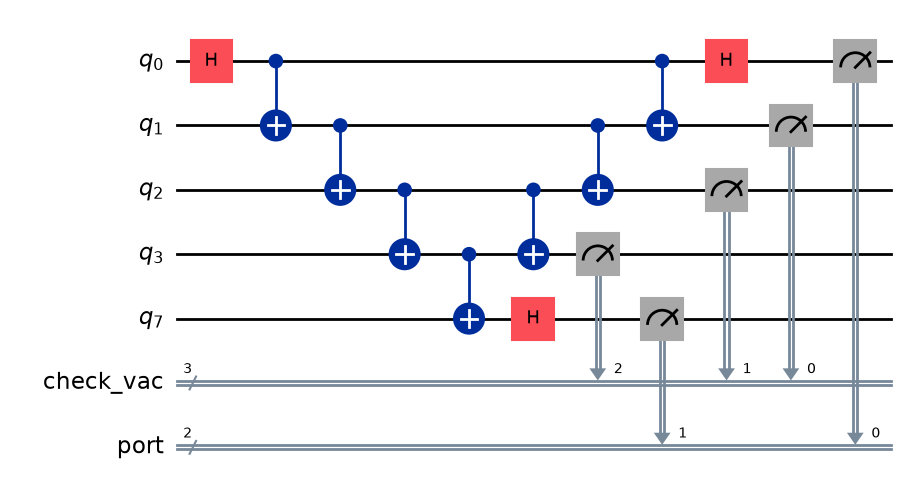

In [10]:
show(pipeline.basis_circuits)
circuits = pipeline.basis_circuits(run.circuit.circuit, run.nc.ports)
heading("Output: the XX circuit, as written")
fig = circuits["XX"].draw("mpl", idle_wires=False, fold=-1)
display(fig)
plt.close(fig)

#### Step 3. Compile, at optimization level 1

- **Does:** `compile_bases` compiles each basis circuit into the Target at optimization level 1, on the qubits as written, with the run's transpiler seed.
- **Why level 1:** from level 2, Qiskit deletes SWAP gates and measures each state where it already is. The measurement stays correct, but the move is skipped, so the baseline would score a better F without ever bringing the pair to the ports.
- **Fair to every circuit:** GHZ disentangling has no SWAP gates, so it compiles the same at either level.
- **Output:** the gate counts of each basis circuit, then case 5's baseline compiled at levels 1 and 2: its two-qubit gates, and which qubits it measures.

In [11]:
show(pipeline.compile_bases)
compiled = pipeline.compile_bases(circuits, run.nc, run.seeds["transpile"])
heading("Output: each basis circuit's gates, compiled at level 1")
gates = list(dict.fromkeys(g for c in compiled.values() for g in c.compiled.count_ops()))
md_table(["Gate", *compiled], [(g, *(c.compiled.count_ops().get(g, 0) for c in compiled.values())) for g in gates])

baseline = CircuitRun("baseline-contemporary", NOISE, SHOTS, BASE_SEED)
zz = pipeline.basis_circuits(baseline.circuit.circuit, baseline.nc.ports)["ZZ"]
levels = []
for level in (1, 2):
    out = generate_preset_pass_manager(optimization_level=level, target=baseline.nc.target,
                                       initial_layout=list(range(baseline.nc.num_qubits)),
                                       seed_transpiler=baseline.seeds["transpile"]).run(zz)
    measured = [out.find_bit(i.qubits[0]).index for i in out.data if i.operation.name == "measure"]
    levels.append((level, sum(n for gate, n in out.count_ops().items() if gate in ("cz", "cx", "swap")),
                   ", ".join(map(str, measured)), "yes" if measured == list(baseline.nc.ports) else "no"))
heading("Output: case 5's baseline compiled at levels 1 and 2")
md_table(["Optimization level", "Two-qubit gates", "Ports measured on qubits", "Pair on the ports"], levels)

---

**bellbench's code:** `bellbench.pipeline.compile_bases`, from [src/bellbench/pipeline.py, lines 117 to 146](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/pipeline.py#L117-L146)

```python
def compile_bases(circuits: Mapping[str, QuantumCircuit], nc: NoiseControl, seed: int) -> dict[str, Compiled]:
    """Compile each basis circuit at level 1 on the written physical qubits, under one transpiler seed."""
    _check_seed(seed, "transpiler seed")
    out = {}
    for basis, circuit in circuits.items():
        if circuit.num_qubits != nc.num_qubits:
            raise ValueError(
                f"the {basis} circuit has {circuit.num_qubits} qubits; it must be written on the processor's "
                f"{nc.num_qubits} physical qubits"
            )
        _check_operations_supported(circuit, basis, nc)
        pm = generate_preset_pass_manager(
            optimization_level=OPTIMIZATION_LEVEL,
            target=nc.target,
            initial_layout=list(range(nc.num_qubits)),
            seed_transpiler=seed,
        )
        try:  # the init stage translates too: it breaks every gate on three or more qubits into smaller ones
            initialised = StagedPassManager(stages=["init"], init=pm.init).run(circuit)
        except TranspilerError as err:
            raise _cannot_compile(basis, circuit, nc) from err
        routed = StagedPassManager(stages=["layout", "routing"], layout=pm.layout, routing=pm.routing).run(initialised)
        try:
            compiled = StagedPassManager(
                stages=["translation", "optimization"], translation=pm.translation, optimization=pm.optimization
            ).run(routed)
        except TranspilerError as err:
            raise _cannot_compile(basis, routed, nc) from err
        out[basis] = Compiled(basis, initialised.count_ops().get("swap", 0), routed, compiled)
    return out
```

---

**Output: each basis circuit's gates, compiled at level 1**

| Gate | XX | YY | ZZ |
|---|---|---|---|
| rz | 30 | 31 | 30 |
| sx | 15 | 16 | 15 |
| cz | 7 | 7 | 7 |
| measure | 5 | 5 | 5 |


---

**Output: case 5's baseline compiled at levels 1 and 2**

| Optimization level | Two-qubit gates | Ports measured on qubits | Pair on the ports |
|---|---|---|---|
| 1 | 19 | 0, 7 | yes |
| 2 | 10 | 1, 2 | no |


#### Step 4. Schedule

- **Does:** `schedule` gives every gate a start time and fills each wait with a timed delay, which the noise model turns into decay. It changes no gate, so a run's cost comes from step 3.
- **Why:** on hardware a qubit decays while it waits, so a fair run counts its waiting time.
- **Why as late as possible:** a qubit then waits in $\lvert 0\rangle$, which decay leaves unchanged, instead of waiting while it holds part of the pair. Every run is scheduled the same way.
- **Output:** the ZZ circuit's duration and delays, then its schedule as a timeline: one row per qubit that acts, one block per gate, coloured by gate, and a gap wherever the qubit waits. The long blocks at the end are the measurements.

---

**bellbench's code:** `bellbench.pipeline.schedule`, from [src/bellbench/pipeline.py, lines 215 to 223](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/pipeline.py#L215-L223)

```python
def schedule(circuit: QuantumCircuit, nc: NoiseControl) -> QuantumCircuit:
    """The compiled circuit scheduled as late as possible, its idle time padded with timed delays.

    A profile without durations (a depolarising one) has nothing to schedule,
    so the circuit comes back unchanged.
    """
    if not nc.has_durations:
        return circuit
    return PassManager([ALAPScheduleAnalysis(target=nc.target), PadDelay(target=nc.target)]).run(circuit)
```

---

**Output: the ZZ circuit's schedule**

the ZZ circuit takes 2.93 µs, with 14 delays filling idle time


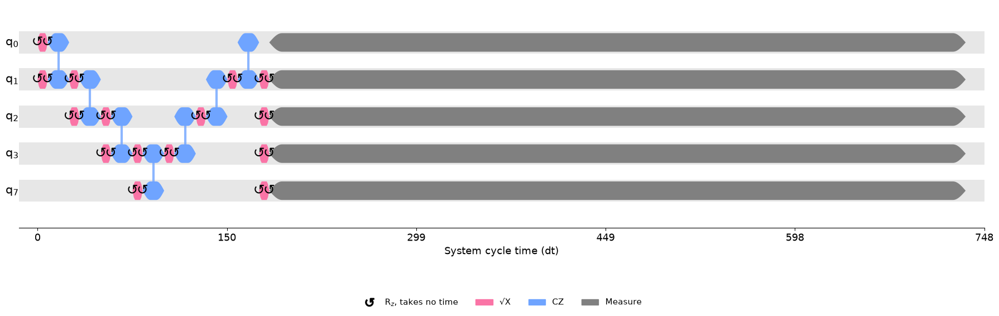

In [12]:
show(pipeline.schedule)
scheduled = {basis: pipeline.schedule(c.compiled, run.nc) for basis, c in compiled.items()}
heading("Output: the ZZ circuit's schedule")
print(f"the ZZ circuit takes {pipeline.scheduled_duration(scheduled['ZZ'], run.nc) * 1e6:.2f} µs, "
      f"with {sum(i.operation.name == 'delay' for i in scheduled['ZZ'].data)} delays filling idle time")
display(timeline_figure(compiled["ZZ"].compiled, run.nc))

#### Step 5. Simulate, then score

- **Does:** `simulate` runs the three scheduled circuits in one Aer job under the noise model, with the run's noisy seed.
- **Scoring:** a shot is kept when every vacancy read gave 0. Over the kept shots, each basis's correlator is the agreements minus the disagreements, divided by the shots kept, and $F = (1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle)/4$.
- **Output:** F with its standard error, and the acceptance.

In [13]:
show(pipeline.simulate)
show(fidelity.correlator_from_counts)
show(fidelity.bell_fidelity)
sim = pipeline.simulate(scheduled, run.nc.noise_model, SHOTS, run.seeds["noisy"])
registers = [(r.name, r.size) for r in compiled["ZZ"].compiled.cregs]
steps = Score(read_shots(run.circuit.analysis, sim.raw, registers, SHOTS))
heading("Output: F and acceptance, step by step")
print(f"step by step: F = {steps.accepted.value:.6f} ± {steps.accepted.standard_error:.6f}, acceptance {steps.acceptance:.6f}")

---

**bellbench's code:** `bellbench.pipeline.simulate`, from [src/bellbench/pipeline.py, lines 253 to 277](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/pipeline.py#L253-L277)

```python
def simulate(
    circuits: Mapping[str, QuantumCircuit],
    noise_model,
    shots: int,
    seed: int,
    method: str = "automatic",
) -> Simulation:
    """Run the basis circuits in one Aer job, ideal when `noise_model` is None, and return the port counts.

    Aer gives each circuit its own seed derived from `seed`; the seeds and the
    method it reports for each are returned, so a rerun can repeat them.
    """
    if isinstance(shots, bool) or not isinstance(shots, int) or shots < 1:
        raise ValueError(f"shots must be a positive integer; got {shots!r}")
    _check_seed(seed, "simulator seed")
    bases = list(circuits)
    simulator = AerSimulator(method=method, noise_model=noise_model, seed_simulator=seed)
    result = simulator.run([circuits[b] for b in bases], shots=shots).result()
    counts, seeds, methods, raw = {}, {}, {}, {}
    for i, basis in enumerate(bases):
        raw[basis] = dict(sorted(result.get_counts(i).items()))
        counts[basis] = register_counts(raw[basis], circuits[basis], PORT_REGISTER)
        seeds[basis] = int(result.results[i].seed_simulator)
        methods[basis] = str(result.results[i].metadata["method"])
    return Simulation(counts, seeds, methods, shots, raw)
```

---

**bellbench's code:** `bellbench.fidelity.correlator_from_counts`, from [src/bellbench/fidelity.py, lines 77 to 89](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/fidelity.py#L77-L89)

```python
def correlator_from_counts(counts: Mapping[str, int], basis: str = "") -> Correlator:
    """<BB> from one basis's two-bit port counts; warns and gives NaN when there are no shots."""
    unknown = set(counts) - set(OUTCOMES)
    if unknown:
        raise ValueError(f"port counts{_for(basis)} have keys other than {OUTCOMES}: {sorted(unknown)}")
    if any(not isinstance(n, (int, np.integer)) or isinstance(n, bool) or n < 0 for n in counts.values()):
        raise ValueError(f"port counts{_for(basis)} must be non-negative integers; got {dict(counts)}")
    shots = int(sum(counts.values()))
    if shots == 0:
        warnings.warn(f"basis {basis or '?'} kept no shots, so its correlator and F are undefined", stacklevel=2)
        return Correlator(math.nan, 0)
    agree = int(counts.get("00", 0) + counts.get("11", 0))
    return Correlator((2 * agree - shots) / shots, shots)
```

---

**bellbench's code:** `bellbench.fidelity.bell_fidelity`, from [src/bellbench/fidelity.py, lines 72 to 74](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/fidelity.py#L72-L74)

```python
def bell_fidelity(xx: float, yy: float, zz: float) -> float:
    """F(Phi+) = [1 + <XX> - <YY> + <ZZ>] / 4, the overlap of the pair's state with |Phi+>."""
    return (1 + xx - yy + zz) / 4
```

---

**Output: F and acceptance, step by step**

step by step: F = 0.981721 ± 0.000304, acceptance 0.977370


#### Step 6. The one call

- **Does:** `CircuitRun.run` does steps 1 to 5 in one call, with an ideal simulation beside the noisy one.
- **Why:** every later section makes its runs with it, through the benchmark runner and the workbench's views.
- **Output:** the same numbers three ways: this call, the steps above, and the run the repository recorded for case 6.

In [14]:
run.run()
f_rec, a_rec = noisy_scores(recorded(REPORTED) / "ghz-uncompute-vacancy-contemporary")
heading("Output: the same numbers three ways")
print(f"run.run():     F = {run.scores['noisy'].accepted.value:.6f}, acceptance {run.scores['noisy'].acceptance:.6f}")
print(f"step by step:  F = {steps.accepted.value:.6f}, acceptance {steps.acceptance:.6f}")
print(f"the record:    F = {f_rec:.6f}, acceptance {a_rec:.6f}")
print("the same numbers" if round(run.scores["noisy"].accepted.value, 12) == round(steps.accepted.value, 12)
      == round(f_rec, 12) else "DIFFERENT numbers")

---

**Output: the same numbers three ways**

run.run():     F = 0.981721, acceptance 0.977370
step by step:  F = 0.981721, acceptance 0.977370
the record:    F = 0.981721, acceptance 0.977370
the same numbers


#### The check: the same run in plain Qiskit

- **Does:** rebuilds the run without calling bellbench, then compares the noise model, the compiled gates, and F with the acceptance.
- **Why:** it shows bellbench adds no hidden step; every number comes from Qiskit and Aer.
- **Folded** in Colab and Jupyter, since it repeats steps 1 to 5: open it to see a run made with nothing but Qiskit.

In [15]:
#@title Check: the same run rebuilt in plain Qiskit and Aer, without bellbench
from qiskit import ClassicalRegister, qasm3
from qiskit.circuit.library import get_standard_gate_name_mapping
from qiskit.providers import BackendV2, Options
from qiskit.transpiler import InstructionProperties, PassManager, QubitProperties, Target
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, ReadoutError

# Step 1 by hand: read the two config files as plain YAML, the way any script would.
profile = yaml.safe_load((WORK / f"config/noise/bp.data.noise.{NOISE}.yaml").read_text())
graph = yaml.safe_load((WORK / "config/processor/bp.data.processor.contemporary.yaml").read_text())
n, qubit, readout = len(graph["qubits"]), profile["qubit"], profile["qubit"]["readout_error"]
couplers = [tuple(e) for e in graph["edges"]] + [tuple(reversed(e)) for e in graph["edges"]]  # a CZ either way

# The Target: every native gate on every qubit or coupler, each with Boston's median error and duration, every qubit
# with the same T1 and T2, then the measurement, reset and delay. Its measurement error is the mean of the two readout
# directions; the noise model below replaces it with both directions.
gate = get_standard_gate_name_mapping()
target = Target(num_qubits=n, dt=profile["time_step"],
                qubit_properties=[QubitProperties(t1=qubit["t1_relaxation_time"], t2=qubit["t2_dephasing_time"])] * n)
for name, spec in profile["gates"].items():
    where = couplers if spec["qubits"] == 2 else [(i,) for i in range(n)]
    target.add_instruction(gate[name], {w: InstructionProperties(error=spec["error_probability"], duration=spec["duration"])
                                        for w in where})
target.add_instruction(gate["measure"], {(i,): InstructionProperties(
    error=(readout["reads_1_when_0"] + readout["reads_0_when_1"]) / 2, duration=profile["measure"]["duration"]) for i in range(n)})
target.add_instruction(gate["reset"], {(i,): InstructionProperties(duration=profile["reset"]["duration"]) for i in range(n)})
target.add_instruction(gate["delay"], {(i,): None for i in range(n)})


class TargetOnly(BackendV2):
    """A backend that carries only the Target, so Aer can read a noise model from it."""

    def __init__(self, target):
        super().__init__(name="target-only")
        self._target = target

    target = property(lambda self: self._target)
    max_circuits = property(lambda self: None)
    _default_options = classmethod(lambda cls: Options())

    def run(self, *args, **kwargs):
        raise NotImplementedError("this backend only carries a Target")


# Aer builds the gate errors and the relaxation, during gates and idle delays alike, from the Target. Readout is left
# out there and added per qubit here, with its two directions apart: reads 1 when 0, and reads 0 when 1.
noise_model = NoiseModel.from_backend(TargetOnly(target), readout_error=False)
p10, p01 = readout["reads_1_when_0"], readout["reads_0_when_1"]
for i in range(n):
    noise_model.add_readout_error(ReadoutError([[1 - p10, p10], [p01, 1 - p01]]), [i])
heading("Check 1: the noise model")
print("the same noise model as bellbench's:", noise_model == run.nc.noise_model)

# Step 2 by hand: the written circuit, three times, each with its basis rotation on the ports and a 2-bit "port"
# register measuring them. ZZ measures as is, XX applies H first, and YY applies S dagger then H.
written = qasm3.loads(yaml.safe_load((WORK / "config/circuit/bp.data.circuit.ghz-uncompute-vacancy-contemporary.yaml").read_text())["circuit"])
a, b = graph["ports"]


def gates_of(circuit):
    """Each instruction as (name, physical qubits, parameters), to compare two circuits whatever their register names."""
    return [(i.operation.name, tuple(circuit.find_bit(q).index for q in i.qubits), tuple(map(float, i.operation.params)))
            for i in circuit.data]


heading("Check 2: the compiled gates")
by_hand = {}
for basis in BASES:
    circuit = written.copy()
    port = ClassicalRegister(2, "port")
    circuit.add_register(port)
    for q in (a, b):
        if basis == "YY":
            circuit.sdg(q)
        if basis in ("XX", "YY"):
            circuit.h(q)
    circuit.measure([a, b], [port[0], port[1]])
    # Steps 3 and 4 by hand: compile at level 1 on the qubits as written, with bellbench's transpiler seed, then
    # schedule as late as possible and fill each idle period with a delay.
    hand = generate_preset_pass_manager(optimization_level=1, target=target, initial_layout=list(range(n)),
                                        seed_transpiler=run.seeds["transpile"]).run(circuit)
    by_hand[basis] = PassManager([ALAPScheduleAnalysis(target=target), PadDelay(target=target)]).run(hand)
    print(f"{basis}: the same gates on the same qubits as bellbench's:", gates_of(hand) == gates_of(run.compiled[basis].compiled))

# Step 5 by hand: one Aer job runs the three scheduled circuits with bellbench's noisy seed, so the shots match
# shot for shot.
counts = AerSimulator(noise_model=noise_model, seed_simulator=run.seeds["noisy"]).run(
    [by_hand[basis] for basis in BASES], shots=SHOTS).result().get_counts()


def correlator(counts):
    """The basis's correlator over the kept shots. Each count's key holds one bit string per register, the port
    register first, since it was added last; the rest are the vacancy reads. A shot is kept when every read gave 0,
    and adds +1 when the two port bits agree and -1 when they differ."""
    kept = {}
    for key, k in counts.items():
        ports, *checks = key.split()
        if set("".join(checks)) <= {"0"}:
            kept[ports] = kept.get(ports, 0) + k
    total = sum(kept.values())
    return sum((1 if bits[0] == bits[1] else -1) * k for bits, k in kept.items()) / total, total


# F from the three correlators, as in section 3, and the acceptance: the kept shots over every shot run.
(xx, kx), (yy, ky), (zz_, kz) = (correlator(c) for c in counts)
f_hand, acceptance_hand = (1 + xx - yy + zz_) / 4, (kx + ky + kz) / (3 * SHOTS)
heading("Check 3: F and acceptance")
print(f"plain Qiskit: F = {f_hand:.6f}, acceptance {acceptance_hand:.6f}")
print(f"bellbench:    F = {run.scores['noisy'].accepted.value:.6f}, acceptance {run.scores['noisy'].acceptance:.6f}")
print("the same numbers" if (round(f_hand, 12), round(acceptance_hand, 12)) == (round(run.scores["noisy"].accepted.value, 12),
      round(run.scores["noisy"].acceptance, 12)) else "DIFFERENT numbers")

---

**Check 1: the noise model**

the same noise model as bellbench's: True


---

**Check 2: the compiled gates**

XX: the same gates on the same qubits as bellbench's: True
YY: the same gates on the same qubits as bellbench's: True
ZZ: the same gates on the same qubits as bellbench's: True


---

**Check 3: F and acceptance**

plain Qiskit: F = 0.981721, acceptance 0.977370
bellbench:    F = 0.981721, acceptance 0.977370
the same numbers


---

## 3. The task

**On each of three processor graphs, create the Bell pair $\lvert\beta_{00}\rangle = (\lvert 00\rangle + \lvert 11\rangle)/\sqrt{2}$ between two fixed qubits, the ports, measure how close it comes, and test one strategy that protects it.**

- **Why it is hard:** a two-qubit gate acts only between neighbours on the graph, so a pair made at one port must be moved to the other, and each added gate adds noise.
- **How close it comes:** we measure the two ports in three bases and combine the three correlators into the fidelity. F = 1 is the target exactly; F above 1/2 shows entanglement.

$$F = \frac{1 + \langle XX\rangle - \langle YY\rangle + \langle ZZ\rangle}{4}$$

**The nine cases:** each graph under three conditions.

| Graph | Ideal | Noisy | Noisy, protected |
|---|---|---|---|
| 2016-inspired | Case 1 | Case 2 | Case 3 |
| Contemporary | Case 4 | Case 5 | Case 6 |
| Hyperbolic-inspired | Case 7 | Case 8 | Case 9 |

<details><summary><b>The linear algebra behind the formula</b></summary>

**The states**

- A qubit's state is a unit vector in $\mathbb{C}^2$; two qubits share one in $\mathbb{C}^4$, with basis $\lvert 00\rangle$, $\lvert 01\rangle$, $\lvert 10\rangle$ and $\lvert 11\rangle$.
- The target, $\lvert\beta_{00}\rangle = (\lvert 00\rangle + \lvert 11\rangle)/\sqrt{2}$, is the vector $(1, 0, 0, 1)/\sqrt{2}$.
- The other three Bell states: $\lvert\beta_{01}\rangle = (\lvert 01\rangle + \lvert 10\rangle)/\sqrt{2}$, $\lvert\beta_{10}\rangle = (\lvert 00\rangle - \lvert 11\rangle)/\sqrt{2}$ and $\lvert\beta_{11}\rangle = (\lvert 01\rangle - \lvert 10\rangle)/\sqrt{2}$.

**The Pauli matrices**

- X = [[0, 1], [1, 0]], Y = [[0, -i], [i, 0]] and Z = [[1, 0], [0, -1]].

**The correlators**

- $\langle BB\rangle$ is the expectation value of $B \otimes B$ in the pair's state $\rho$: $\mathrm{Tr}(\rho\,(B \otimes B))$, for $B$ one of $X$, $Y$ and $Z$.
- From shots: $\langle BB\rangle = P(00) + P(11) - P(01) - P(10)$.

**Why the formula gives F**

- $\lvert\beta_{00}\rangle\langle\beta_{00}\rvert = (I \otimes I + X \otimes X - Y \otimes Y + Z \otimes Z)/4$, so $F = \langle\beta_{00}\rvert\,\rho\,\lvert\beta_{00}\rangle$, the overlap of the prepared state with the target, is the formula above.

**What each basis sees**

- ZZ sees a bit flip, XX a phase flip, and YY either; all three together tell $\lvert\beta_{00}\rangle$ from the other three Bell states.

**Why 1/2**

- A state that is not entangled cannot have F above 1/2, so 1/2 is the line a classical correlation cannot cross.

The full statement of the task, with its sources, is [CHALLENGE.md](https://github.com/Rickory2021/bell-transport-bench/blob/submission/docs/CHALLENGE.md).

</details>

### 3.1 What each run reports

**Each case reports F with its standard error, the acceptance (the fraction of shots kept), and the circuit's cost,** as the challenge's five measures require. Each run takes 100,000 shots per basis, simulated ideal and noisy with seeds derived from one base seed, 20261116, so every run repeats exactly.

- **F after postselection** is F of the kept shots; **F raw** is F of every shot. A protected result is never shown without its acceptance.
- **Standard error:** a correlator c from N shots has variance $(1 - c^2)/N$; the three bases are separate shots, so $\mathrm{SE}(F) = \sqrt{\sum \mathrm{var}}/4$, with N the kept shots. Two runs differ by more than chance when their difference exceeds about two combined standard errors, $\sqrt{\mathrm{SE}_1^2 + \mathrm{SE}_2^2}$; this notebook gives each difference in those units.
- **Cost:** two-qubit gates, depth, SWAPs and qubits used, from the compiled circuit before scheduling, and the scheduled duration.
- **Two-qubit gates per accepted pair:** the gates divided by the acceptance, what each kept pair costs.
- **Infidelity removed per rejection:** $(F - F_{\mathrm{raw}})/(1 - p)$, how much a check lowers $1 - F$ for each unit of shots it discards.

---

## 4. Configuration

**The files that define every run: the three graphs, the noise model with what it leaves out, the benchmark file and the circuits.** Each file is shown, folded, as the repository holds it, except the four [section 2](#2.-How-bellbench-makes-a-run) shows.

### 4.1 The three processor graphs

**We use the organisers' three coupling graphs exactly, with the ports they fix, and explain results by three features of each graph:** the hops between the ports, the paths between the ports that share no qubit (disjoint paths), and the most edges at any qubit. The 2016-inspired and hyperbolic-inspired processor files come first, the contemporary one being in [section 2](#2.-How-bellbench-makes-a-run); the figure and the table are drawn from all three.

<details><summary><b>config/processor/bp.data.processor.ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/processor/bp.data.processor.ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/processor/bp.data.processor.ibm2016.yaml
#
# The 2016-inspired reference processor model, the organisers' graph (docs/DESIGN.md, section 3).
# Validated by config/bp.schema.processor.yaml.

name: ibm2016
label: 2016-inspired reference
reference: ideal-and-noisy-example
notes: >-
  The organisers' example notebook, section 1 (the models cell), gives the T graph
  as an edge list with its ports; the organisers stated at the event that the
  graphs are exact. Ids and positions are the notebook's: slide 4's drawings carry
  no qubit numbers, so the notebook labels the qubits by position.
qubits:
  - {id: 0, position: [0, 2]}
  - {id: 1, position: [-1.55, 0.75]}
  - {id: 2, position: [1.55, 0.75]}
  - {id: 3, position: [0, -0.45]}
  - {id: 4, position: [0, -2]}
ports: [0, 4]
edges:
  - [0, 1]
  - [0, 2]
  - [0, 3]
  - [3, 4]
```

</details>

<details><summary><b>config/processor/bp.data.processor.hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/processor/bp.data.processor.hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/processor/bp.data.processor.hyperbolic.yaml
#
# The Hyperbolic-inspired processor model, the organisers' graph (docs/DESIGN.md, section 3).
# Validated by config/bp.schema.processor.yaml.

name: hyperbolic
label: Hyperbolic-inspired model
reference: ideal-and-noisy-example
notes: >-
  The organisers' example notebook, section 1 (the models cell), gives the 13-node graph
  as an edge list with its ports; the organisers stated at the event that the
  graphs are exact. Ids and positions are the notebook's: slide 4's drawings carry
  no qubit numbers, so the notebook labels the qubits by position.
qubits:
  - {id: 0, position: [0, 2.08]}
  - {id: 1, position: [-2, 1.14]}
  - {id: 2, position: [0, 1.14]}
  - {id: 3, position: [2, 1.14]}
  - {id: 4, position: [-1, 0.59]}
  - {id: 5, position: [1, 0.59]}
  - {id: 6, position: [0, 0]}
  - {id: 7, position: [-1, -0.59]}
  - {id: 8, position: [1, -0.59]}
  - {id: 9, position: [-2, -1.14]}
  - {id: 10, position: [0, -1.14]}
  - {id: 11, position: [2, -1.14]}
  - {id: 12, position: [0, -2.08]}
ports: [0, 12]
edges:
  - [0, 1]
  - [0, 3]
  - [1, 9]
  - [3, 11]
  - [9, 12]
  - [11, 12]
  - [2, 4]
  - [2, 5]
  - [4, 7]
  - [5, 8]
  - [7, 10]
  - [8, 10]
  - [0, 2]
  - [1, 4]
  - [3, 5]
  - [7, 9]
  - [8, 11]
  - [10, 12]
  - [2, 6]
  - [4, 6]
  - [5, 6]
  - [6, 7]
  - [6, 8]
  - [6, 10]
```

</details>

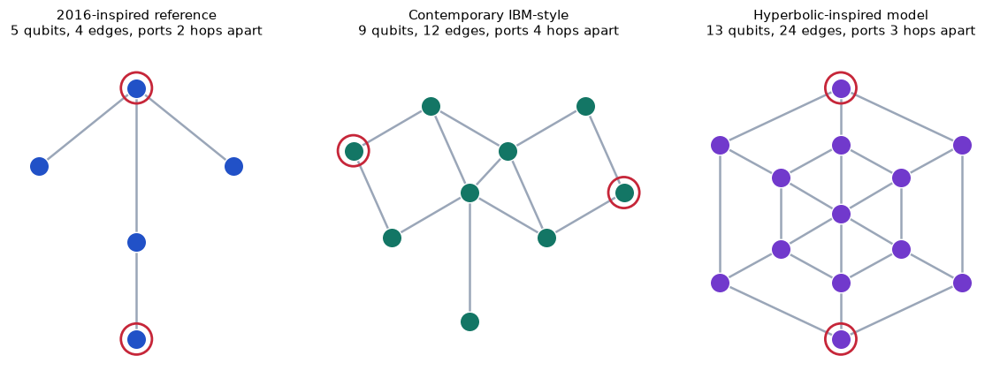

,hops between ports,disjoint paths,most edges at a qubit,pair's path
ibm2016,2,1,3,"[0, 3, 4]"
contemporary,4,2,5,"[0, 1, 2, 3, 7]"
hyperbolic,3,3,6,"[0, 1, 9, 12]"


In [16]:
from bellbench.figures import processor_figure
from bellbench.paths import graph_metrics

fig = processor_figure()
display(fig)
plt.close(fig)
pd.DataFrame(
    {p: {k: graph_metrics(p)[k] for k in ("port_distance", "disjoint_paths", "max_degree", "path")}
     for p in configs.CORE_PROCESSORS}
).T.rename(columns={"port_distance": "hops between ports", "disjoint_paths": "disjoint paths",
                   "max_degree": "most edges at a qubit", "path": "pair's path"})

### 4.2 The noise model

**Our noise model uses the calibration values of IBM's Boston processor, taken from the FakeBoston snapshot recorded on 2026-04-17.** Aer's own `NoiseModel.from_backend` builds the gate, decay and reset channels from a Target holding those values, and the model then replaces Aer's readout errors with the profile's, which differ in the two directions ([`src/bellbench/noise.py`](https://github.com/Rickory2021/bell-transport-bench/blob/submission/src/bellbench/noise.py)). Each value is the median over the snapshot's qubits and couplers, and every qubit and coupler of all three graphs takes it, so the graphs differ in connectivity alone. Nothing here ran on hardware.

- **Modelled:** gate errors, decay (T1 and T2) during gates and while idle, and readout errors that differ in the two directions. Circuits are scheduled before noise is applied, so a qubit waiting for a 2.2 µs measurement decays while it waits.
- **Set per run, by none of the nine cases:** a mid-circuit measurement error, for a circuit that reads a qubit and then uses it again. No case does; the earlier XX check on the 2016-inspired graph, which section 6.1 runs for comparison, sets it to 0.01. One run per graph in section 6 also sets the readout error of the qubits it reads to 0, to test what readout costs.

The noise profile is shown in [section 2](#2.-How-bellbench-makes-a-run); its values:

In [17]:
profile = configs.load_noise("boston-2026")
q, g = profile["qubit"], profile["gates"]
pd.DataFrame(
    [("T1", q["t1_relaxation_time"] * 1e6, "µs"), ("T2", q["t2_dephasing_time"] * 1e6, "µs"),
     ("reads 1 when 0", q["readout_error"]["reads_1_when_0"], ""), ("reads 0 when 1", q["readout_error"]["reads_0_when_1"], ""),
     ("CZ error", g["cz"]["error_probability"], ""), ("CZ duration", g["cz"]["duration"] * 1e9, "ns"),
     ("√X error", g["sx"]["error_probability"], ""), ("measurement", profile["measure"]["duration"] * 1e6, "µs")],
    columns=["quantity", "value", "unit"],
).set_index("quantity")

,value,unit
quantity,,
T1,292.435651,µs
T2,352.969600,µs
reads 1 when 0,0.003906,
reads 0 when 1,0.004883,
CZ error,0.001275,
CZ duration,68.000000,ns
√X error,0.000145,
measurement,2.200000,µs


<details><summary><b>What the model leaves out</b></summary>

**The calibration snapshot gives one number per gate, per qubit's readout and per qubit's T1 and T2, and the model uses only those, so every effect below is left out.** [DESIGN.md, section 4](https://github.com/Rickory2021/bell-transport-bench/blob/submission/docs/DESIGN.md#4-noise-model) holds the full noise model.

- **Qubits that start a shot excited:** a qubit begins in $\lvert 1\rangle$ instead of $\lvert 0\rangle$. A run can set it as a conditional channel, but the snapshot gives no value for it, and no run here sets it.
- **Measurement-induced dephasing:** reading one qubit disturbs its neighbours' phase. The snapshot gives no value for it; every read in the nine cases is at the end of the circuit.
- **Always-on ZZ coupling:** neighbours keep a small interaction while idle. The snapshot gives no value for it; an idle qubit here only decays.
- **Spectator errors:** a gate disturbs the qubits next to the ones it acts on. The snapshot gives each gate's error on its own qubits only.
- **Coherent errors:** systematic over- or under-rotations that add up instead of averaging out. The snapshot gives each gate's error as one rate, with no angle, so the model applies it as a random error.
- **Drift:** calibration values change over time. One snapshot is one moment; every run uses the same values, so the three graphs compare under the same noise.
- **Feedforward latency:** the delay before a circuit can act on a mid-circuit result. No case acts on a result during the circuit; every read is used after the shot.
- **Cosmic-ray bursts:** rare events that raise error rates across a chip at once. They correlate errors across qubits and shots, which a per-gate, per-shot model cannot express.
- **Leakage:** a qubit leaving $\lvert 0\rangle$ and $\lvert 1\rangle$ for a higher level. The simulator treats each qubit as two-level, and the snapshot gives no value for it.
- **Frequency crowding:** qubits with close frequencies disturbing each other. The snapshot gives no coupling between qubit frequencies.

</details>

### 4.3 The benchmark

**One benchmark file fills the nine cases: it names each run, a circuit file under the noise profile, the shots and the base seed, and which run fills each case.** Cases 1, 2, 4, 5, 7 and 8 are our baseline, the SWAP circuit; cases 3, 6 and 9 are our protection, the same steps on every graph. The file runs nothing else. To separate what the transport buys from what the check buys, section 5.2 takes the transport without the check from each graph's extended benchmark (section 6), which runs it under the same shots and seed. Each run takes 100,000 shots per basis. The notebook makes the benchmark itself at the end of section 4.4, once its circuit files are written.

<details><summary><b>config/benchmark/bp.data.benchmark.deliverable-2026-11-17.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.deliverable-2026-11-17.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.deliverable-2026-11-17.yaml

name: deliverable-2026-11-17
label: GHZ disentangling with a vacancy read, the nine cases
notes: >-
  The challenge's nine cases (docs/CHALLENGE.md, The nine core cases) as the
  submission reports them, under boston-2026 as in the core benchmark, so the three
  graphs differ only in connectivity. Cases 1, 2, 4, 5, 7 and 8 are the organisers'
  baseline, exactly as the core benchmark runs it. Cases 3, 6 and 9 are one protection
  strategy, the same builder steps on every graph: ghz_uncompute makes a GHZ state
  along the pair's path, then disentangles the path's interior qubits with gates
  controlled from the first port, leaving them in |0>; vacancy then reads them at the
  end of the circuit, and postselection discards each shot where any reads 1. The read
  catches a bit flip on the interior qubits, and on the first port before the last
  gate, which copies it onto an interior qubit; it cannot see a phase flip. No qubit
  is read mid-circuit, so no case needs the mid-circuit measurement channel. The file runs only the runs that fill a case. Each graph's extended
  benchmark, deliverable-2026-11-17-extended-<processor>, runs the same protected case
  beside the alternatives under the same shots and seed, among them the transport
  without the read, so the submission separates what the transport buys from what the
  read buys. Every run takes 100,000 shots per basis, five times the core's 20,000, so
  F's standard error is about 0.0003 and a difference of 0.001 between two runs stands
  at more than two combined standard errors; the baseline cases therefore agree with
  the core's within their errors rather than repeating its numbers.
shots: 100000
base_seed: 20261116
runs:
  # The reference: the organisers' baseline.
  - {run: baseline-ibm2016, circuit: baseline-ibm2016, noise: boston-2026}
  - {run: baseline-contemporary, circuit: baseline-contemporary, noise: boston-2026}
  - {run: baseline-hyperbolic, circuit: baseline-hyperbolic, noise: boston-2026}
  # The protection: the transport with its vacancy read at the end.
  - {run: ghz-uncompute-vacancy-ibm2016, circuit: ghz-uncompute-vacancy-ibm2016, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-contemporary, circuit: ghz-uncompute-vacancy-contemporary, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-hyperbolic, circuit: ghz-uncompute-vacancy-hyperbolic, noise: boston-2026}
cases:
  - {case: 1, run: baseline-ibm2016, simulation: ideal}
  - {case: 2, run: baseline-ibm2016, simulation: noisy}
  - {case: 3, run: ghz-uncompute-vacancy-ibm2016, simulation: noisy}
  - {case: 4, run: baseline-contemporary, simulation: ideal}
  - {case: 5, run: baseline-contemporary, simulation: noisy}
  - {case: 6, run: ghz-uncompute-vacancy-contemporary, simulation: noisy}
  - {case: 7, run: baseline-hyperbolic, simulation: ideal}
  - {case: 8, run: baseline-hyperbolic, simulation: noisy}
  - {case: 9, run: ghz-uncompute-vacancy-hyperbolic, simulation: noisy}
```

</details>

### 4.4 The circuits, written and compiled

**Each run is one circuit file: an OpenQASM 3 circuit on the graph's physical qubits, and how its measured bits are read.** One transport and one check, besides the baseline, fill the nine cases:

- **Baseline, the SWAP circuit (cases 1, 2, 4, 5, 7, 8):** the baseline we chose: H and CX at one port, SWAPs out to the other port and back, each SWAP three CX gates. It follows the routing in the organisers' example notebook, a reference rather than a requirement, and uses the same number of two-qubit gates: 7, 19 and 13 on the 2016-inspired, contemporary and hyperbolic-inspired graphs.
- **GHZ disentangling, our transport, `ghz-uncompute` in file names:** H on the first port, then a chain of CX gates along the path copies its bit onto every qubit, giving the GHZ state $(\lvert 0\ldots0\rangle + \lvert 1\ldots1\rangle)/\sqrt{2}$ on the whole path. A second chain of CX gates walks back towards the first port, each gate controlled by the qubit before it, and returns every interior qubit to $\lvert 0\rangle$, so only the two ports keep the shared bit: the Bell pair. The last of these gates is controlled by the first port. Liao et al. build a long-range CNOT the same way, preparing a GHZ state and disentangling it with gates ([arXiv:2411.14638](https://arxiv.org/abs/2411.14638)).
- **Vacancy read (cases 3, 6, 9), `vacancy` in file names:** after the transport, each interior qubit is measured in the Z basis at the end of the circuit. Each should read 0, so a shot where any reads 1 is discarded. A bit flip on an interior qubit reads 1, and so does a bit flip on the first port before the last gate, which copies it onto an interior qubit. The read cannot see a phase flip, and it adds no gate and no qubit.

For each graph, the two circuits its cases use, then the transport alone that section 5.2 makes, each as the repository holds it, then as the workbench shows it: the graph with the couplers the circuit uses, the written circuit and its cost, then two dropdowns: a step-through of the written circuit with no noise, and the compiled circuits, with a dropdown for each basis holding its compiled circuit, a timeline of when each qubit is busy, and the circuit as OpenQASM 3 (challenge material 02). Each view compiles its circuit here, as a run does, at optimization level 1 into Boston's native gates (`cz`, `sx`, `x` and `rz`), without simulating.

#### The 2016-inspired graph: cases 1 to 3

<details><summary><b>config/circuit/bp.data.circuit.baseline-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.baseline-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.baseline-ibm2016.yaml

name: baseline-ibm2016
label: Baseline, 2016-inspired reference
processor: ibm2016
analysis:
  name: postselect
notes: >-
  The baseline transport (swap_chain in src/bellbench/circuits.py), the organisers'
  recipe: H on the first port, explicit SWAPs out along the path [0, 3, 4], the lexicographically
  smallest shortest path between the ports, CX onto the second port, and the same
  SWAPs back, so the pair ends on the ports. No checks, so postselection keeps every
  shot.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[5] q;
  h q[0];
  swap q[0], q[3];
  cx q[3], q[4];
  swap q[0], q[3];
```

</details>

**baseline-ibm2016**: Baseline, 2016-inspired reference  
ibm2016, ports 0 and 4, 2 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

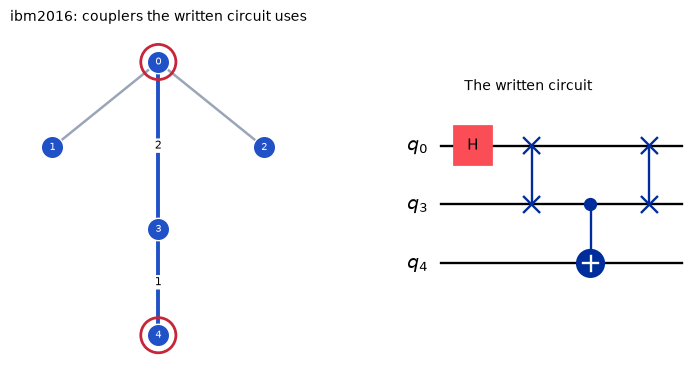

Cost: 7 two-qubit gates · 2 SWAPs (0 by the router) · depth 15 · 3 qubits (0, 3, 4) · 2.868 µs · pair on the ports ✓

,swap,h,cx,sx,cz,rz,measure
written,2,1,1,0,0,0,0
compiled ZZ,0,0,0,14,7,6,2
compiled XX,0,0,0,14,7,6,2
compiled YY,0,0,0,15,7,7,2



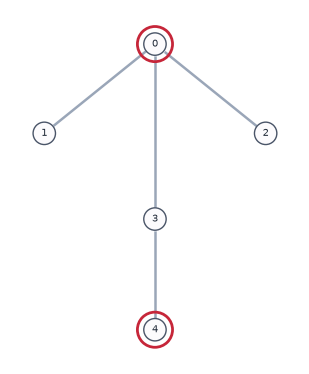
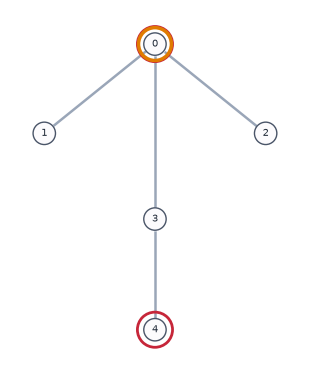
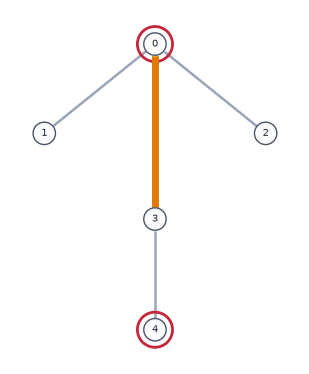
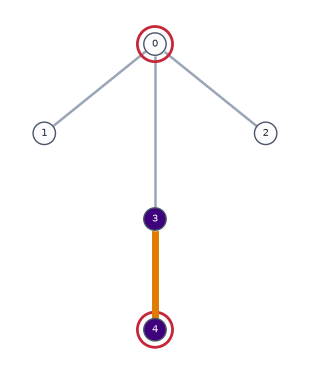
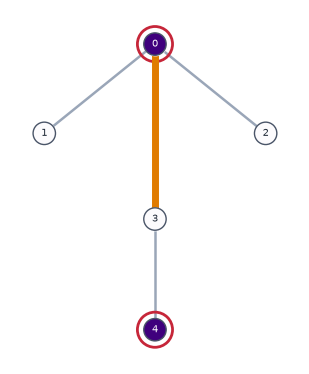


...
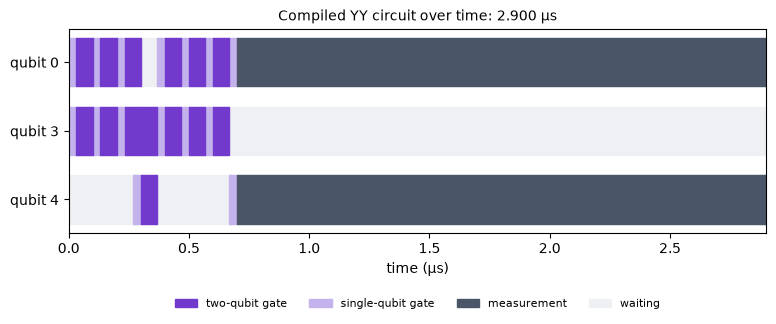
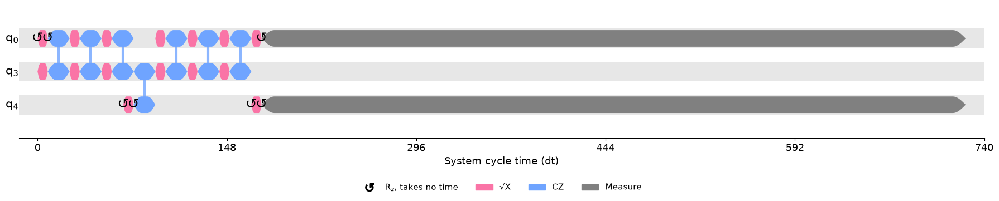
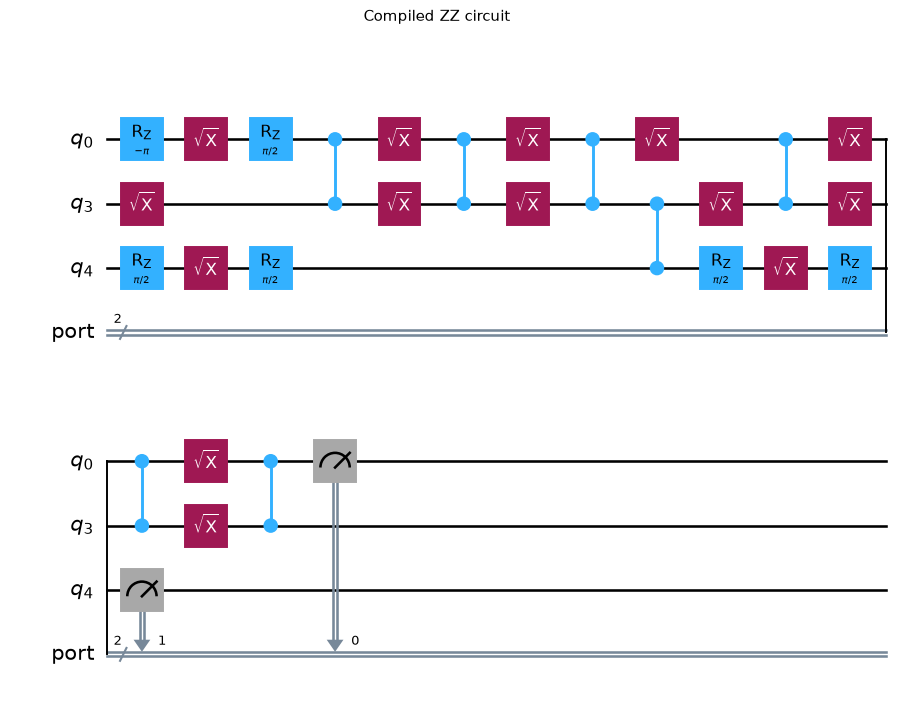
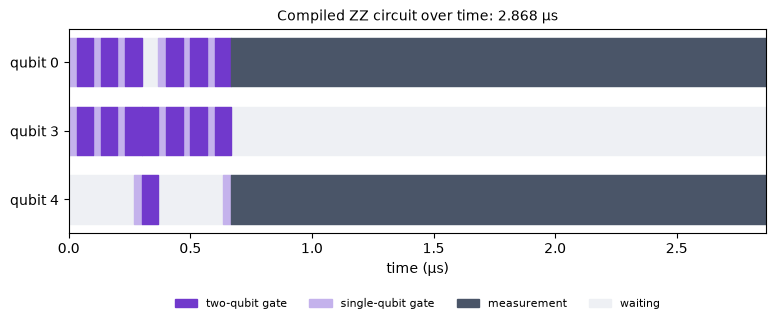
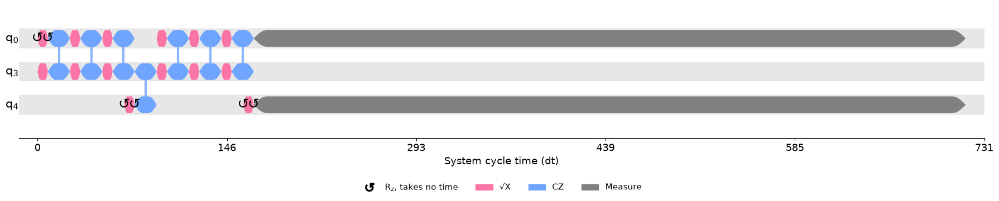

In [18]:
circuit_views("baseline-ibm2016")

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-vacancy-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-vacancy-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-vacancy-ibm2016.yaml

name: ghz-uncompute-vacancy-ibm2016
label: ghz_uncompute then vacancy at the end, ibm2016
processor: ibm2016
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: ghz_uncompute();
  then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[1] check_vac;
  qubit[5] q;
  h q[0];
  cx q[0], q[3];
  cx q[3], q[4];
  cx q[0], q[3];
  check_vac[0] = measure q[3];
```

</details>

**ghz-uncompute-vacancy-ibm2016**: ghz_uncompute then vacancy at the end, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `parity`, 1 check group · compiled now under boston-2026, base seed 20261116

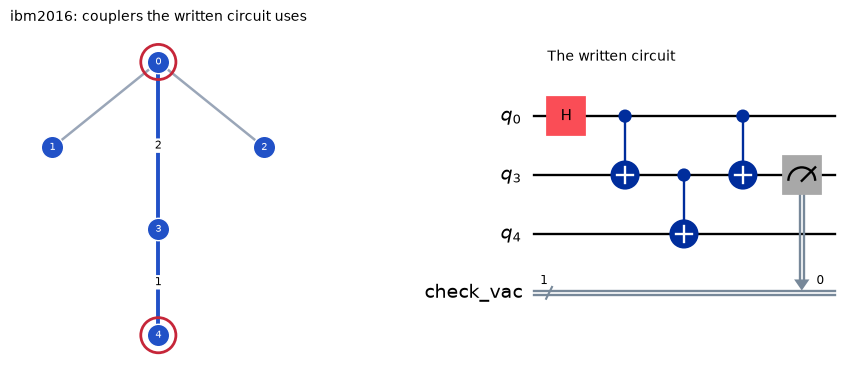

Cost: 3 two-qubit gates · 0 SWAPs (0 by the router) · depth 15 · 3 qubits (0, 3, 4) · 2.532 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,3,1,0,0,0,1
compiled ZZ,0,0,14,7,3,3
compiled XX,0,0,14,7,3,3
compiled YY,0,0,15,8,3,3



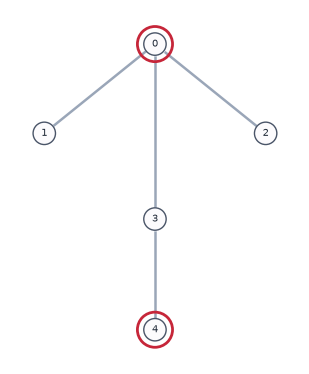
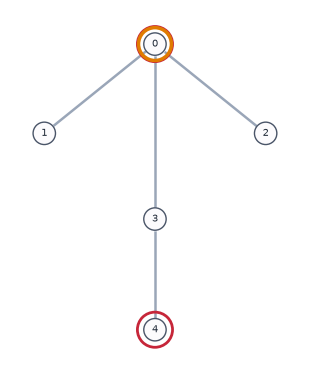
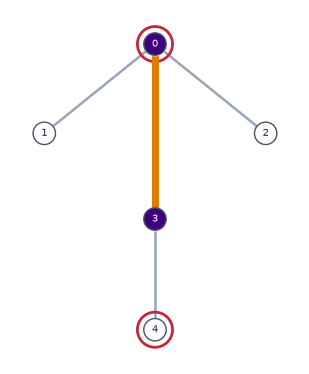
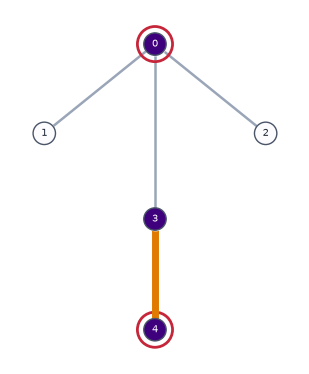
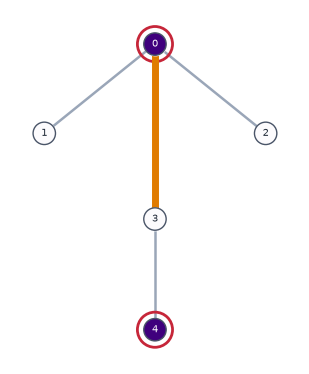


...
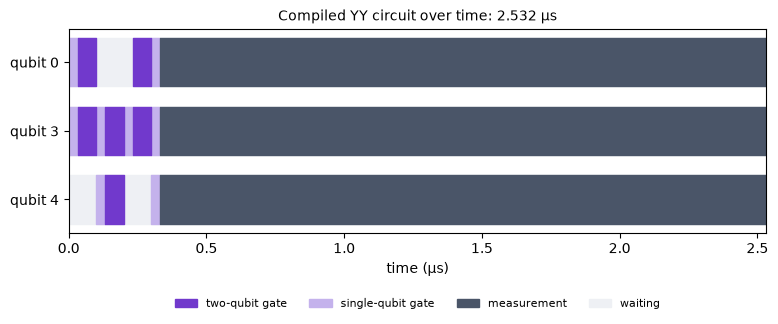
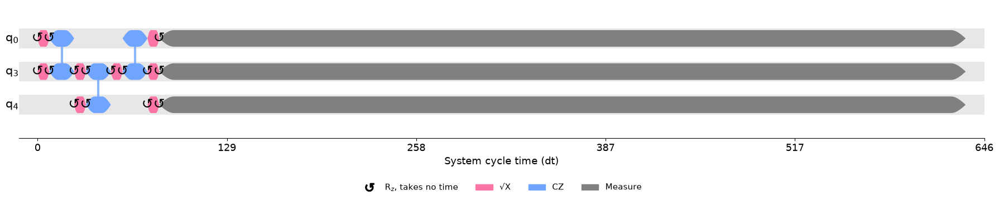
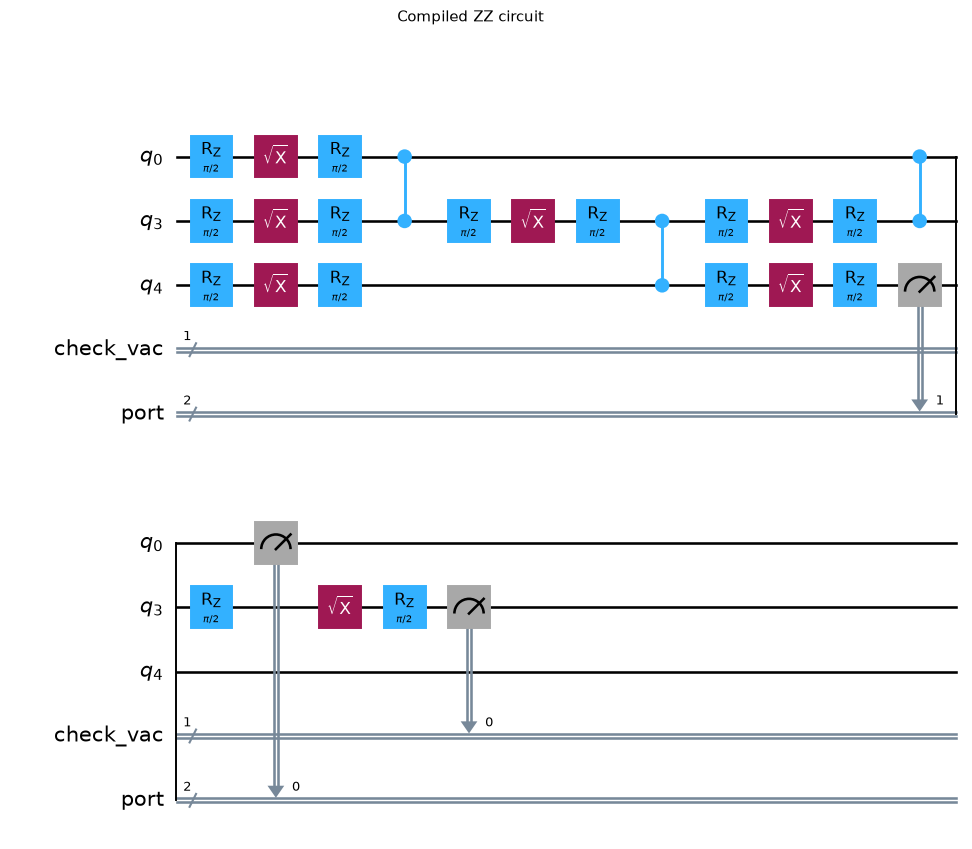
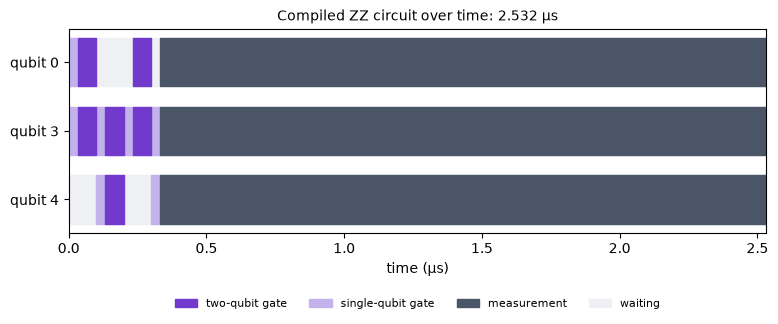
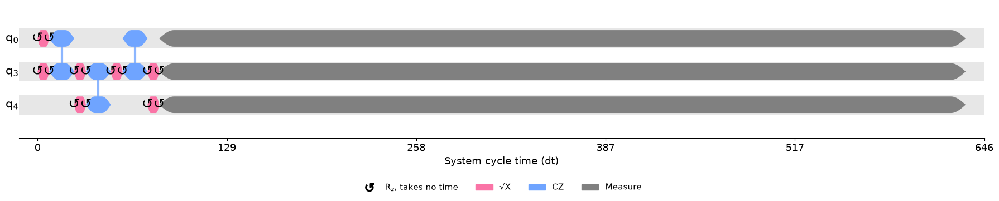

In [19]:
circuit_views("ghz-uncompute-vacancy-ibm2016")

The transport alone, GHZ disentangling without the read:

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-ibm2016.yaml

name: ghz-uncompute-ibm2016
label: ghz_uncompute, ibm2016
processor: ibm2016
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: ghz_uncompute().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[5] q;
  h q[0];
  cx q[0], q[3];
  cx q[3], q[4];
  cx q[0], q[3];
```

</details>

**ghz-uncompute-ibm2016**: ghz_uncompute, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

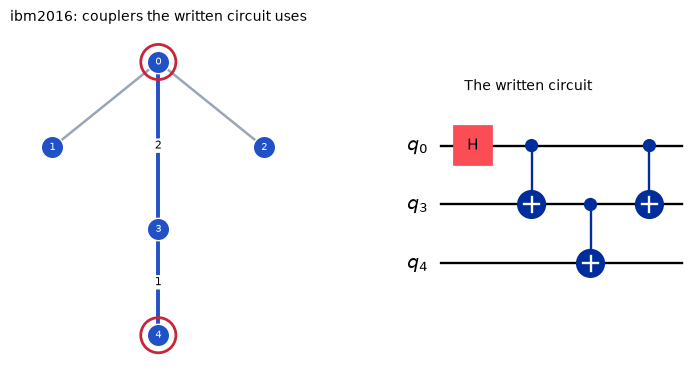

Cost: 3 two-qubit gates · 0 SWAPs (0 by the router) · depth 15 · 3 qubits (0, 3, 4) · 2.500 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,3,1,0,0,0,0
compiled ZZ,0,0,14,7,3,2
compiled XX,0,0,14,7,3,2
compiled YY,0,0,15,8,3,2



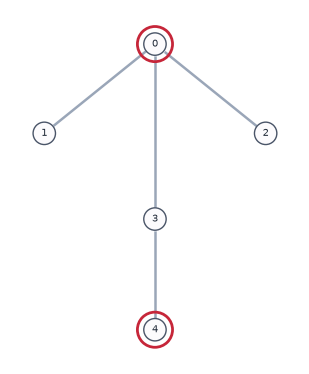
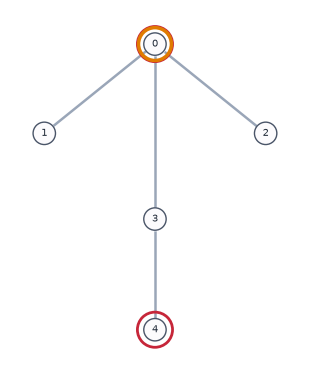
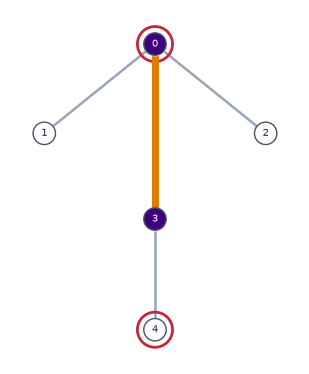
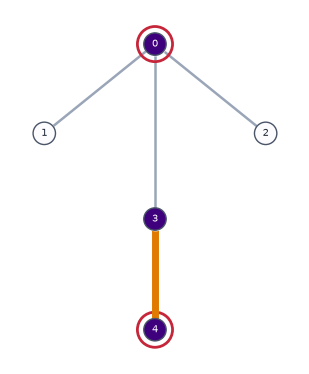
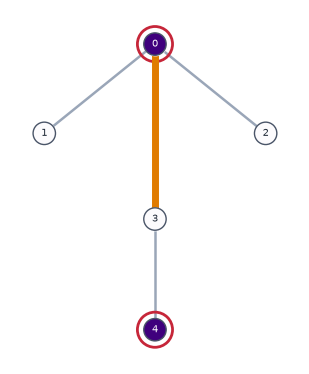


...
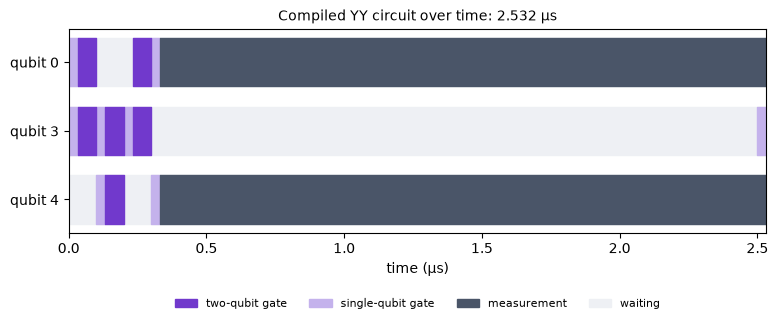
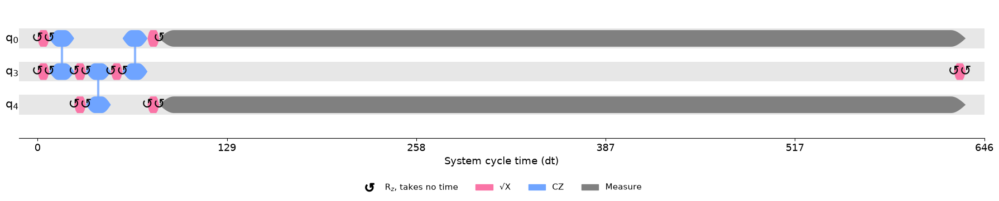
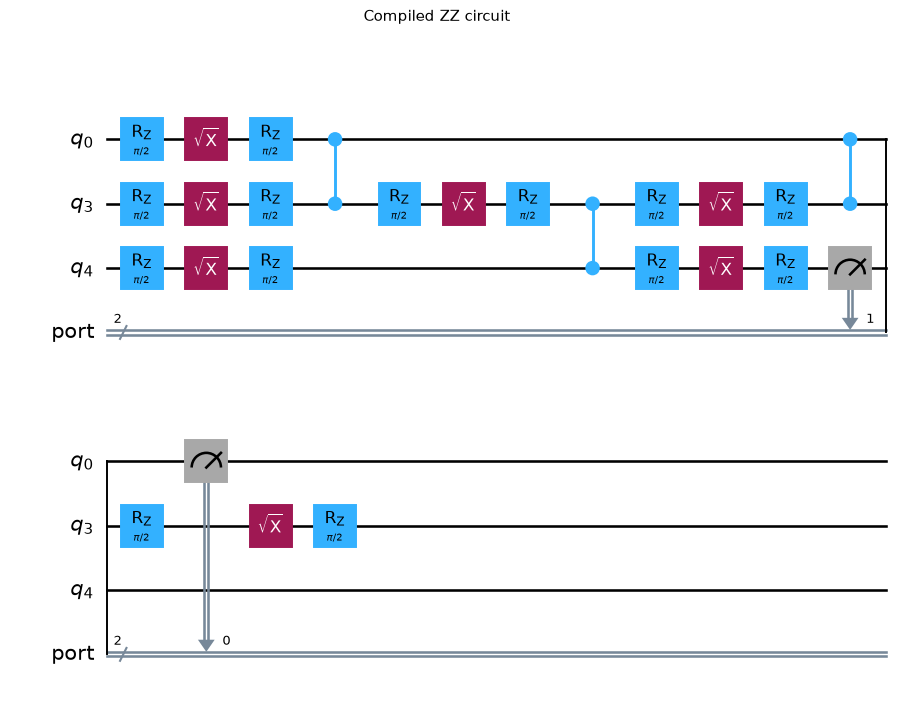
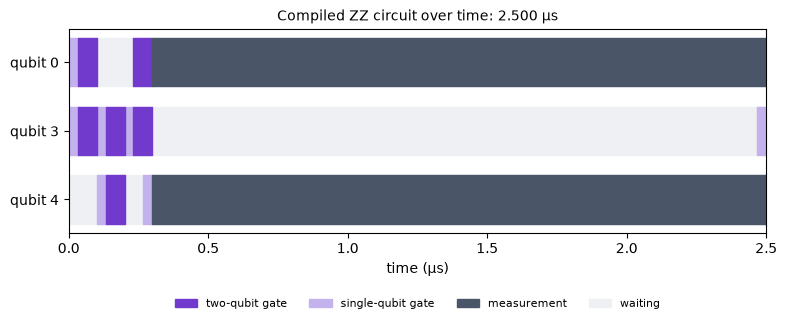
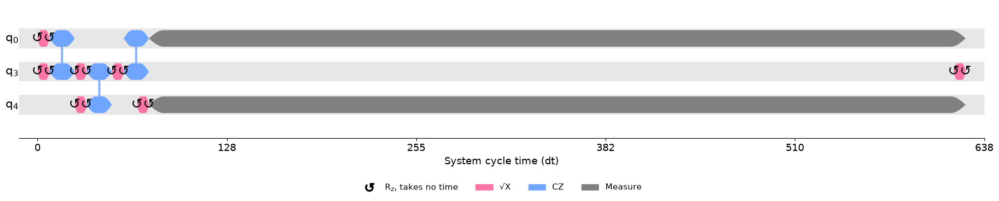

In [20]:
circuit_views("ghz-uncompute-ibm2016")

#### The contemporary graph: cases 4 to 6

The baseline's circuit file is shown in [section 2](#2.-How-bellbench-makes-a-run).

**baseline-contemporary**: Baseline, Contemporary IBM-style  
contemporary, ports 0 and 7, 4 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

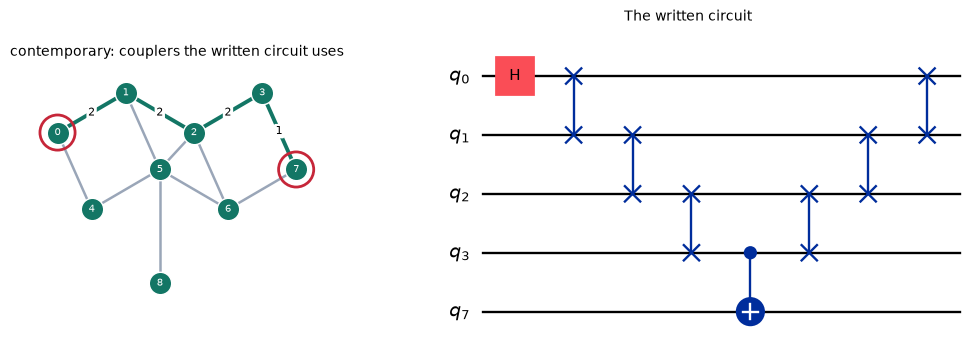

Cost: 19 two-qubit gates · 6 SWAPs (0 by the router) · depth 39 · 5 qubits (0, 1, 2, 3, 7) · 4.068 µs · pair on the ports ✓

,swap,h,cx,sx,cz,rz,measure
written,6,1,1,0,0,0,0
compiled ZZ,0,0,0,38,19,6,2
compiled XX,0,0,0,38,19,6,2
compiled YY,0,0,0,39,19,7,2



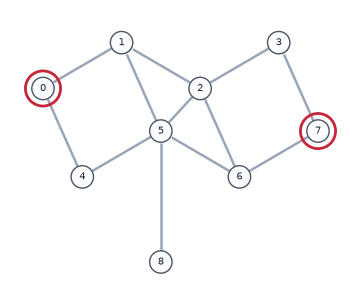
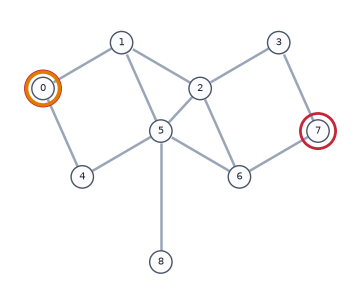
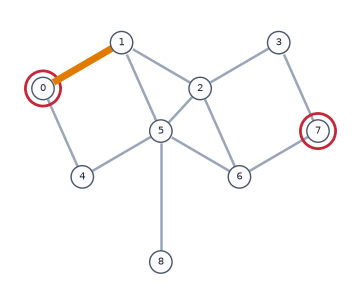
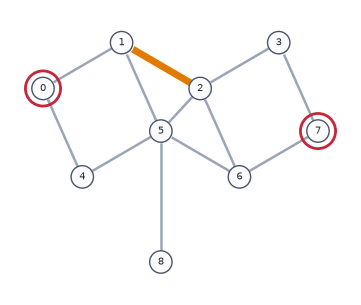
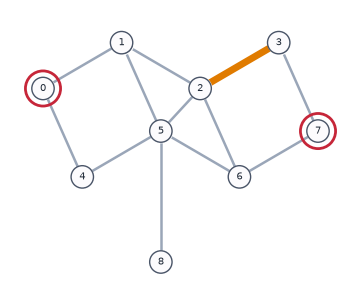
...
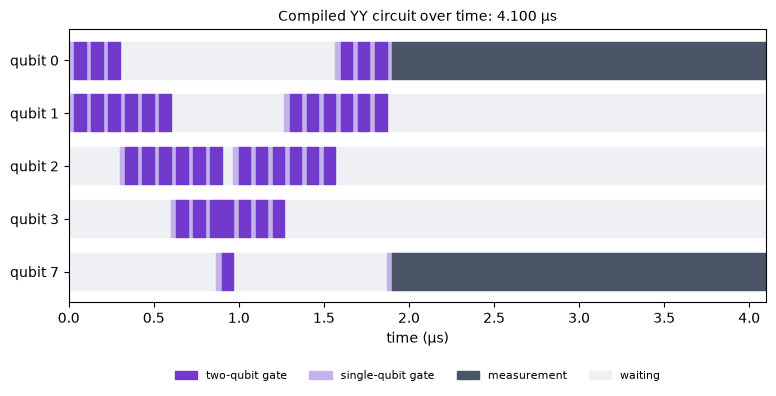
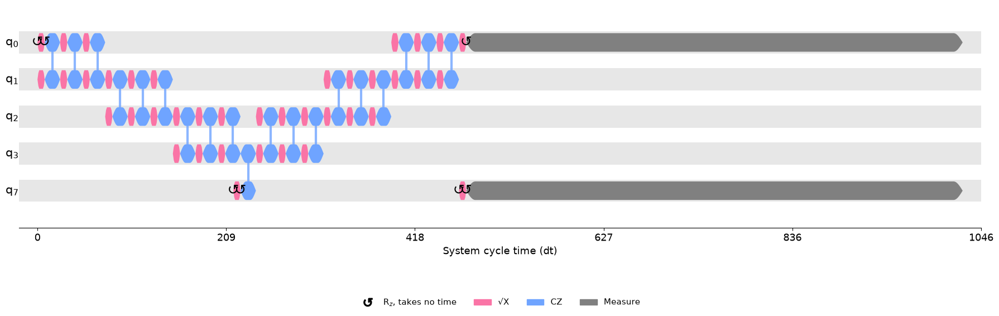
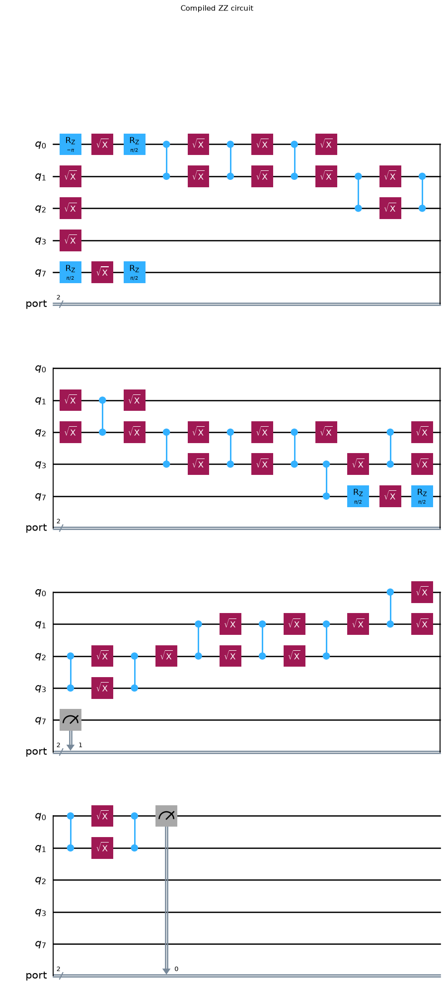
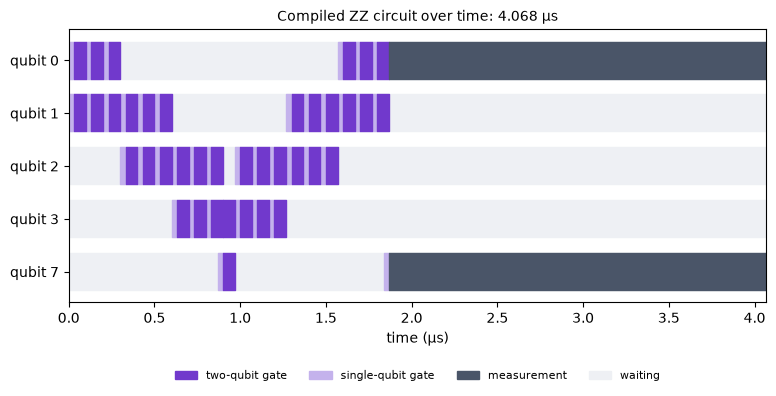
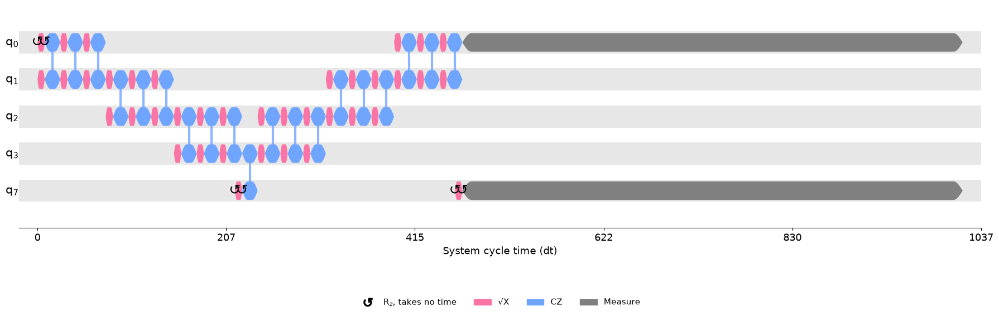

In [21]:
circuit_views("baseline-contemporary")

The protected case's circuit file is shown in [section 2](#2.-How-bellbench-makes-a-run).

**ghz-uncompute-vacancy-contemporary**: ghz_uncompute then vacancy at the end, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `parity`, 3 check groups · compiled now under boston-2026, base seed 20261116

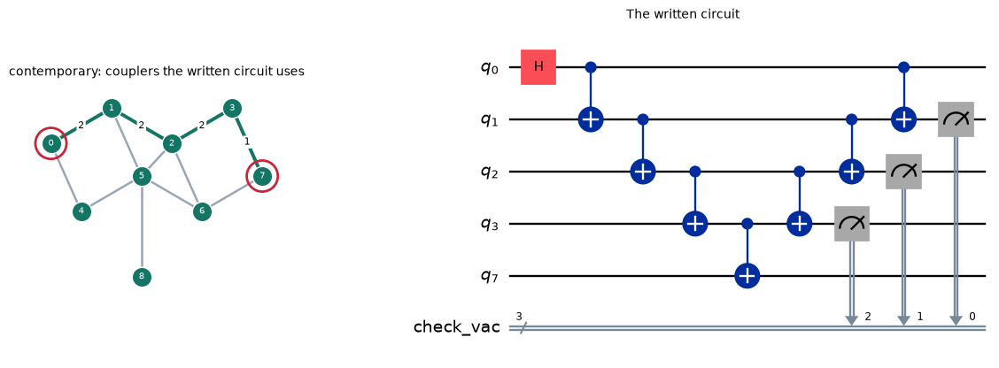

Cost: 7 two-qubit gates · 0 SWAPs (0 by the router) · depth 31 · 5 qubits (0, 1, 2, 3, 7) · 2.932 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,7,1,0,0,0,3
compiled ZZ,0,0,30,15,7,5
compiled XX,0,0,30,15,7,5
compiled YY,0,0,31,16,7,5



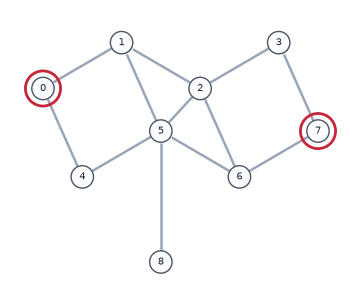
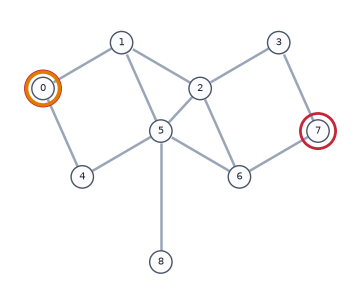
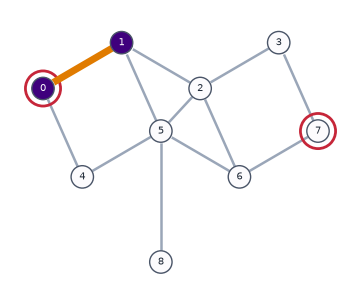
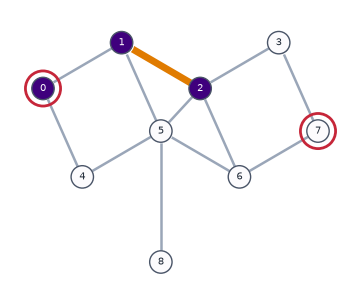
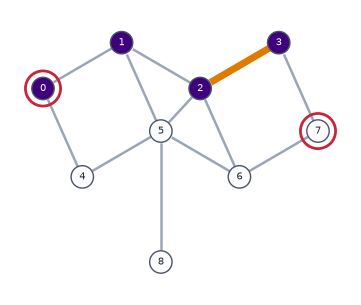
...
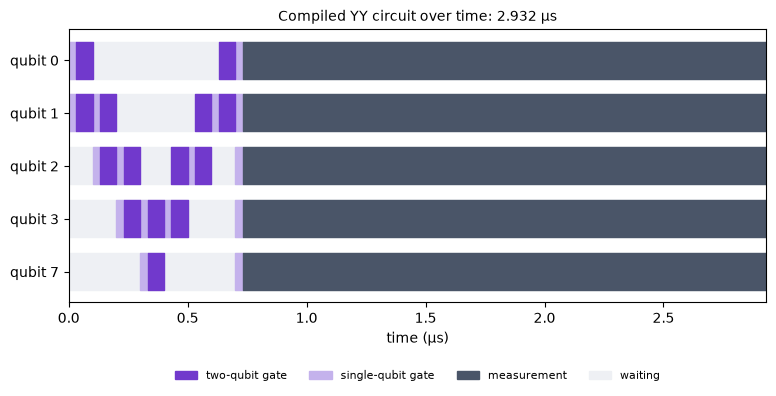
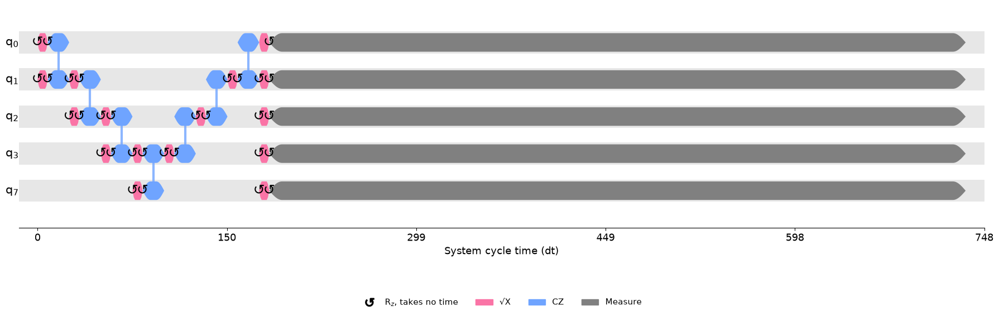
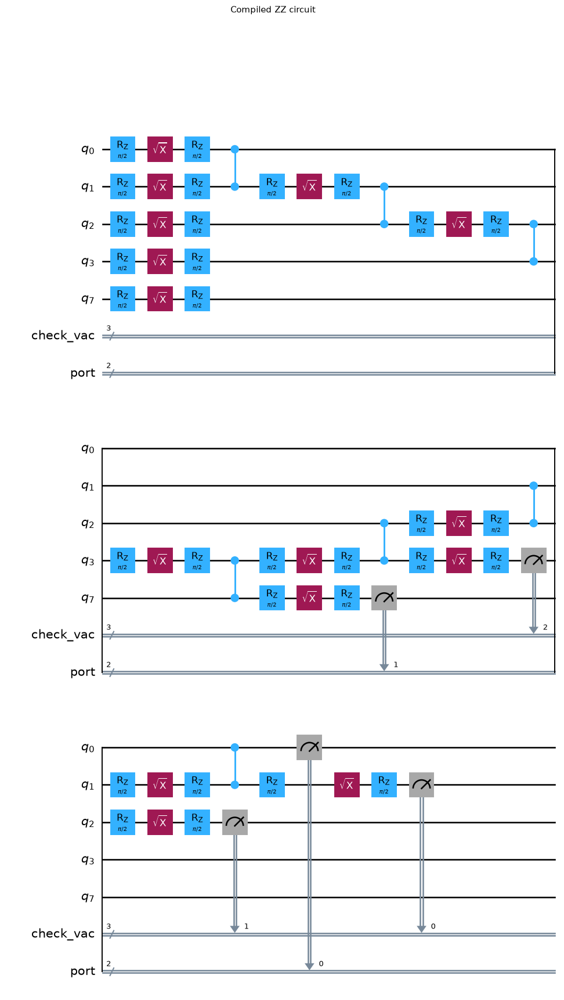
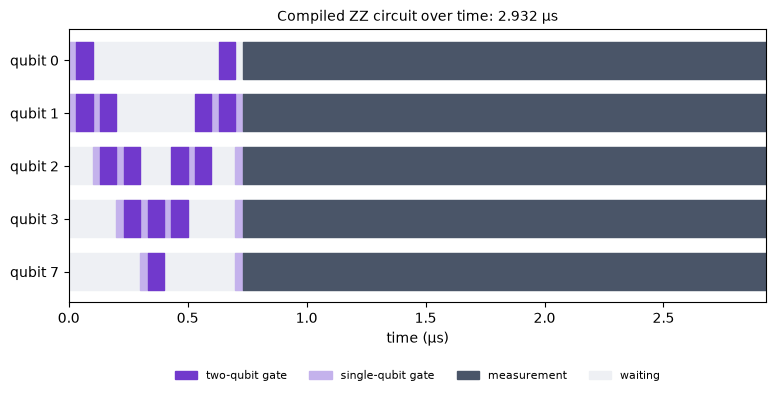
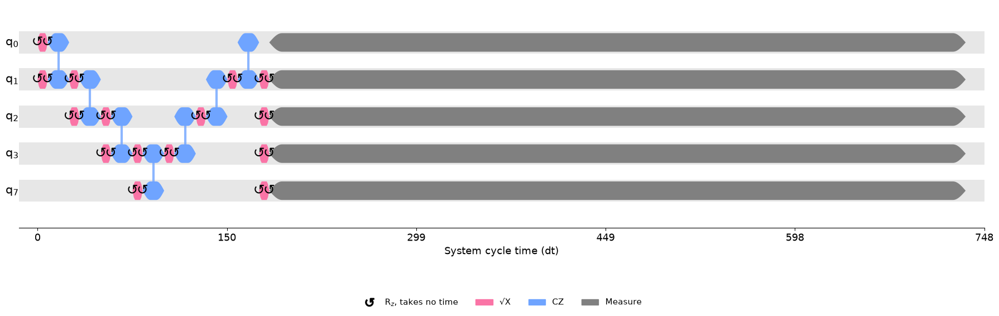

In [22]:
circuit_views("ghz-uncompute-vacancy-contemporary")

The transport alone, GHZ disentangling without the read:

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-contemporary.yaml

name: ghz-uncompute-contemporary
label: ghz_uncompute, contemporary
processor: contemporary
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  ghz_uncompute().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[3];
  cx q[3], q[7];
  cx q[2], q[3];
  cx q[1], q[2];
  cx q[0], q[1];
```

</details>

**ghz-uncompute-contemporary**: ghz_uncompute, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

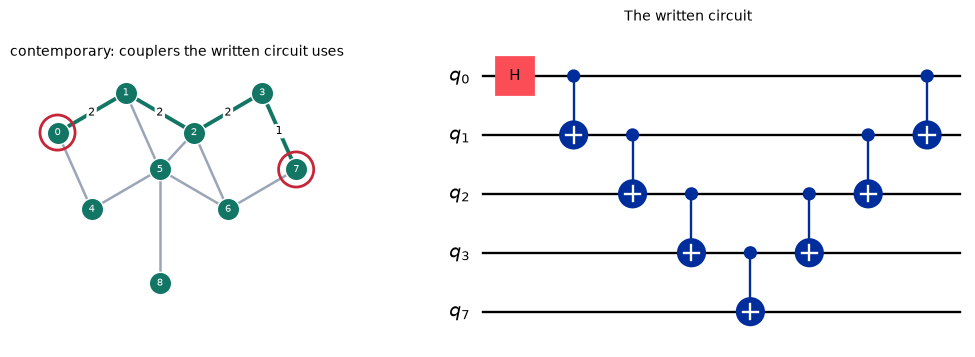

Cost: 7 two-qubit gates · 0 SWAPs (0 by the router) · depth 31 · 5 qubits (0, 1, 2, 3, 7) · 2.900 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,7,1,0,0,0,0
compiled ZZ,0,0,30,15,7,2
compiled XX,0,0,30,15,7,2
compiled YY,0,0,31,16,7,2



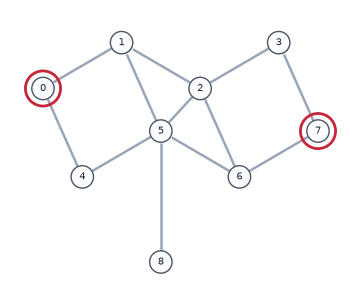
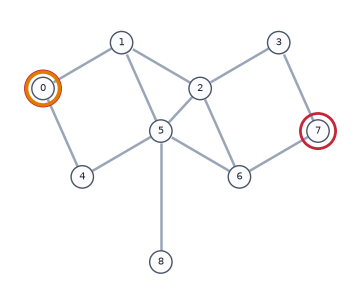
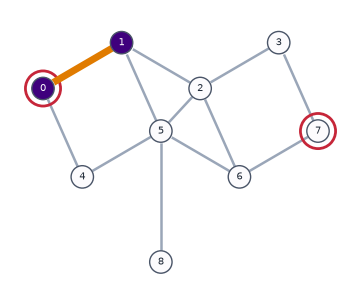
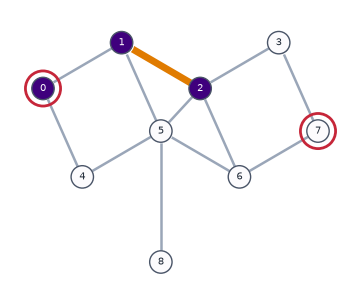
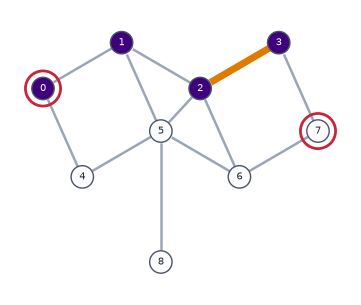
...
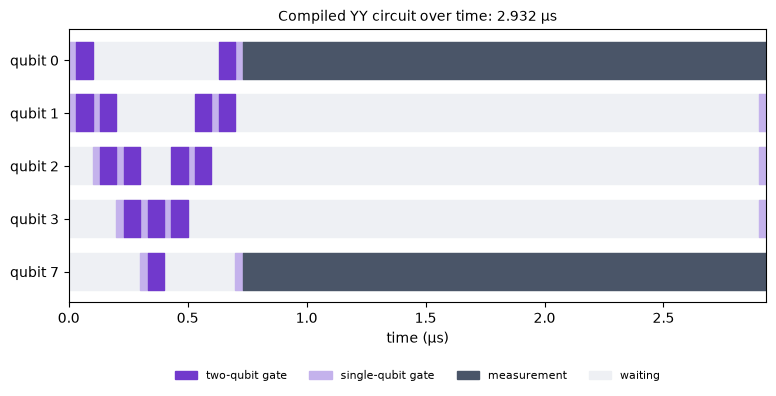
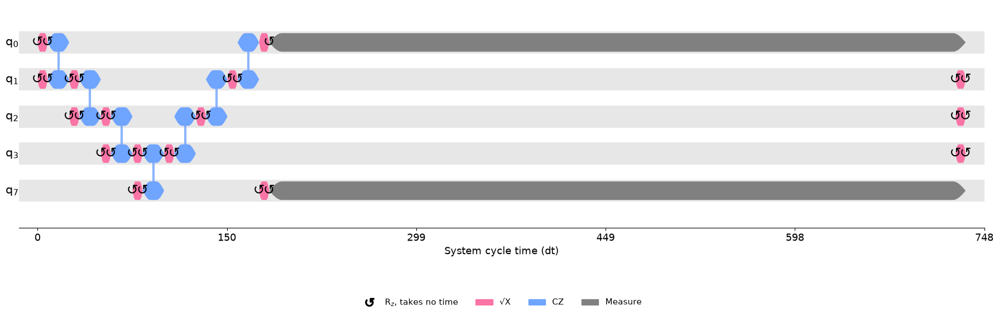
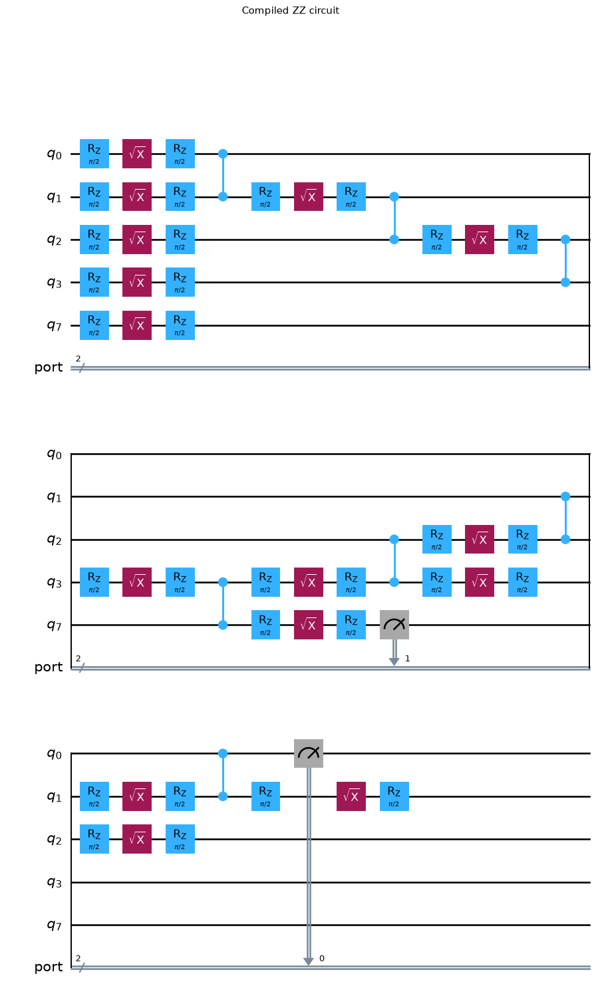
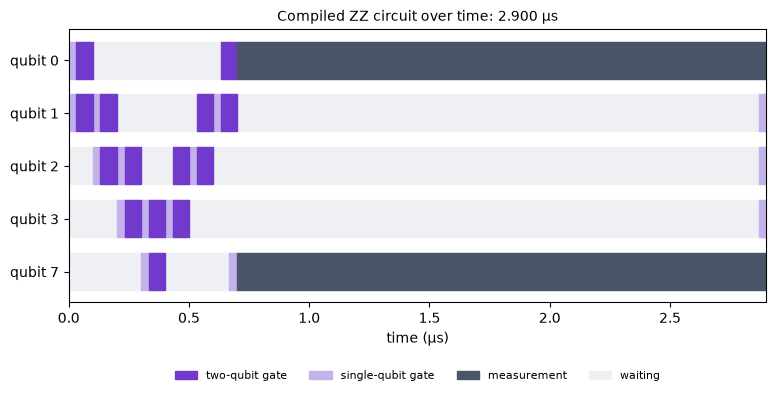
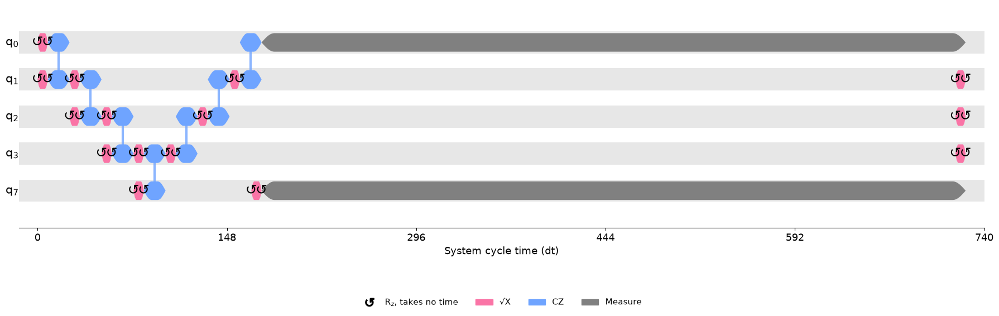

In [23]:
circuit_views("ghz-uncompute-contemporary")

#### The hyperbolic-inspired graph: cases 7 to 9

<details><summary><b>config/circuit/bp.data.circuit.baseline-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.baseline-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.baseline-hyperbolic.yaml

name: baseline-hyperbolic
label: Baseline, Hyperbolic-inspired model
processor: hyperbolic
analysis:
  name: postselect
notes: >-
  The baseline transport (swap_chain in src/bellbench/circuits.py), the organisers'
  recipe: H on the first port, explicit SWAPs out along the path [0, 1, 9, 12], the
  lexicographically smallest shortest path between the ports, CX onto the second port,
  and the same SWAPs back, so the pair ends on the ports. No checks, so postselection
  keeps every shot.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[13] q;
  h q[0];
  swap q[0], q[1];
  swap q[1], q[9];
  cx q[9], q[12];
  swap q[1], q[9];
  swap q[0], q[1];
```

</details>

**baseline-hyperbolic**: Baseline, Hyperbolic-inspired model  
hyperbolic, ports 0 and 12, 3 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

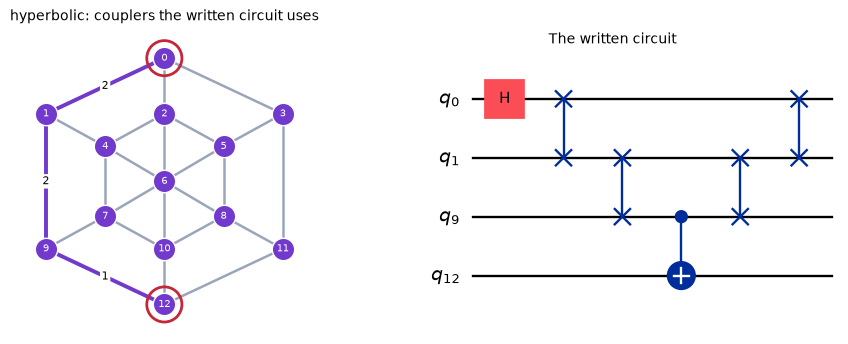

Cost: 13 two-qubit gates · 4 SWAPs (0 by the router) · depth 27 · 4 qubits (0, 1, 9, 12) · 3.468 µs · pair on the ports ✓

,swap,h,cx,sx,cz,rz,measure
written,4,1,1,0,0,0,0
compiled ZZ,0,0,0,26,13,6,2
compiled XX,0,0,0,26,13,6,2
compiled YY,0,0,0,27,13,7,2



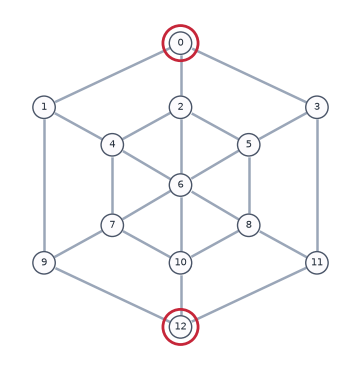
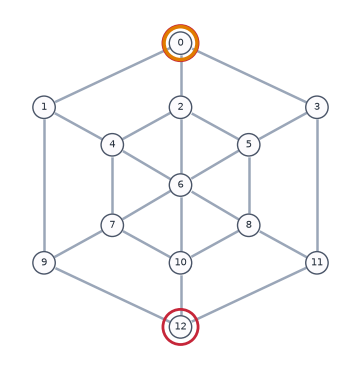
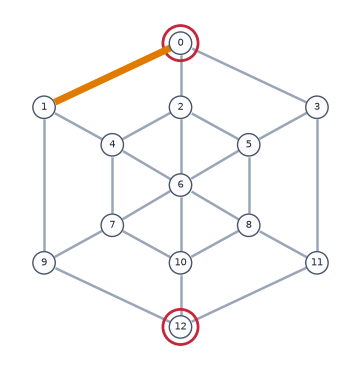
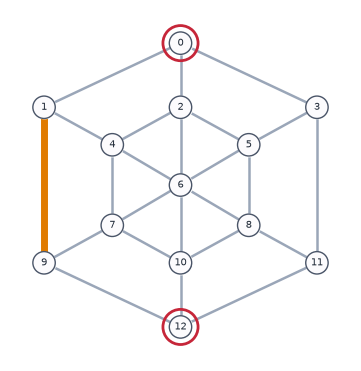
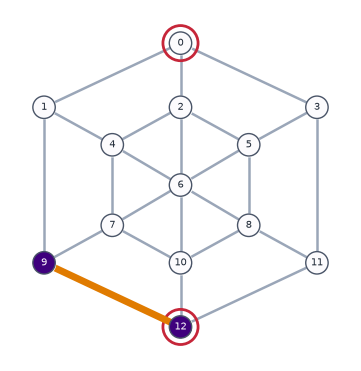
...
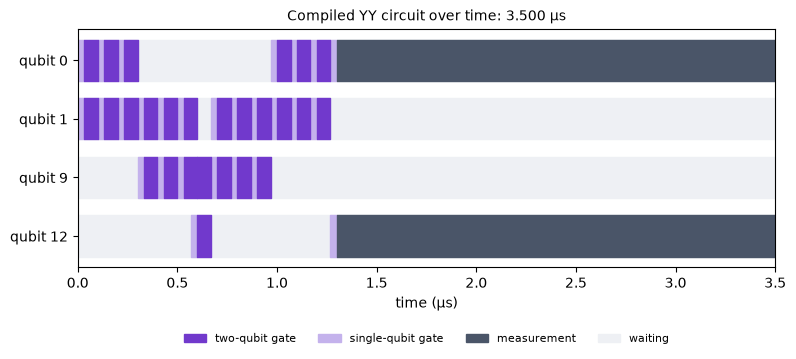
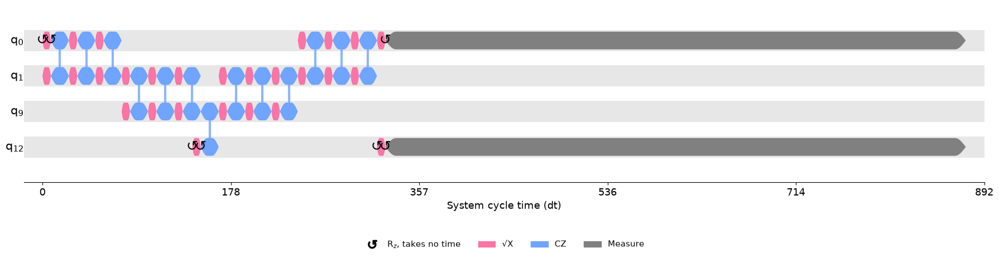
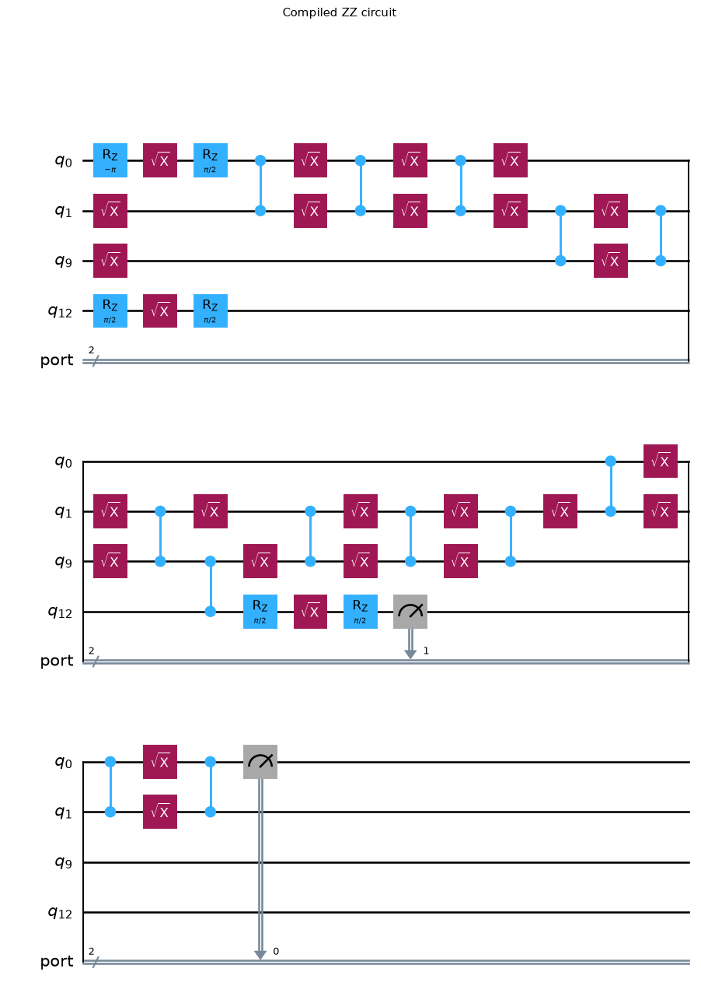
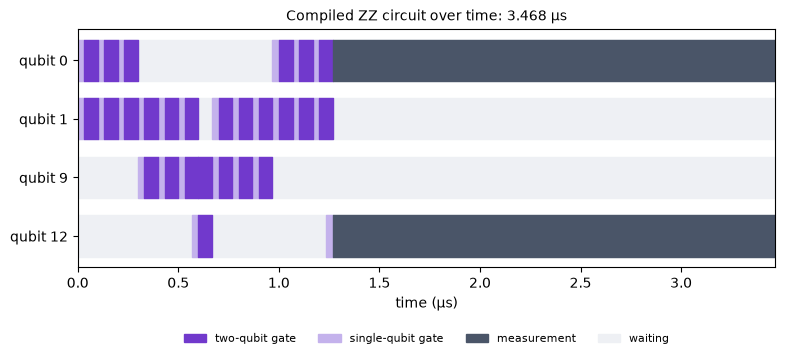
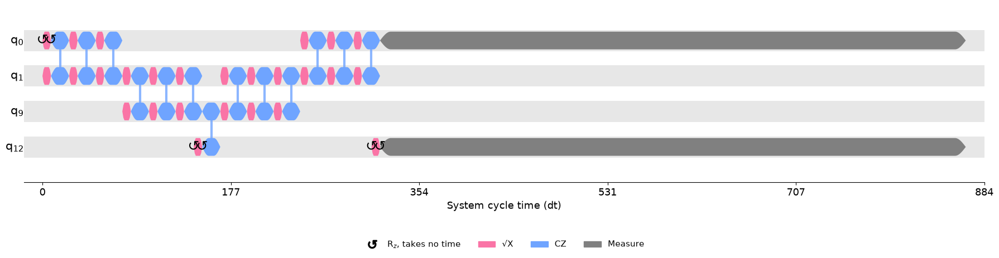

In [24]:
circuit_views("baseline-hyperbolic")

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-vacancy-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-vacancy-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-vacancy-hyperbolic.yaml

name: ghz-uncompute-vacancy-hyperbolic
label: ghz_uncompute then vacancy at the end, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: ghz_uncompute();
  then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] check_vac;
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[12];
  cx q[1], q[9];
  cx q[0], q[1];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[9];
```

</details>

**ghz-uncompute-vacancy-hyperbolic**: ghz_uncompute then vacancy at the end, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `parity`, 2 check groups · compiled now under boston-2026, base seed 20261116

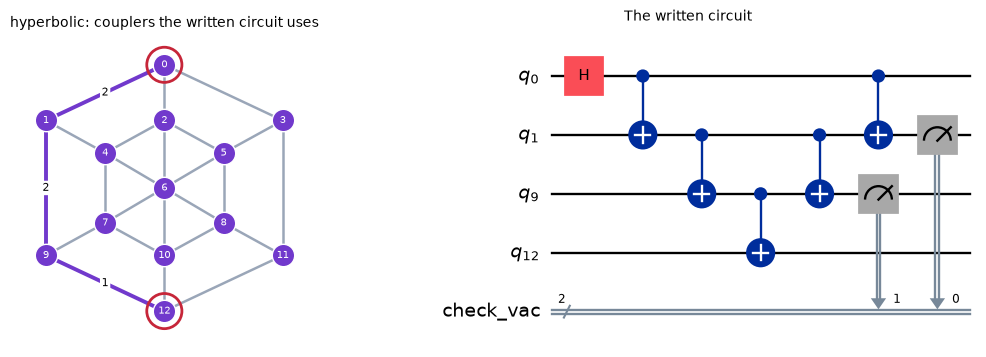

Cost: 5 two-qubit gates · 0 SWAPs (0 by the router) · depth 23 · 4 qubits (0, 1, 9, 12) · 2.732 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,5,1,0,0,0,2
compiled ZZ,0,0,22,11,5,4
compiled XX,0,0,22,11,5,4
compiled YY,0,0,23,12,5,4



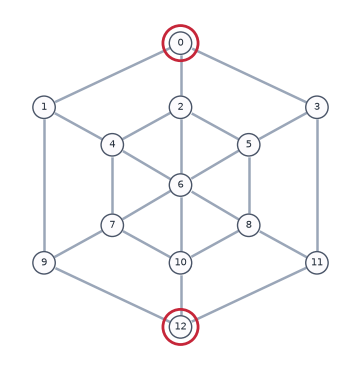
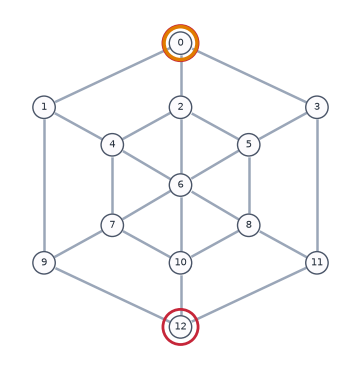
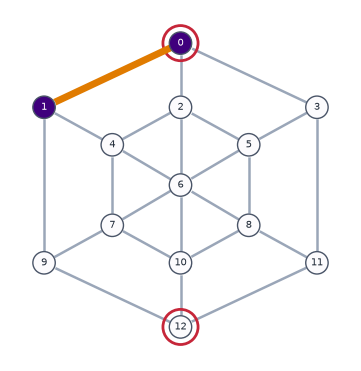
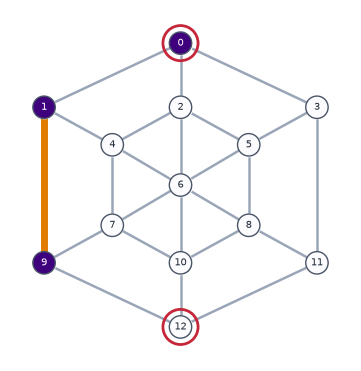
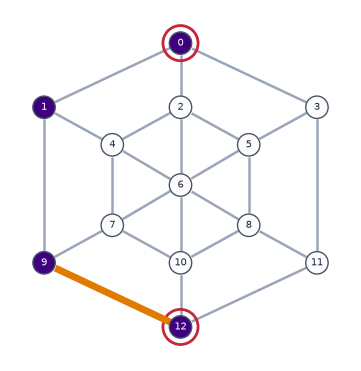
...
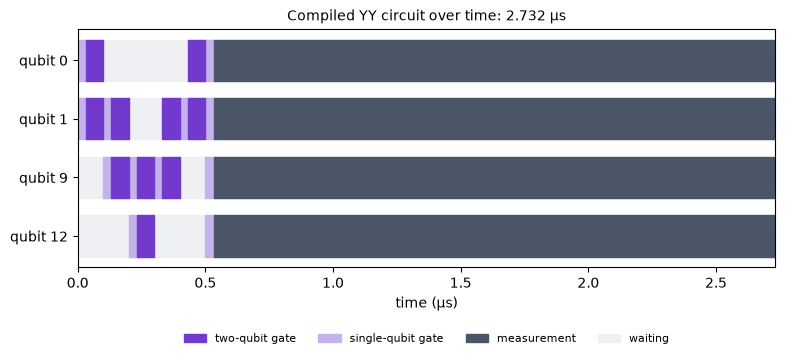
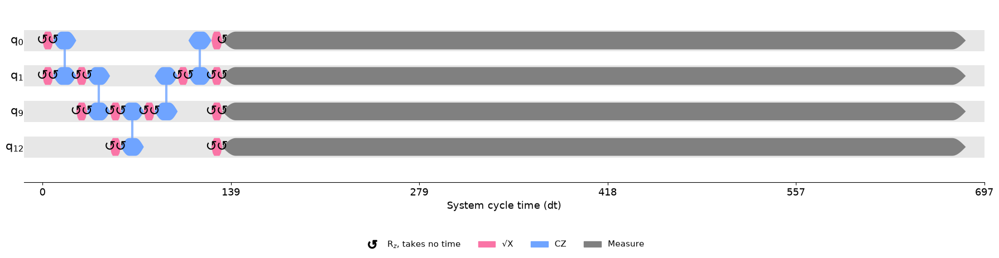
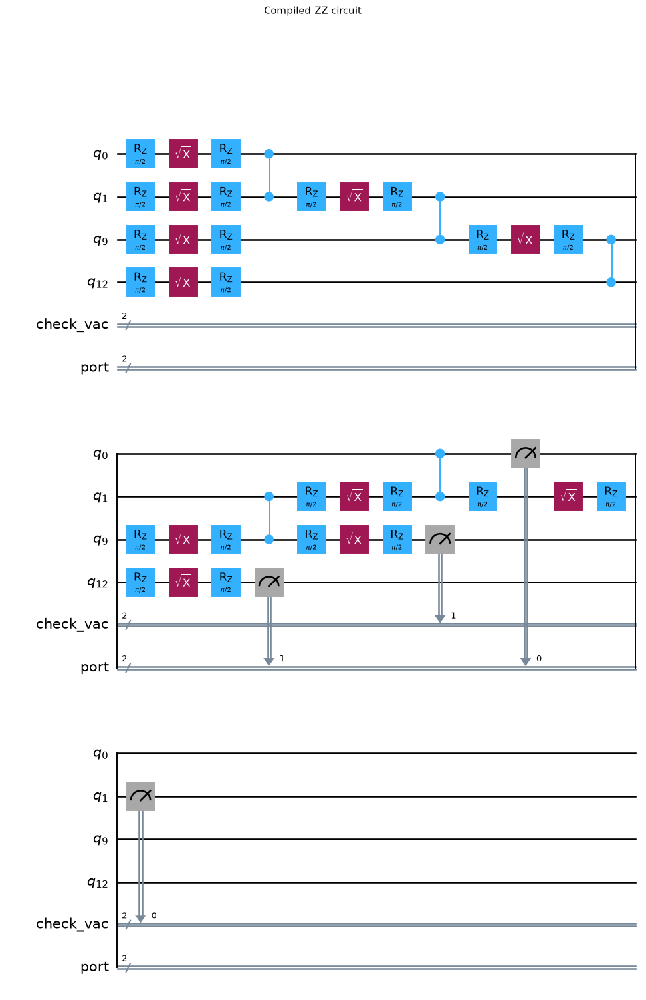
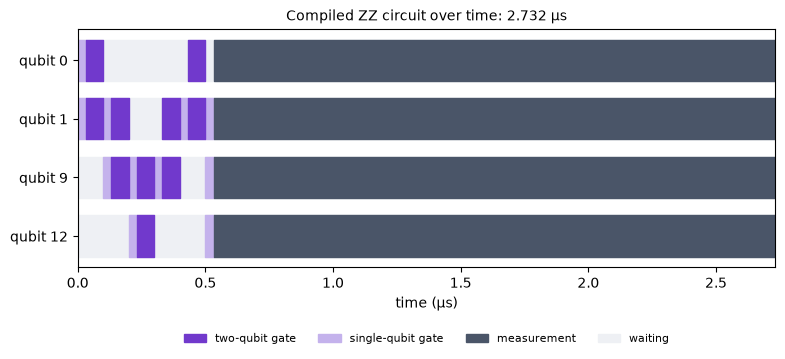
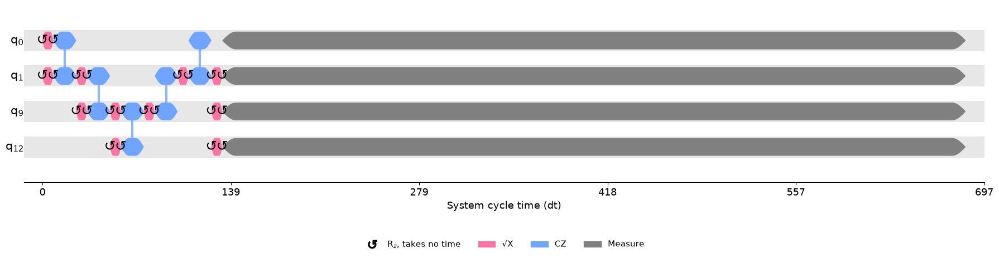

In [25]:
circuit_views("ghz-uncompute-vacancy-hyperbolic")

The transport alone, GHZ disentangling without the read:

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-hyperbolic.yaml

name: ghz-uncompute-hyperbolic
label: ghz_uncompute, hyperbolic
processor: hyperbolic
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: ghz_uncompute().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[12];
  cx q[1], q[9];
  cx q[0], q[1];
```

</details>

**ghz-uncompute-hyperbolic**: ghz_uncompute, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

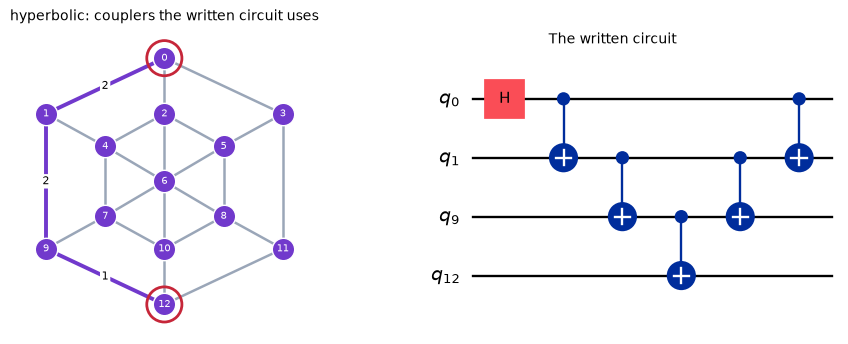

Cost: 5 two-qubit gates · 0 SWAPs (0 by the router) · depth 23 · 4 qubits (0, 1, 9, 12) · 2.700 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,5,1,0,0,0,0
compiled ZZ,0,0,22,11,5,2
compiled XX,0,0,22,11,5,2
compiled YY,0,0,23,12,5,2



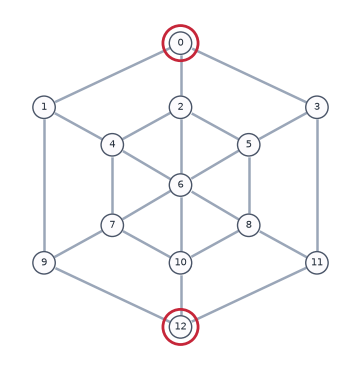
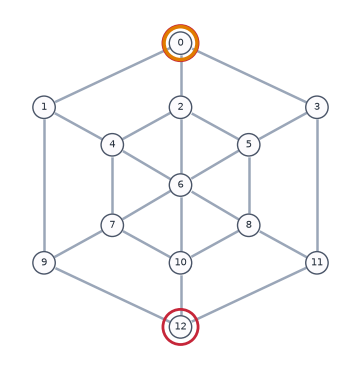
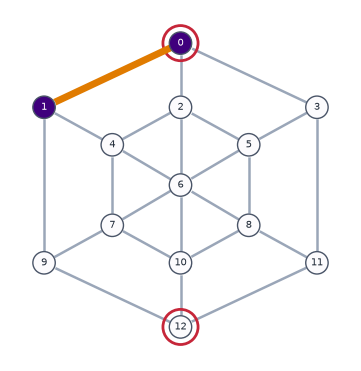
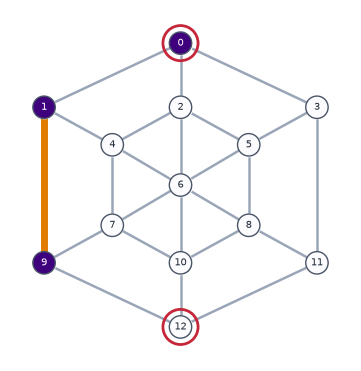
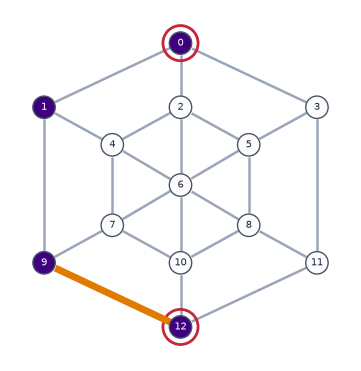
...
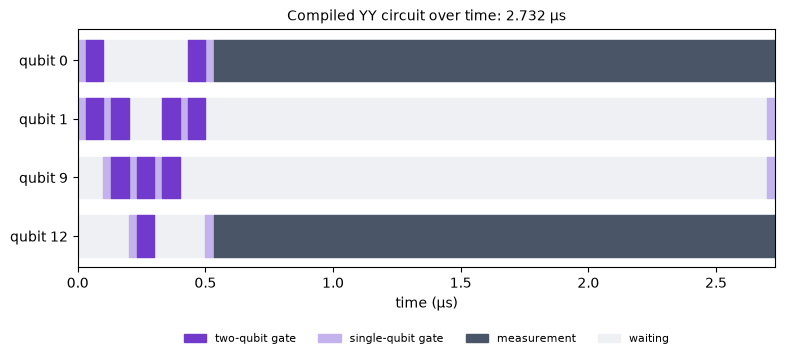
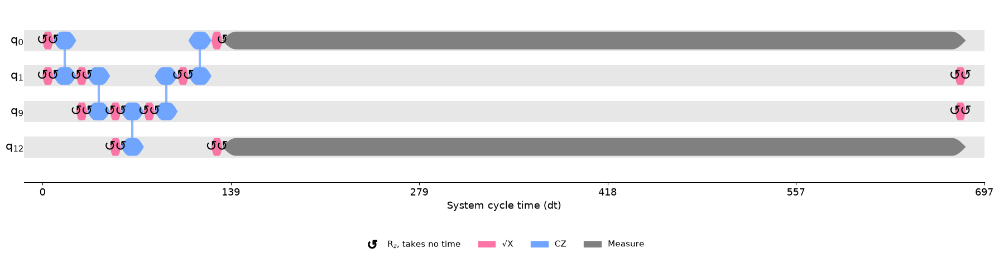
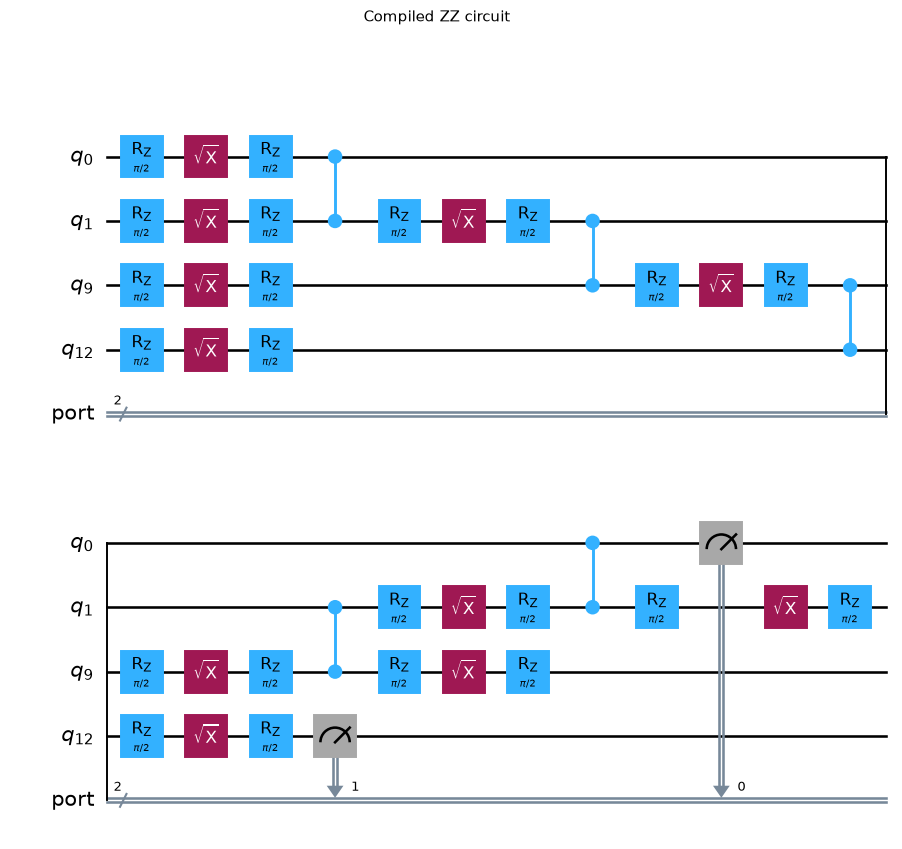
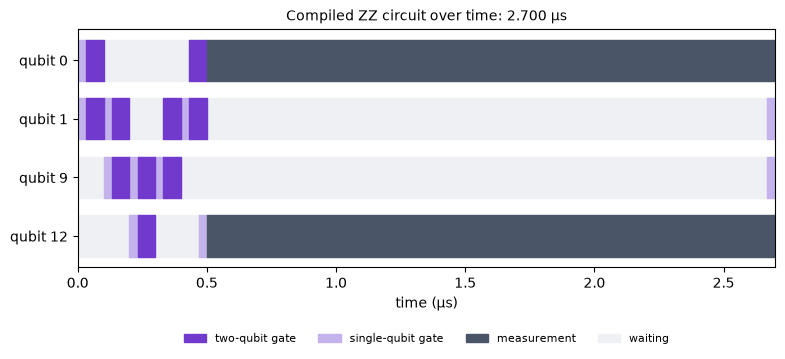
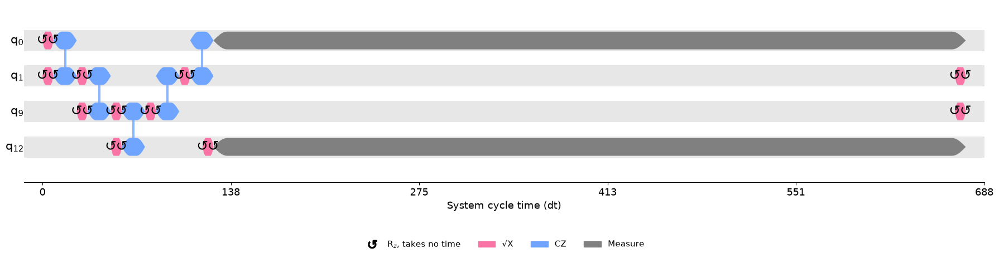

In [26]:
circuit_views("ghz-uncompute-hyperbolic")

**With every file the nine cases use shown, the notebook makes the benchmark itself:** each run compiled and simulated ideal and noisy, 100,000 shots per basis, with seeds derived from the base seed, into a folder of its own. Every table and chart from here on reads these runs; section 5.4 sets each beside the run the repository recorded.

In [27]:
make(REPORTED)

made 6 runs of deliverable-2026-11-17: baseline-ibm2016, baseline-contemporary, baseline-hyperbolic, ghz-uncompute-vacancy-ibm2016, ghz-uncompute-vacancy-contemporary, ghz-uncompute-vacancy-hyperbolic


---

## 5. Results

### 5.1 The nine cases

**Every ideal case gives F = 1 with every shot kept, and the protected cases keep 97.7% to 99.3% of their shots.** One noise profile, one base seed, 100,000 shots per basis; each ± is one standard error.

Every case with every measure the challenge asks for. F is of the kept shots, and the cost columns come from the compiled circuit.

| Case | Graph | Condition | F ± SE | F raw | Acceptance | Discarded shots | Two-qubit gates | Depth | SWAPs | Qubits | Schedule (µs) |
|---|---|---|---|---|---|---|---|---|---|---|---|
| 1 | 2016-inspired | ideal | 1.0000 ± 0.0000 | 1.0000 | 1.000 | 0 | 7 | 15 | 2 | 3 | 2.87 |
| 2 | 2016-inspired | noisy baseline | 0.9766 ± 0.0003 | 0.9766 | 1.000 | 0 | 7 | 15 | 2 | 3 | 2.87 |
| 3 | 2016-inspired | protected | 0.9842 ± 0.0003 | 0.9816 | 0.993 | 2,172 | 3 | 15 | 0 | 3 | 2.53 |
| 4 | Contemporary | ideal | 1.0000 ± 0.0000 | 1.0000 | 1.000 | 0 | 19 | 39 | 6 | 5 | 4.07 |
| 5 | Contemporary | noisy baseline | 0.9600 ± 0.0004 | 0.9600 | 1.000 | 0 | 19 | 39 | 6 | 5 | 4.07 |
| 6 | Contemporary | protected | 0.9817 ± 0.0003 | 0.9744 | 0.977 | 6,789 | 7 | 31 | 0 | 5 | 2.93 |
| 7 | Hyperbolic-inspired | ideal | 1.0000 ± 0.0000 | 1.0000 | 1.000 | 0 | 13 | 27 | 4 | 4 | 3.47 |
| 8 | Hyperbolic-inspired | noisy baseline | 0.9686 ± 0.0004 | 0.9686 | 1.000 | 0 | 13 | 27 | 4 | 4 | 3.47 |
| 9 | Hyperbolic-inspired | protected | 0.9832 ± 0.0003 | 0.9784 | 0.985 | 4,354 | 5 | 23 | 0 | 4 | 2.73 |

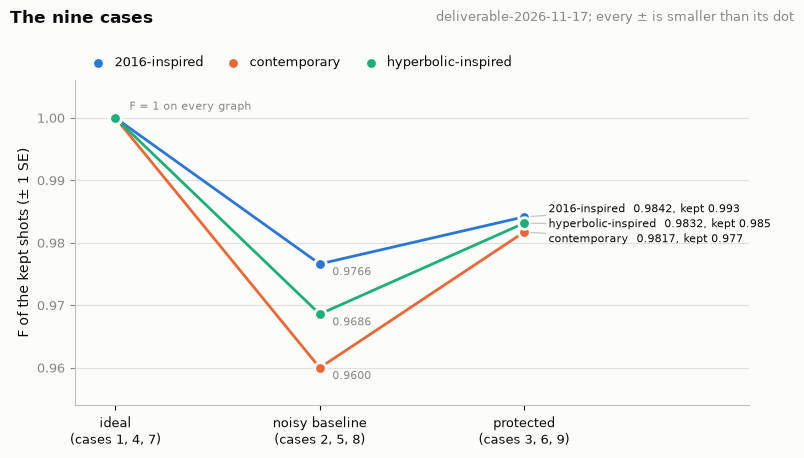

In [28]:
#@title Draw the nine cases' chart
cases = read_table(made(REPORTED) / "comparison.csv").dropna(subset=["case"]).sort_values("case")

CONDITIONS = ("ideal", "noisy baseline", "protected")
fig, ax = chart((8, 4.6))
ends = []
for processor, colour in SERIES.items():
    rows = cases[cases.processor == processor].sort_values("case")  # ideal, noisy baseline, protected
    x, y = np.arange(3), rows.fidelity.to_numpy()
    ax.plot(x, y, color=colour, lw=2, zorder=2)
    ax.errorbar(x, y, yerr=rows.fidelity_se, fmt="none", ecolor=colour, elinewidth=1, zorder=2)
    ax.scatter(x, y, s=70, color=colour, edgecolor=SURFACE, linewidth=2, zorder=3, label=NAME[processor])
    ax.annotate(f"{y[1]:.4f}", (1, y[1]), xytext=(9, -2), textcoords="offset points", va="top", fontsize=8, color=MUTED)
    ends.append((y[2], f"{NAME[processor]}  {y[2]:.4f}, kept {rows.acceptance.iloc[2]:.3f}"))
# The protected cases sit close together, so their labels are spread to at least GAP apart, keeping their order.
GAP = 0.0024
heights = [f for f, _ in sorted(ends)]
for i in range(1, len(heights)):
    heights[i] = max(heights[i], heights[i - 1] + GAP)
shift = (np.mean(heights) - np.mean([f for f, _ in ends]))
for h, (f, text) in zip(heights, sorted(ends)):
    ax.annotate(text, (2, f), xytext=(2.12, h - shift), textcoords="data", va="center", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=AXIS, lw=0.8, shrinkA=0, shrinkB=5))
ideal = cases[cases.simulation == "ideal"].fidelity
ax.annotate(f"F = {ideal.iloc[0]:g} on every graph" if ideal.nunique() == 1 else "", (0, ideal.max()), xytext=(10, 4),
            textcoords="offset points", ha="left", va="bottom", fontsize=8, color=MUTED)
ax.set_xticks(range(3), [f"{name}\n(cases {', '.join(str(int(c)) for c in sorted(cases.case) if int(c) % 3 == (i + 1) % 3)})"
                         for i, name in enumerate(CONDITIONS)])
ax.tick_params(axis="x", colors=INK)
ax.set_xlim(-0.2, 3.1)  # room right of the protected cases for their labels
ax.set_ylim(float(cases.fidelity.min()) - 0.006, 1.006)
ax.set_ylabel("F of the kept shots (± 1 SE)", color=INK, fontsize=10)
finish(fig, "The nine cases", f"{REPORTED}; every ± is smaller than its dot", legend_ax=ax)

### 5.2 What protection buys, and what it costs

**On every graph the protected case beats the noisy baseline on F with fewer two-qubit gates, no SWAP and no extra qubit; its only added cost is the shots the read discards.** Each row splits the gain into what the transport buys, by dropping the baseline's SWAPs out and back, and what the read adds; each step is given with how many combined standard errors it spans.

| Graph | Baseline F | Transport adds | Read adds | Protected F | Shots kept | Two-qubit gates |
|---|---|---|---|---|---|---|
| 2016-inspired | 0.9766 ± 0.0003 | +0.0052 (11.5 SE) | +0.0023 (5.7 SE) | 0.9842 ± 0.0003 | 99.3% | 7 to 3 |
| Contemporary | 0.9600 ± 0.0004 | +0.0145 (25.6 SE) | +0.0073 (15.5 SE) | 0.9817 ± 0.0003 | 97.7% | 19 to 7 |
| Hyperbolic-inspired | 0.9686 ± 0.0004 | +0.0096 (18.9 SE) | +0.0049 (11.2 SE) | 0.9832 ± 0.0003 | 98.5% | 13 to 5 |

The transport alone, GHZ disentangling without the read, is made here with the nine cases' shots and seed; its circuits are in section 4.4.

In [29]:
wb = Workbench(noise=NOISE, shots=SHOTS, base_seed=BASE_SEED)  # the nine cases' settings
ALONE = {}  # the transport alone on each graph, as made here
for processor in configs.CORE_PROCESSORS:
    ALONE[processor] = wb.run(f"ghz-uncompute-{processor}")
    ALONE[processor].run.write(folder=MADE / "transport-alone" / f"ghz-uncompute-{processor}")
print("made the transport alone on each graph:", ", ".join(f"ghz-uncompute-{p}" for p in ALONE))

made the transport alone on each graph: ghz-uncompute-ibm2016, ghz-uncompute-contemporary, ghz-uncompute-hyperbolic


**The workbench's view.** In the workbench a teammate compares runs with one call, `wb.compare`. Here it sets the contemporary graph's noisy baseline, transport alone and protected case side by side:

#,run,processor,F,F raw,acceptance,two-qubit gates,shots per basis
1,baseline-contemporary (fetched),contemporary,0.9600 ± 0.0004,0.9600 ± 0.0004,1.0000,19,"100,000"
2,ghz-uncompute-contemporary (now),contemporary,0.9745 ± 0.0004,0.9745 ± 0.0004,1.0000,7,"100,000"
3,ghz-uncompute-vacancy-contemporary (fetched),contemporary,0.9817 ± 0.0003,0.9744 ± 0.0004,0.9774,7,"100,000"


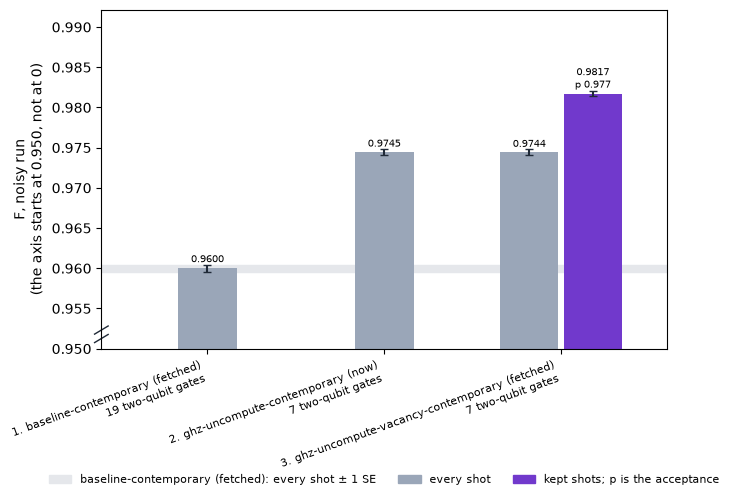

In [30]:
here = made(REPORTED)
wb.compare(Result.from_folder(here / "baseline-contemporary"), ALONE["contemporary"],
           Result.from_folder(here / "ghz-uncompute-vacancy-contemporary"))

**Across the three graphs,** F of the kept shots against what each kept pair costs in two-qubit gates, the gates divided by the acceptance (section 3.1). Each line runs from a graph's noisy baseline to its transport alone and its protected case: the transport moves left, by dropping SWAPs, and up; the read moves almost straight up, since it adds no gate and discards few shots.

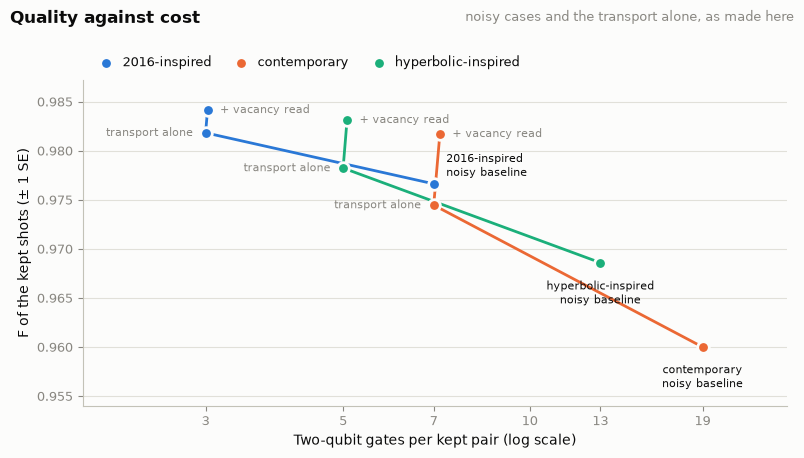

In [31]:
#@title Draw the chart of what the transport and the read each buy, on each graph
from matplotlib.ticker import FixedLocator, NullLocator

noisy = read_table(made(REPORTED) / "comparison.csv").query("simulation == 'noisy'")
alone = pd.DataFrame(comparison_rows({f"ghz-uncompute-{p}": r.run for p, r in ALONE.items()}, {})).query("simulation == 'noisy'")
noisy = pd.concat([noisy, alone.assign(case=np.nan)])
noisy["stage"] = [1 if pd.isna(c) else 0 if int(c) % 3 == 2 else 2 for c in noisy.case]
STAGE = ("noisy baseline", "transport alone", "+ vacancy read")
# Where each label sits beside its point, in points: (dx, dy, ha, va), by stage, then any one point's own placement.
PLACE = {0: (0, -12, "center", "top"), 1: (-9, 0, "right", "center"), 2: (9, 0, "left", "center"),
         ("ibm2016", 0): (9, 3, "left", "bottom")}
fig, ax = chart((8, 4.6))
for processor, colour in SERIES.items():
    rows = noisy[noisy.processor == processor].sort_values("stage")
    x, y = rows.two_qubit_gates_per_accepted_pair, rows.fidelity
    ax.plot(x, y, color=colour, lw=2, zorder=2)
    ax.errorbar(x, y, yerr=rows.fidelity_se, fmt="none", ecolor=colour, elinewidth=1, capsize=0, zorder=2)
    ax.scatter(x, y, s=70, color=colour, edgecolor=SURFACE, linewidth=2, zorder=3, label=NAME[processor])
    for (xi, yi, stage) in zip(x, y, rows.stage):
        dx, dy, ha, va = PLACE.get((processor, stage), PLACE[stage])
        text = f"{NAME[processor]}\n{STAGE[0]}" if stage == 0 else STAGE[stage]
        ax.annotate(text, (xi, yi), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va, fontsize=8,
                    color=INK if stage == 0 else MUTED)
ax.set_xscale("log")
ax.xaxis.set_major_locator(FixedLocator([3, 5, 7, 10, 13, 19]))
ax.xaxis.set_minor_locator(NullLocator())
ax.xaxis.set_major_formatter(lambda v, _: f"{v:g}")
ax.set_xlim(1.9, 26)  # room left of the cheapest points for their labels
ax.set_ylim(float(noisy.fidelity.min()) - 0.006, float(noisy.fidelity.max()) + 0.003)
ax.set_xlabel("Two-qubit gates per kept pair (log scale)", color=INK, fontsize=10)
ax.set_ylabel("F of the kept shots (± 1 SE)", color=INK, fontsize=10)
finish(fig, "Quality against cost", "noisy cases and the transport alone, as made here", legend_ax=ax)

### 5.3 What the graphs explain

**All three graphs share one noise model, so their differences come from connectivity alone. Port distance sets the cost of moving the pair, protected or not; a spare path, a second path between the ports, lets a check add a little more F at a cost in shots, gates and qubits.**

| Graph | Hops between ports | Disjoint paths | F: baseline / transport / protected | Shots kept | With a spare-path XX check: F, kept |
|---|---|---|---|---|---|
| 2016-inspired | 2 | 1 | 0.9766 / 0.9818 / 0.9842 | 99.3% | no spare path |
| Hyperbolic-inspired | 3 | 3 | 0.9686 / 0.9782 / 0.9832 | 98.5% | 0.9845, 97.1% |
| Contemporary | 4 | 2 | 0.9600 / 0.9745 / 0.9817 | 97.7% | 0.9827, 95.6% |

- **F falls as the ports grow apart, with or without protection:** the baseline, the transport alone and the protected case all rank the graphs by hops, 2, then 3, then 4. The protected cases stand 2.5 and 3.4 combined standard errors apart.
- **The 2016-inspired graph, with one path between its ports, gives the highest protected F.** The vacancy read uses the pair's own path at the end of the circuit, so it needs no spare path.
- **What a spare path buys:** an XX check on a spare path after the read raises F a little, by +0.0013 (3.3 SE) on the hyperbolic-inspired graph and +0.0010 (2.2 SE) on the contemporary graph, at a cost in shots, two-qubit gates and qubits, so we report the read alone on every graph, which also keeps the three graphs' cases one strategy. Sections 6.2 and 6.3 set out each graph's costs.
- **The hyperbolic-inspired graph is a schematic,** a 13-qubit graph of short distances and high degree, not a patch of a hyperbolic lattice; we claim no advantage from its geometry beyond these three features.

### 5.4 The notebook's runs beside the recorded ones

**Every number above comes from runs this notebook made; this table sets each beside the run the repository recorded.** One row per run of the nine cases and per transport alone from 5.2: F and acceptance as made here and as recorded, whether the counts, the compiled circuits and the numbers are identical, and whether the files the record names hash to the files this notebook wrote. Outside the team's git repository the commit cannot match, and with other package versions the numbers may not, which is why section 1 installs the pinned versions; both are listed below the table, not counted as a difference.

In [32]:
beside_record(REPORTED, extra=[(MADE / "transport-alone" / f"ghz-uncompute-{p}", recorded(name) / f"ghz-uncompute-{p}")
                               for p, name in {"ibm2016": "deliverable-2026-11-17-extended-ibm2016", "contemporary": "deliverable-2026-11-17-extended-contemporary", "hyperbolic": "deliverable-2026-11-17-extended-hyperbolic"}.items()])

---

**Each run of deliverable-2026-11-17 beside the run the repository recorded**

,F here,F recorded,acceptance here,acceptance recorded,identical,same files
run,,,,,,
baseline-ibm2016,0.9766,0.9766,1.000,1.000,True,True
baseline-contemporary,0.9600,0.9600,1.000,1.000,True,True
baseline-hyperbolic,0.9686,0.9686,1.000,1.000,True,True
ghz-uncompute-vacancy-ibm2016,0.9842,0.9842,0.993,0.993,True,True
ghz-uncompute-vacancy-contemporary,0.9817,0.9817,0.977,0.977,True,True
ghz-uncompute-vacancy-hyperbolic,0.9832,0.9832,0.985,0.985,True,True
ghz-uncompute-ibm2016,0.9818,0.9818,1.000,1.000,True,True
ghz-uncompute-contemporary,0.9745,0.9745,1.000,1.000,True,True
ghz-uncompute-hyperbolic,0.9782,0.9782,1.000,1.000,True,True


every run identical to its record, counts, circuits and numbers
provenance that differs, not counted: commit


### 5.5 Interpretation

**What the results show, against the three things the challenge asks a comparison to explain:**

- **Fidelity against the operations compilation added.** Under one noise model, F tracks the two-qubit gates and the idle time a circuit adds. The baseline's SWAPs out and back cost 7, 13 and 19 two-qubit gates; GHZ disentangling's 3, 5 and 7 recover 22%, 31% and 36% of the fidelity the baseline lost, measured against F = 1.
- **Whether protection pays.** A read of the emptied path at the end of the circuit raised F above the same transport by more than two combined standard errors on every graph, discarding 0.7% to 2.3% of shots and adding no gate. The same read after the move chain gained less (section 6).
- **Connectivity against noise.** Every graph runs under the same profile, so the differences are connectivity's: hops between the ports set the cost of moving the pair, protected or not, and disjoint paths matter only to a check that needs a spare path.

### 5.6 Recommendation

**Empty the path with gates, then read it at the end: a check that costs shots, not gates or qubits.**

On every graph the read raised F above the same transport without it by more than two combined standard errors (section 5.2), and among the circuits we tested that kept at least as many shots as the earlier XX check, it gave the highest F on every graph (section 6). The same read after the move chain gained less. An XX check on a spare path raised F a little further only by discarding more shots, so for this strategy port distance, not the number of disjoint paths, ordered the protected results (section 5.3). For hardware, readout quality decides between our transport and the textbook GHZ transport that reads the path in X (section 6.4). The recommendation is conditional on our Boston-based model, and we have not tested this strategy against qubits that start a shot excited.

---

## 6. Alternative circuits: each protected case beside its alternatives

**For each graph, one extended benchmark runs the protected case beside the circuits that differ from it by one step, so each comparison shows what one change buys; none fills a case.** Every run shares the nine cases' noise profile, shots and base seed, so the runs the two benchmarks share repeat their numbers exactly. Each section shows the benchmark file, tables each run against the protected case, shows the circuits section 4.4 does not, each with its pictures folded, then makes the benchmark and sets each run beside its record.

Each run is named for its circuit, followed by the graph; a suffix marks the one run that changes a setting.

- `baseline`: our baseline, the SWAP circuit: SWAPs out and back.
- `move-chain`: each hop moves the pair's far half with two CX gates; no check.
- `ghz-measure`: the textbook GHZ transport, reading the interior in X, with a Z owed on the first port for each 1; no check.
- `ghz-measure-<graph>-readout-0`: the same circuit with no readout error on the interior qubits it reads, the only run that changes the profile.
- `ghz-uncompute`: GHZ disentangling, the protected case's transport; no check.
- `move-chain-vacancy`: the move chain, then the vacancy read.
- `ghz-uncompute-vacancy`: the protected case, GHZ disentangling then the vacancy read.
- `move-chain-path-xx`, `move-chain-spare-xx`: the earlier protected case, the move chain with an XX check on the path read mid-circuit, or on a spare path.
- `ghz-uncompute-vacancy-spare-xx`: the protected case, then an XX check on a spare path.

### 6.1 The 2016-inspired graph

**The vacancy read raised GHZ disentangling by +0.0023 (5.7 SE), and the move chain by less, +0.0018 (4.3 SE).**

- **Against the move chain:** without a read the two transports agree within 1.1 combined standard errors; with the read, the protected case is ahead by +0.0010 (2.4 SE).
- **Against the earlier protected case:** +0.0044 (10.4 SE), keeping 99.3% of shots against 97.0%, with 3 two-qubit gates against 5. With no spare path on this graph, that check reads a qubit of the pair's path mid-circuit, under a mid-circuit measurement error of 0.01.

| Run | F ± SE | Acceptance | Two-qubit gates | Against the protected case |
|---|---|---|---|---|
| baseline-ibm2016 | 0.9766 ± 0.0003 | 1.000 | 7 | -0.0075 (-17.1 SE) |
| move-chain-ibm2016 | 0.9814 ± 0.0003 | 1.000 | 3 | -0.0028 (-6.8 SE) |
| ghz-measure-ibm2016 | 0.9790 ± 0.0003 | 1.000 | 2 | -0.0052 (-12.1 SE) |
| ghz-measure-ibm2016-readout-0 | 0.9828 ± 0.0003 | 1.000 | 2 | -0.0013 (-3.3 SE) |
| ghz-uncompute-ibm2016 | 0.9818 ± 0.0003 | 1.000 | 3 | -0.0023 (-5.7 SE) |
| move-chain-vacancy-ibm2016 | 0.9832 ± 0.0003 | 0.994 | 3 | -0.0010 (-2.4 SE) |
| ghz-uncompute-vacancy-ibm2016 | 0.9842 ± 0.0003 | 0.993 | 3 | the protected case |
| move-chain-path-xx-ibm2016 | 0.9797 ± 0.0003 | 0.970 | 5 | -0.0044 (-10.4 SE) |

<details><summary><b>config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-ibm2016.yaml

name: deliverable-2026-11-17-extended-ibm2016
label: 2016-inspired, the protected case beside its alternatives
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): on the 2016-inspired graph, the deliverable's protected case,
  case 3, beside the circuits that differ from it by one step, so each comparison
  shows what one change buys. The rungs, each a builder call along the baseline's path
  [0, 3, 4]: the organisers' baseline; the move chain, which moves the pair with two
  CX gates a hop instead of a SWAP's three; ghz_measure, the textbook GHZ transport,
  which reads the interior qubits in X and owes a Z on the first port for each 1;
  ghz_uncompute, which empties the interior with gates instead; ghz_measure again with
  no readout error on the interior qubits it reads, an override only this run takes,
  which shows whether readout error alone decides between the two GHZ transports; each
  of the two empty transports followed by a vacancy read at the end, where only
  ghz_uncompute's last gate makes the read catch a bit flip on the first port; and the
  move-chain benchmark's case 3, the move chain with an XX check on the pair's own
  path, which reads a qubit mid-circuit and runs with the mid-circuit measurement
  error of 0.01 it was reported with. The graph has no spare path, so no rung adds an
  XX check to the vacancy read. Every run takes the deliverable's noise profile, shots
  and base seed, so the runs it shares with the deliverable repeat its numbers
  exactly; the runs it shares with the move-chain benchmark, which takes 20,000 shots,
  agree with them within their errors.
shots: 100000
base_seed: 20261116
runs:
  # The reference: the organisers' baseline.
  - {run: baseline-ibm2016, circuit: baseline-ibm2016, noise: boston-2026}
  # The transports alone, with no check.
  - {run: move-chain-ibm2016, circuit: move-chain-ibm2016, noise: boston-2026}
  - {run: ghz-measure-ibm2016, circuit: ghz-measure-ibm2016, noise: boston-2026}
  # ghz_measure with no readout error on the interior qubits [3], the only run here that changes the profile.
  - {run: ghz-measure-ibm2016-readout-0, circuit: ghz-measure-ibm2016, noise: boston-2026, overrides: [{qubits: 3, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 3, field: qubit.readout_error.reads_0_when_1, value: 0.0}]}
  - {run: ghz-uncompute-ibm2016, circuit: ghz-uncompute-ibm2016, noise: boston-2026}
  # A vacancy read at the end after each transport that empties the path; the second is the deliverable's protected case.
  - {run: move-chain-vacancy-ibm2016, circuit: move-chain-vacancy-ibm2016, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-ibm2016, circuit: ghz-uncompute-vacancy-ibm2016, noise: boston-2026}
  # The move-chain benchmark's case 3: the move chain with its XX check on the path, read mid-circuit.
  - {run: move-chain-path-xx-ibm2016, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01}}
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-chain-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-ibm2016.yaml

name: move-chain-ibm2016
label: move_chain, ibm2016
processor: ibm2016
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: move_chain().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[5] q;
  h q[0];
  cx q[0], q[3];
  cx q[3], q[4];
  cx q[4], q[3];
```

</details>

**move-chain-ibm2016**: move_chain, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

Cost: 3 two-qubit gates · 0 SWAPs (0 by the router) · depth 15 · 3 qubits (0, 3, 4) · 2.500 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,3,1,0,0,0,0
compiled ZZ,0,0,14,7,3,2
compiled XX,0,0,18,9,3,2
compiled YY,0,0,16,9,3,2

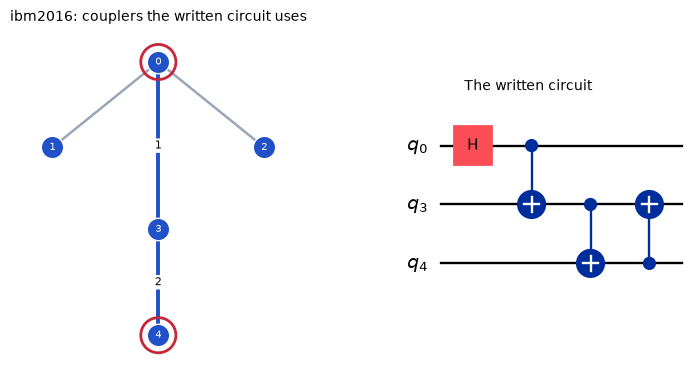


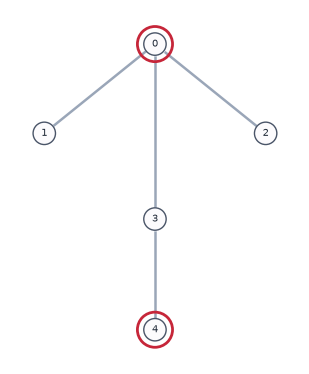
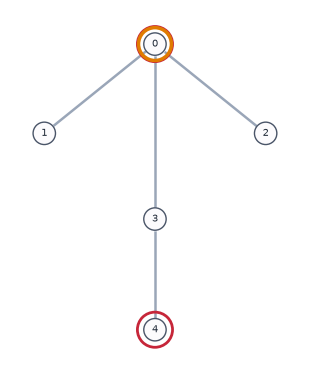
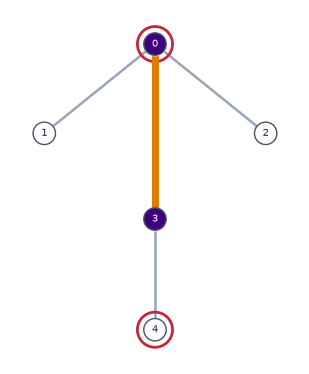
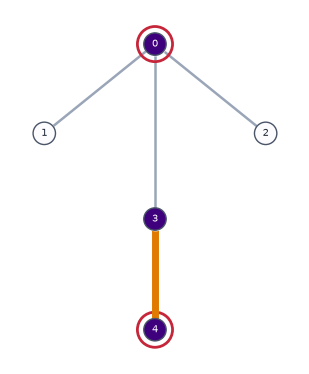
...
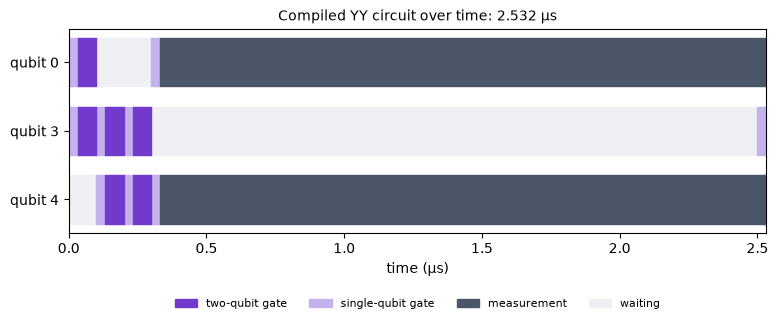
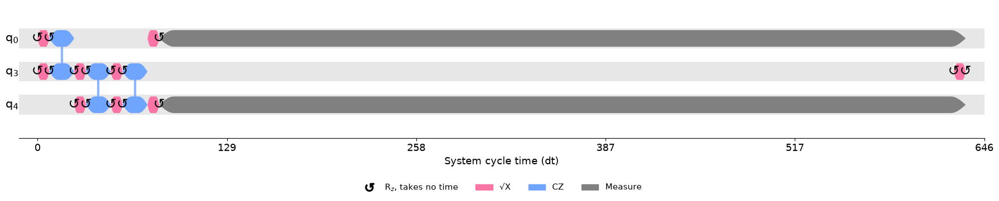
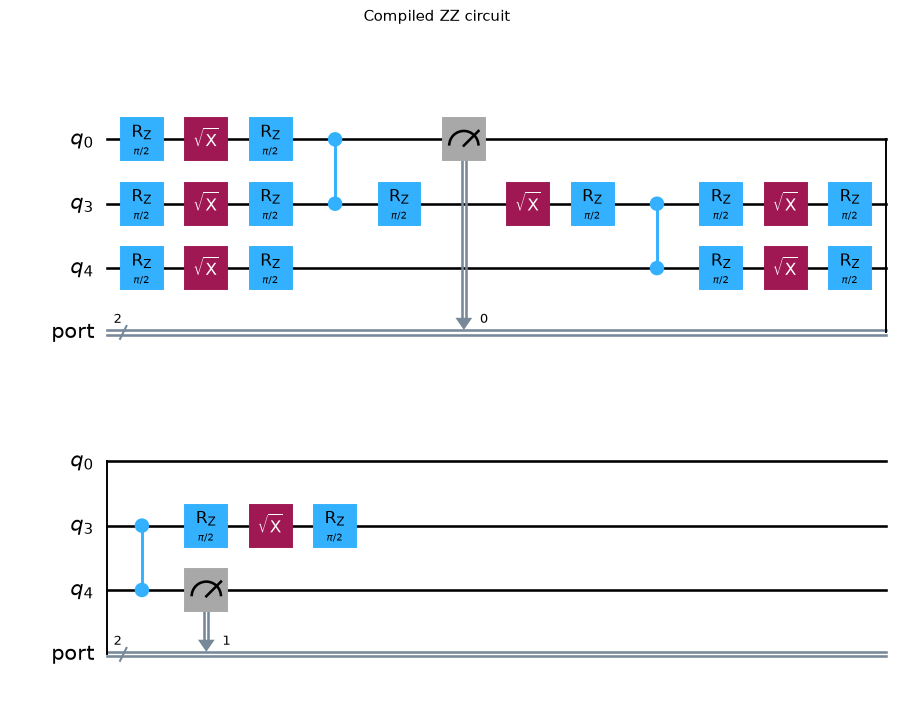
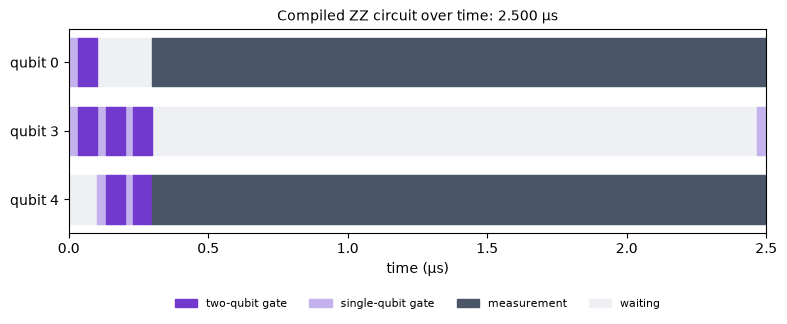
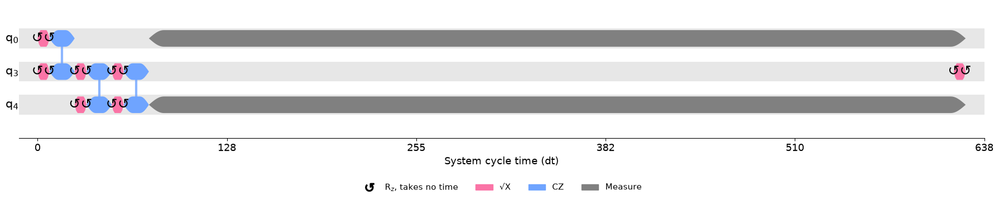

In [33]:
circuit_views("move-chain-ibm2016", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.ghz-measure-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-measure-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-measure-ibm2016.yaml

name: ghz-measure-ibm2016
label: ghz_measure, ibm2016
processor: ibm2016
analysis:
  name: parity
  settings:
    checks: []
    frame_z:
    - frame_z_ghz[0]
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: ghz_measure(reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[1] frame_z_ghz;
  qubit[5] q;
  h q[3];
  cx q[3], q[4];
  cx q[3], q[0];
  h q[3];
  frame_z_ghz[0] = measure q[3];
```

</details>

**ghz-measure-ibm2016**: ghz_measure, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `parity`, 0 check groups, frame frame_z · compiled now under boston-2026, base seed 20261116

Cost: 2 two-qubit gates · 0 SWAPs (0 by the router) · depth 8 · 3 qubits (0, 3, 4) · 2.400 µs · pair on the ports ✓

,h,cx,rz,sx,cz,measure
written,2,2,0,0,0,1
compiled ZZ,0,0,12,6,2,3
compiled XX,0,0,8,4,2,3
compiled YY,0,0,12,6,2,3

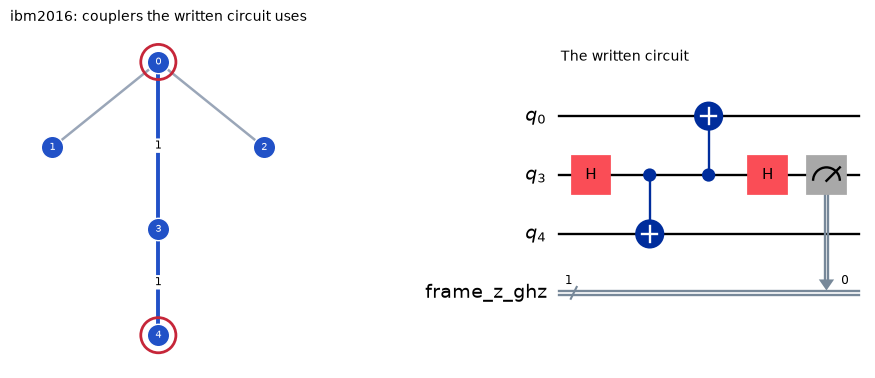


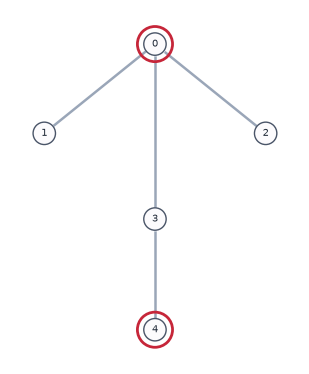
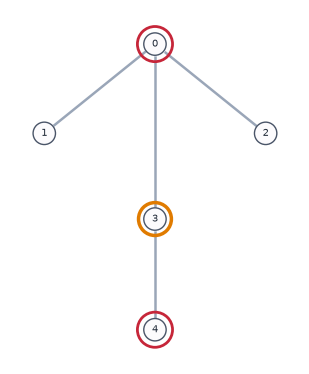
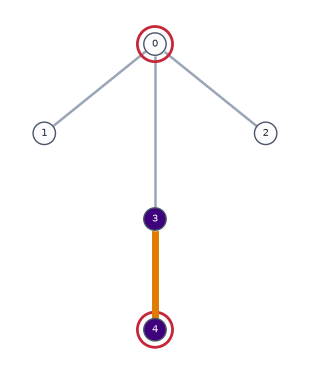
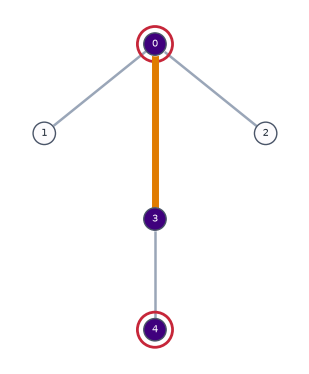
...
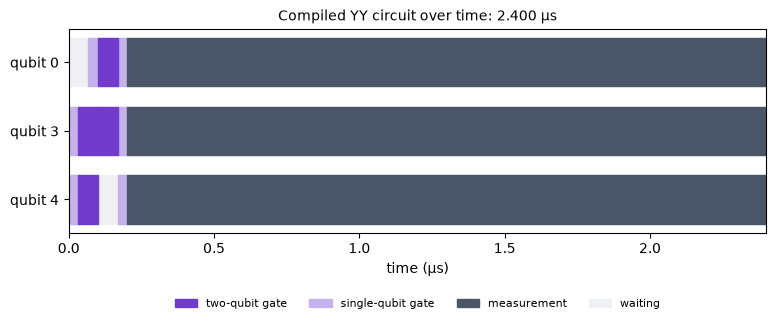
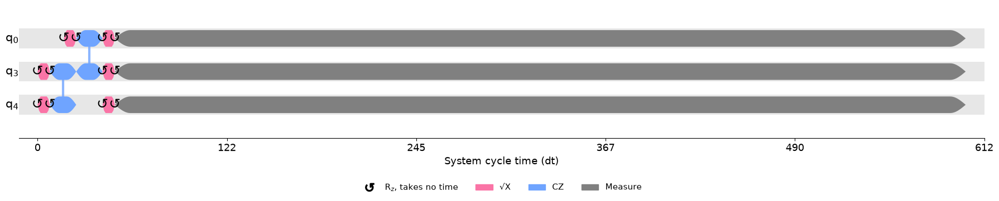
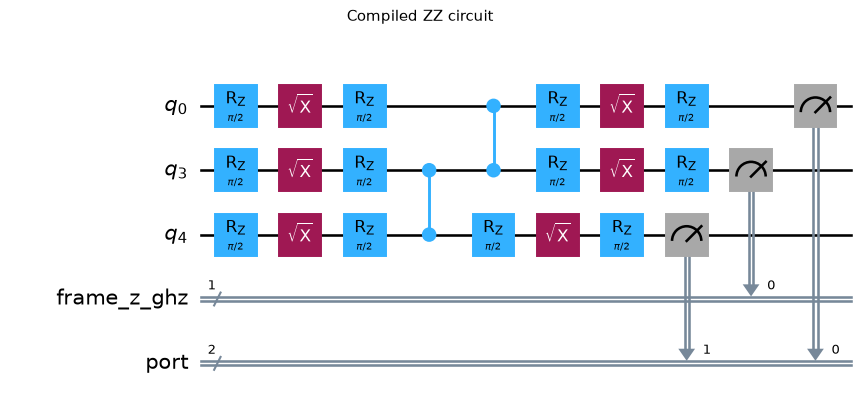
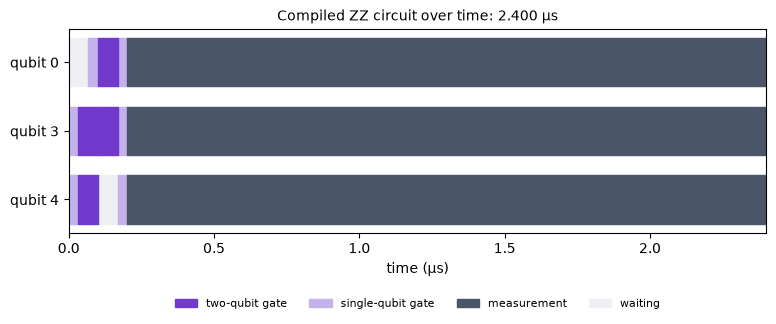
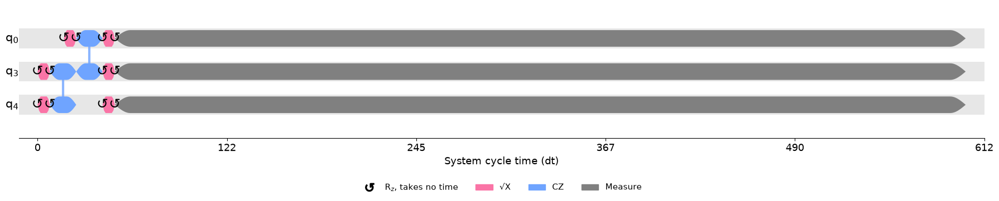

In [34]:
circuit_views("ghz-measure-ibm2016", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-vacancy-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-vacancy-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-vacancy-ibm2016.yaml

name: move-chain-vacancy-ibm2016
label: move_chain then vacancy at the end, ibm2016
processor: ibm2016
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: move_chain();
  then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[1] check_vac;
  qubit[5] q;
  h q[0];
  cx q[0], q[3];
  cx q[3], q[4];
  cx q[4], q[3];
  check_vac[0] = measure q[3];
```

</details>

**move-chain-vacancy-ibm2016**: move_chain then vacancy at the end, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `parity`, 1 check group · compiled now under boston-2026, base seed 20261116

Cost: 3 two-qubit gates · 0 SWAPs (0 by the router) · depth 15 · 3 qubits (0, 3, 4) · 2.532 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,3,1,0,0,0,1
compiled ZZ,0,0,14,7,3,3
compiled XX,0,0,18,9,3,3
compiled YY,0,0,16,9,3,3

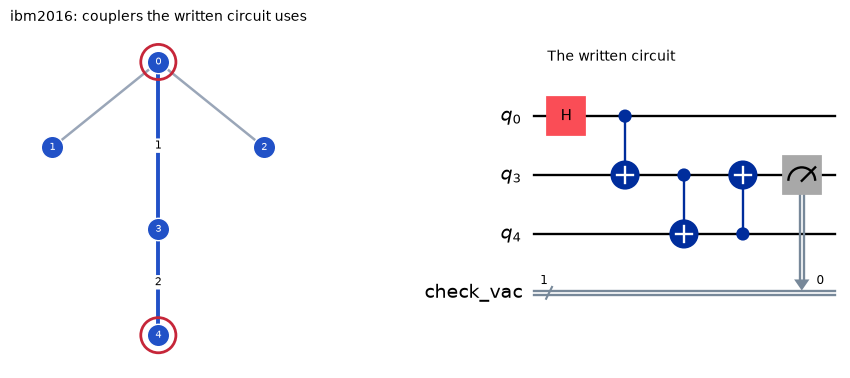


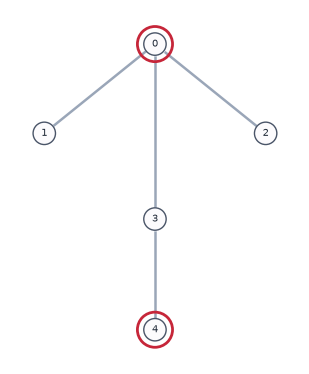
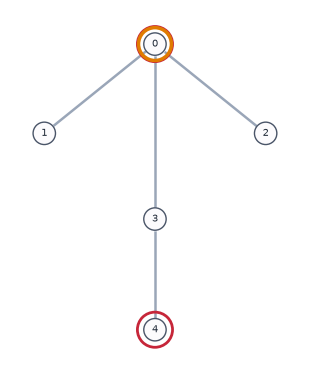
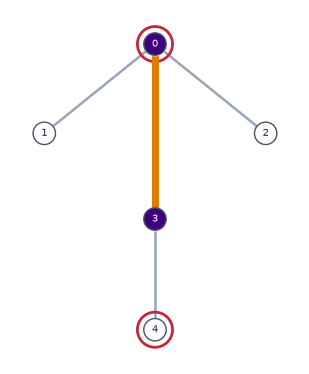
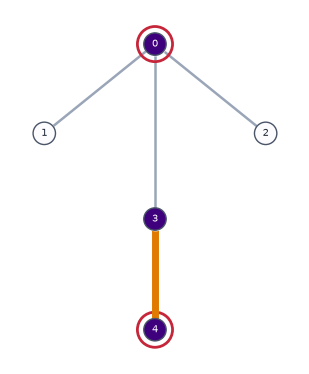
...
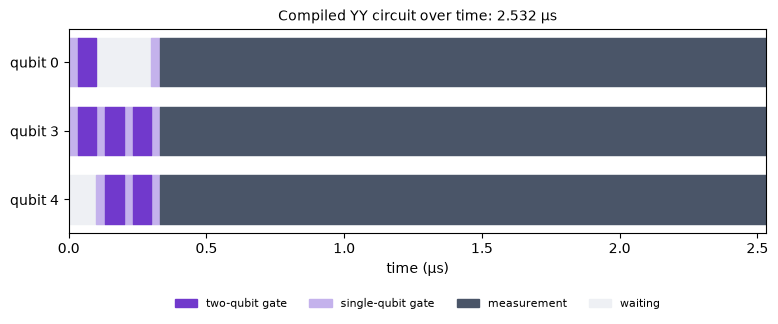
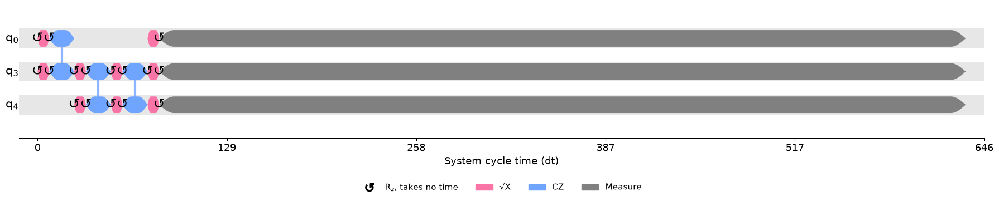
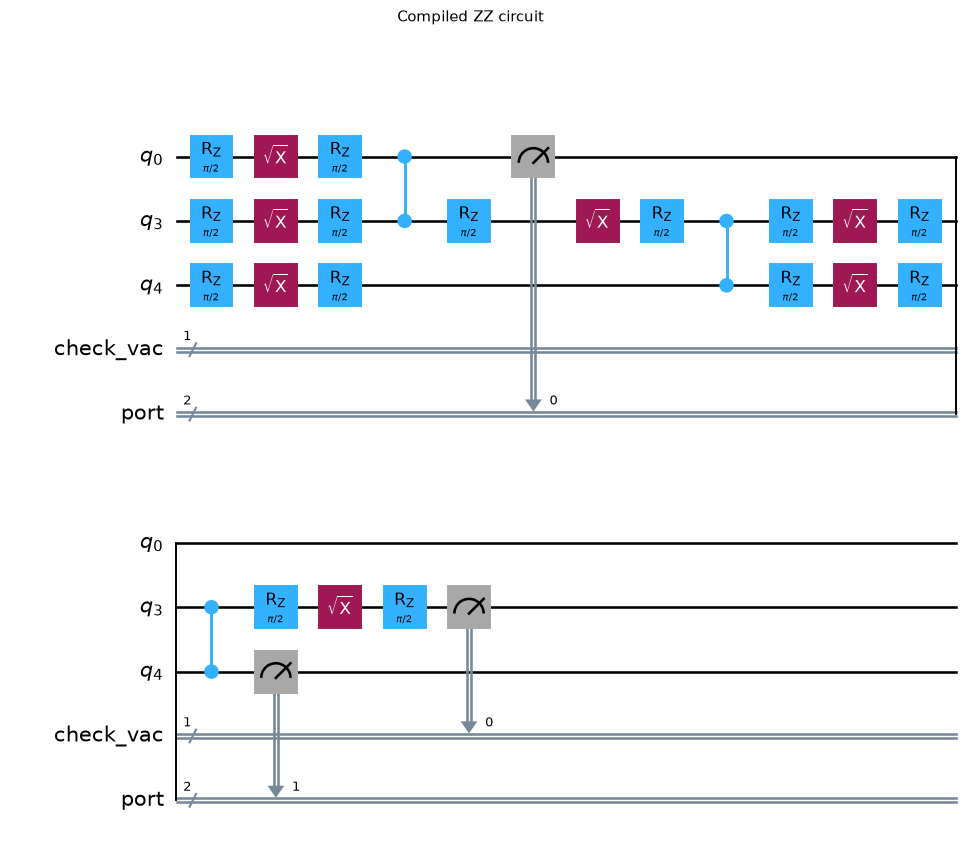
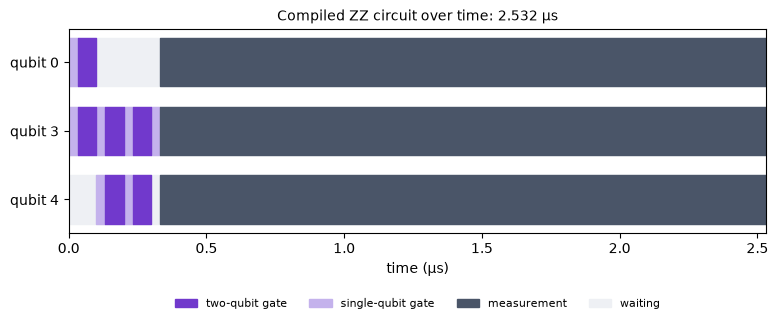
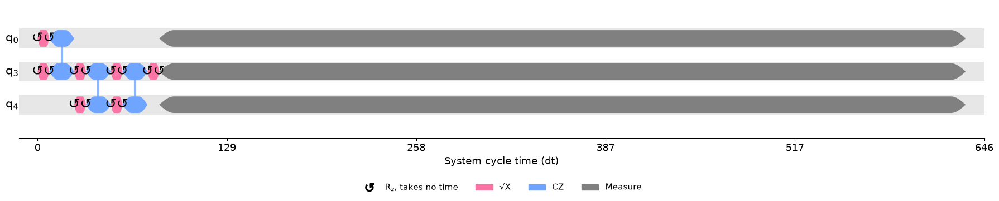

In [35]:
circuit_views("move-chain-vacancy-ibm2016", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-path-xx-ibm2016.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-path-xx-ibm2016.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-path-xx-ibm2016.yaml

name: move-chain-path-xx-ibm2016
label: move_chain then bus_xx on the path, ibm2016
processor: ibm2016
analysis:
  name: parity
  settings:
    checks:
    - - check_vac_xx[0]
    - - check_xx[0]
notes: >-
  Built by src/bellbench/builders.py on ibm2016 along the path [0, 3, 4]: move_chain();
  then bus_xx(reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[1] check_vac_xx;
  bit[1] check_xx;
  qubit[5] q;
  h q[0];
  cx q[0], q[3];
  cx q[3], q[4];
  cx q[4], q[3];
  check_vac_xx[0] = measure q[3];
  h q[3];
  cx q[3], q[0];
  cx q[3], q[4];
  h q[3];
  check_xx[0] = measure q[3];
```

</details>

**move-chain-path-xx-ibm2016**: move_chain then bus_xx on the path, ibm2016  
ibm2016, ports 0 and 4, 2 hops · read by `parity`, 2 check groups · compiled now under boston-2026, base seed 20261116

Cost: 5 two-qubit gates · 0 SWAPs (0 by the router) · depth 23 · 3 qubits (0, 3, 4) · 4.932 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,5,3,0,0,0,2
compiled ZZ,0,0,26,13,5,4
compiled XX,0,0,22,11,5,4
compiled YY,0,0,26,13,5,4

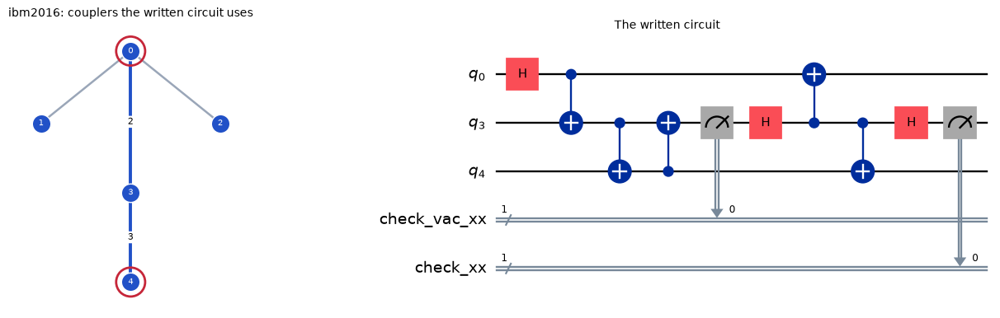


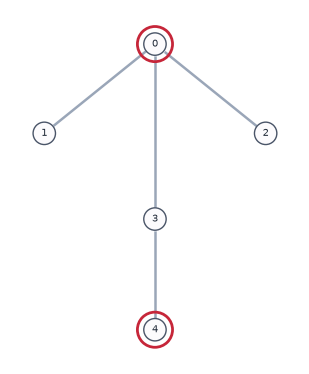
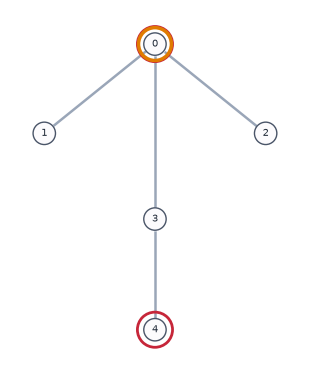
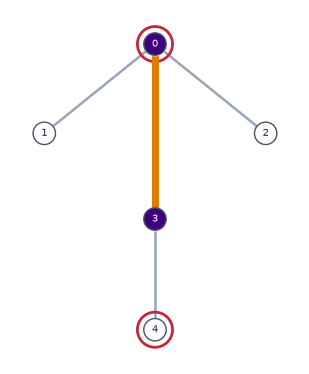
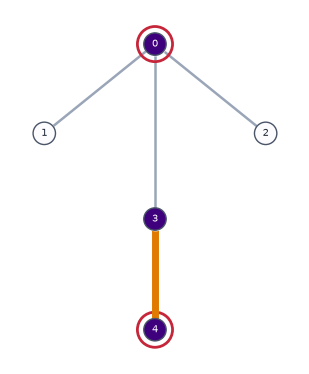
...
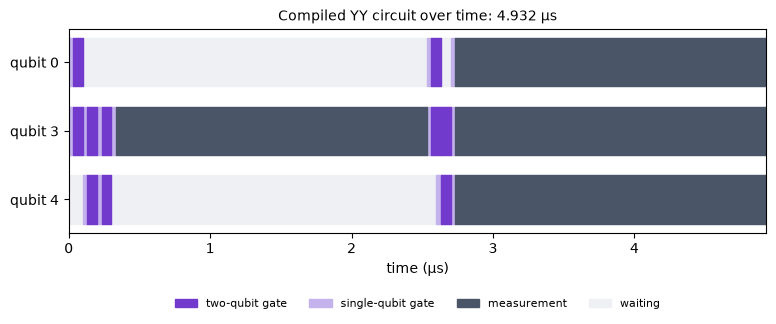
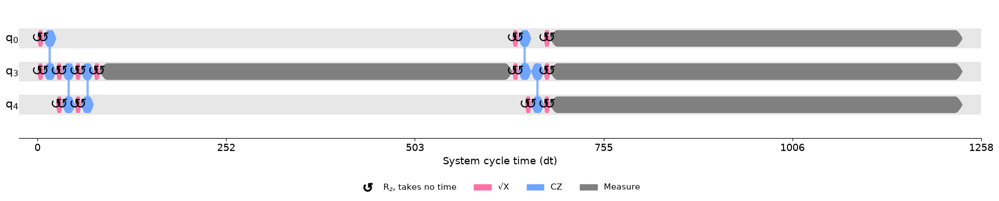
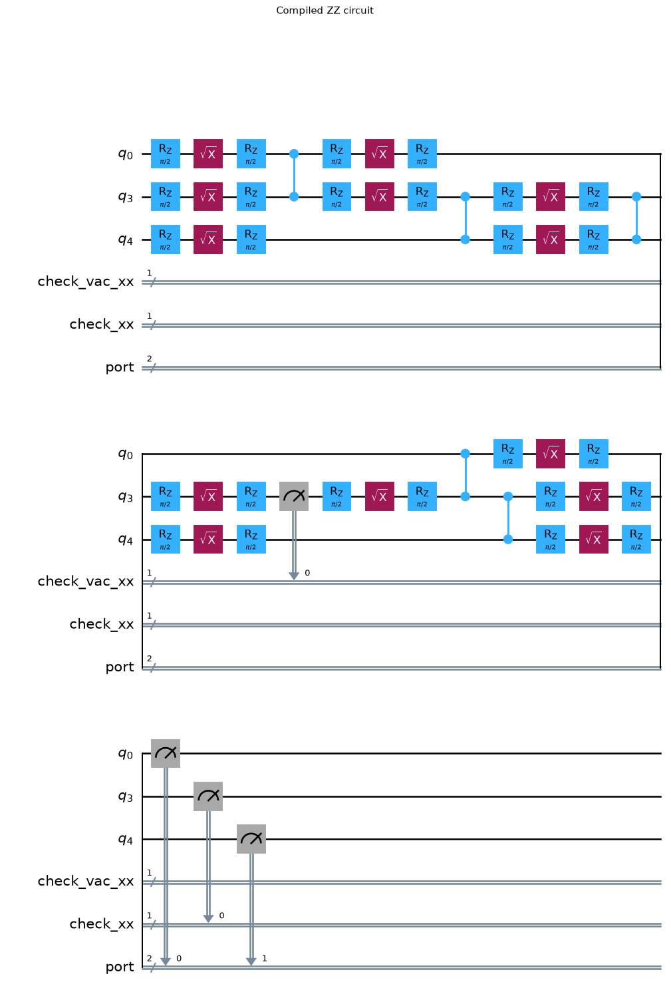
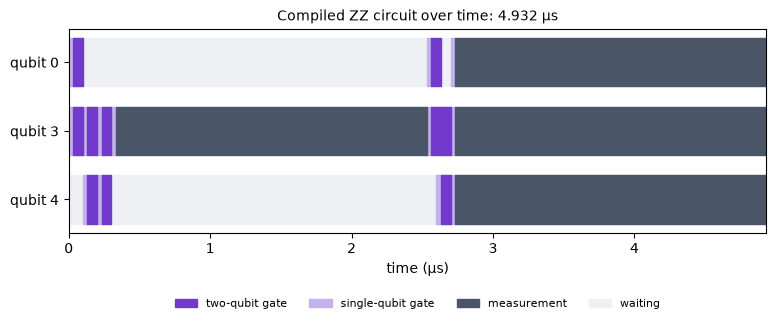
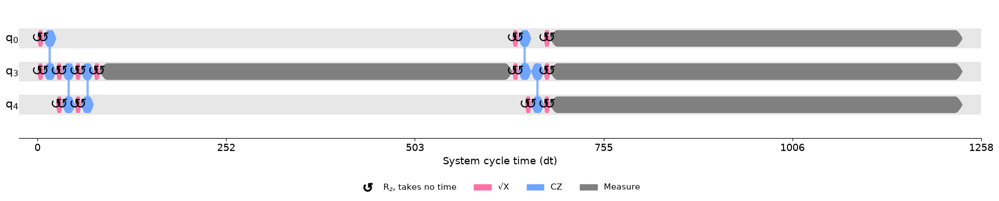

In [36]:
circuit_views("move-chain-path-xx-ibm2016", folded=True)

With every file the deliverable-2026-11-17-extended-ibm2016 benchmark uses shown, the notebook makes it, draws each run's F, and sets each run beside the run the repository recorded.

made 8 runs of deliverable-2026-11-17-extended-ibm2016: baseline-ibm2016, move-chain-ibm2016, ghz-measure-ibm2016, ghz-measure-ibm2016-readout-0, ghz-uncompute-ibm2016, move-chain-vacancy-ibm2016, ghz-uncompute-vacancy-ibm2016, move-chain-path-xx-ibm2016


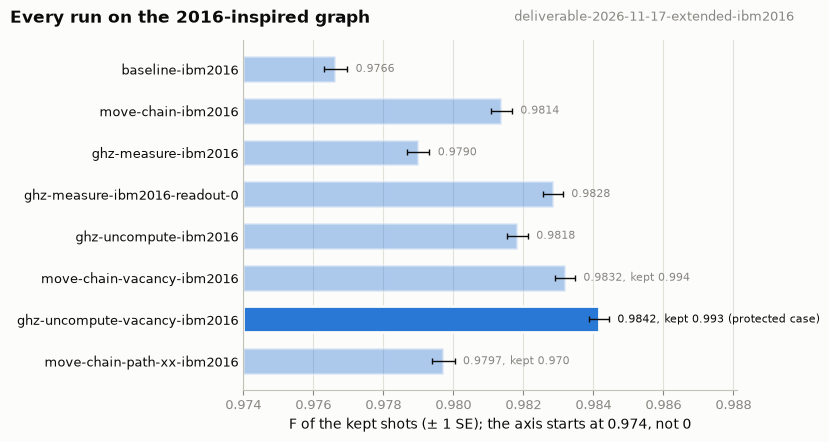

---

**Each run of deliverable-2026-11-17-extended-ibm2016 beside the run the repository recorded**

,F here,F recorded,acceptance here,acceptance recorded,identical,same files
run,,,,,,
baseline-ibm2016,0.9766,0.9766,1.000,1.000,True,True
move-chain-ibm2016,0.9814,0.9814,1.000,1.000,True,True
ghz-measure-ibm2016,0.9790,0.9790,1.000,1.000,True,True
ghz-measure-ibm2016-readout-0,0.9828,0.9828,1.000,1.000,True,True
ghz-uncompute-ibm2016,0.9818,0.9818,1.000,1.000,True,True
move-chain-vacancy-ibm2016,0.9832,0.9832,0.994,0.994,True,True
ghz-uncompute-vacancy-ibm2016,0.9842,0.9842,0.993,0.993,True,True
move-chain-path-xx-ibm2016,0.9797,0.9797,0.970,0.970,True,True


every run identical to its record, counts, circuits and numbers
provenance that differs, not counted: commit


In [37]:
make("deliverable-2026-11-17-extended-ibm2016")
ladder("deliverable-2026-11-17-extended-ibm2016")
beside_record("deliverable-2026-11-17-extended-ibm2016")

### 6.2 The contemporary graph

**The vacancy read raised GHZ disentangling by +0.0073 (15.5 SE), and the move chain by less, +0.0045 (9.5 SE).**

- **Against the move chain:** without a read the two transports agree within 1.0 combined standard errors; with the read, the protected case is ahead by +0.0022 (5.0 SE).
- **Against the earlier protected case:** +0.0020 (4.5 SE), keeping 97.7% of shots against 97.5%, with 7 two-qubit gates against 11.
- **With a spare-path XX check after the read:** F moves by +0.0010 (2.2 SE) at an acceptance of 0.956, with 4 more two-qubit gates.
- **Why the protected case leaves it out:** the check discards 2.2% more of the shots, keeping 95.6% against 97.7%, for +0.0010 (2.2 SE). Per extra discarded shot it gains 0.04 in F, where the read gains 0.32 per discarded shot, and it adds 3 qubits. Its check also runs through the graph's five-edge qubit, whose extra error the model leaves out, so the model, if anything, favours this check.

| Run | F ± SE | Acceptance | Two-qubit gates | Against the protected case |
|---|---|---|---|---|
| baseline-contemporary | 0.9600 ± 0.0004 | 1.000 | 19 | -0.0217 (-40.5 SE) |
| move-chain-contemporary | 0.9749 ± 0.0004 | 1.000 | 7 | -0.0068 (-14.6 SE) |
| ghz-measure-contemporary | 0.9663 ± 0.0004 | 1.000 | 4 | -0.0154 (-30.4 SE) |
| ghz-measure-contemporary-readout-0 | 0.9803 ± 0.0003 | 1.000 | 4 | -0.0014 (-3.3 SE) |
| ghz-uncompute-contemporary | 0.9745 ± 0.0004 | 1.000 | 7 | -0.0073 (-15.5 SE) |
| move-chain-vacancy-contemporary | 0.9795 ± 0.0003 | 0.981 | 7 | -0.0022 (-5.0 SE) |
| ghz-uncompute-vacancy-contemporary | 0.9817 ± 0.0003 | 0.977 | 7 | the protected case |
| move-chain-spare-xx-contemporary | 0.9797 ± 0.0003 | 0.975 | 11 | -0.0020 (-4.5 SE) |
| ghz-uncompute-vacancy-spare-xx-contemporary | 0.9827 ± 0.0003 | 0.956 | 11 | +0.0010 (2.2 SE) |

<details><summary><b>config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-contemporary.yaml

name: deliverable-2026-11-17-extended-contemporary
label: Contemporary, the protected case beside its alternatives
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): on the contemporary graph, the deliverable's protected case,
  case 6, beside the circuits that differ from it by one step, so each comparison
  shows what one change buys. The rungs, each a builder call along the baseline's path
  [0, 1, 2, 3, 7]: the organisers' baseline; the move chain, which moves the pair with
  two CX gates a hop instead of a SWAP's three; ghz_measure, the textbook GHZ
  transport, which reads the interior qubits in X and owes a Z on the first port for
  each 1; ghz_uncompute, which empties the interior with gates instead; ghz_measure
  again with no readout error on the interior qubits it reads, an override only this
  run takes, which shows whether readout error alone decides between the two GHZ
  transports; each of the two empty transports followed by a vacancy read at the end,
  where only ghz_uncompute's last gate makes the read catch a bit flip on the first
  port; and two XX checks on a spare path that shares no qubit with the pair's: the
  move-chain benchmark's case 6, the move chain with the check, and ghz_uncompute with
  its vacancy read followed by the check, which trades discarded shots for F. Both XX
  buses on this graph pass through its five-edge qubit, so their numbers are without
  the planned degree penalty (docs/DESIGN.md, section 4). Every run takes the
  deliverable's noise profile, shots and base seed, so the runs it shares with the
  deliverable repeat its numbers exactly; the runs it shares with the move-chain
  benchmark, which takes 20,000 shots, agree with them within their errors.
shots: 100000
base_seed: 20261116
runs:
  # The reference: the organisers' baseline.
  - {run: baseline-contemporary, circuit: baseline-contemporary, noise: boston-2026}
  # The transports alone, with no check.
  - {run: move-chain-contemporary, circuit: move-chain-contemporary, noise: boston-2026}
  - {run: ghz-measure-contemporary, circuit: ghz-measure-contemporary, noise: boston-2026}
  # ghz_measure with no readout error on the interior qubits [1, 2, 3], the only run here that changes the profile.
  - {run: ghz-measure-contemporary-readout-0, circuit: ghz-measure-contemporary, noise: boston-2026, overrides: [{qubits: 1, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 1, field: qubit.readout_error.reads_0_when_1, value: 0.0}, {qubits: 2, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 2, field: qubit.readout_error.reads_0_when_1, value: 0.0}, {qubits: 3, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 3, field: qubit.readout_error.reads_0_when_1, value: 0.0}]}
  - {run: ghz-uncompute-contemporary, circuit: ghz-uncompute-contemporary, noise: boston-2026}
  # A vacancy read at the end after each transport that empties the path; the second is the deliverable's protected case.
  - {run: move-chain-vacancy-contemporary, circuit: move-chain-vacancy-contemporary, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-contemporary, circuit: ghz-uncompute-vacancy-contemporary, noise: boston-2026}
  # XX checks on a spare path: the move-chain benchmark's case 6, then the vacancy read followed by the check.
  - {run: move-chain-spare-xx-contemporary, circuit: move-chain-spare-xx-contemporary, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-spare-xx-contemporary, circuit: ghz-uncompute-vacancy-spare-xx-contemporary, noise: boston-2026}
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-chain-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-contemporary.yaml

name: move-chain-contemporary
label: move_chain, contemporary
processor: contemporary
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  move_chain().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[1];
  cx q[2], q[3];
  cx q[3], q[2];
  cx q[3], q[7];
  cx q[7], q[3];
```

</details>

**move-chain-contemporary**: move_chain, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

Cost: 7 two-qubit gates · 0 SWAPs (0 by the router) · depth 25 · 5 qubits (0, 1, 2, 3, 7) · 2.836 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,7,1,0,0,0,0
compiled ZZ,0,0,30,15,7,2
compiled XX,0,0,34,17,7,2
compiled YY,0,0,32,17,7,2

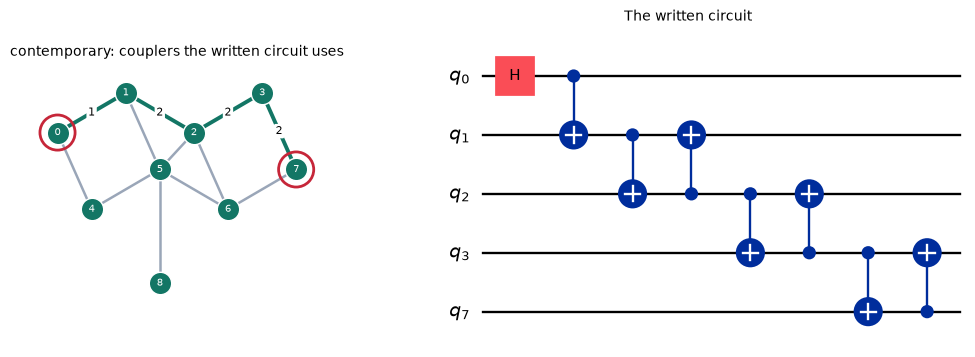


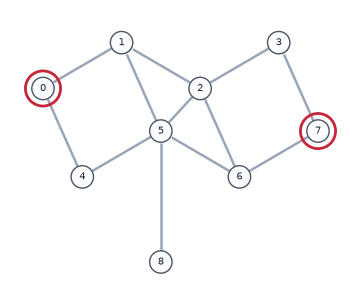
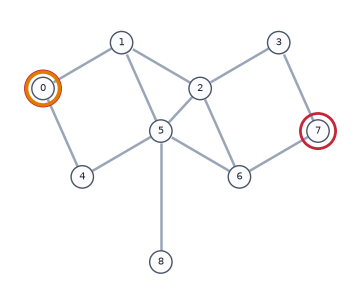
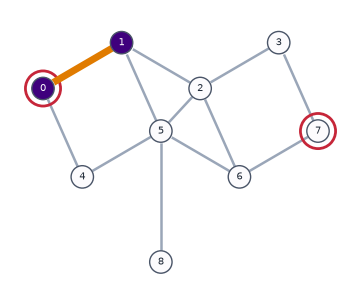
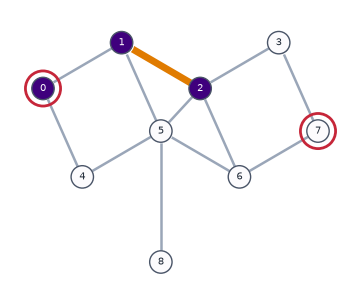
...
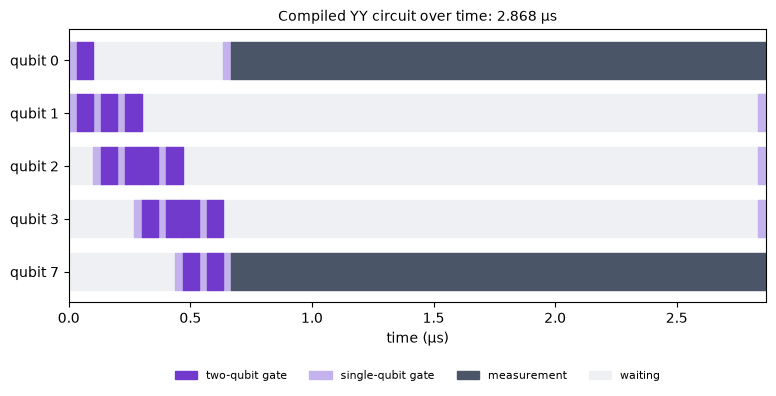
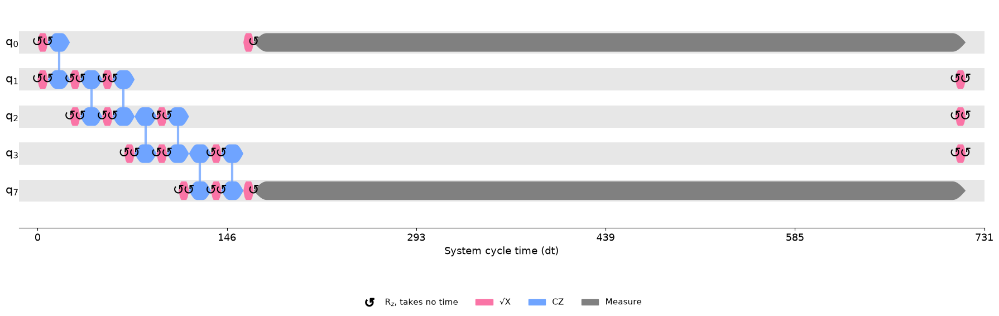
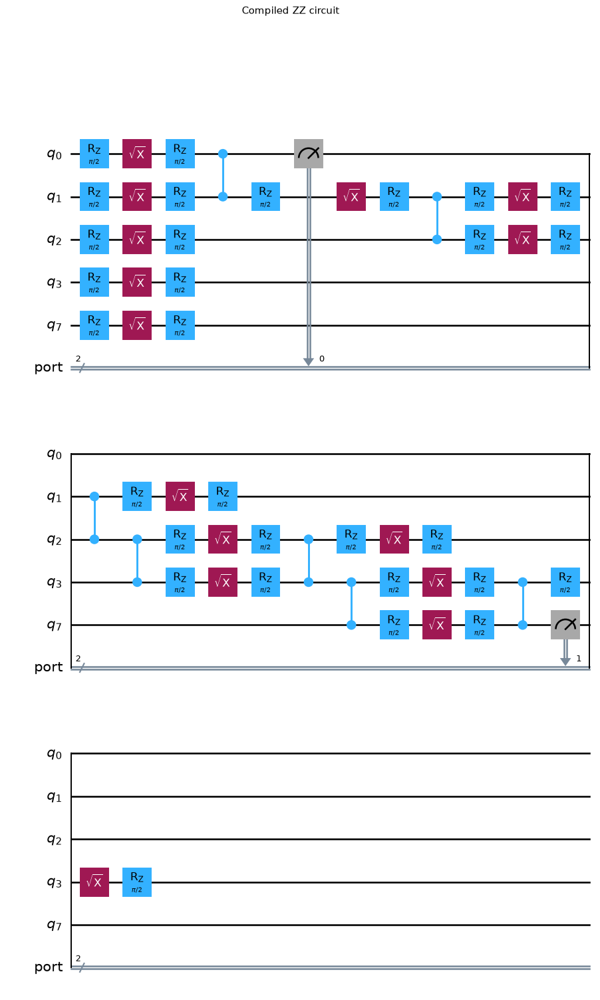
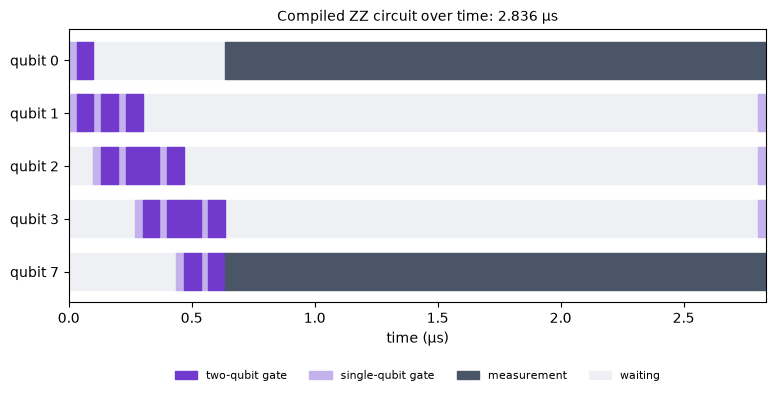
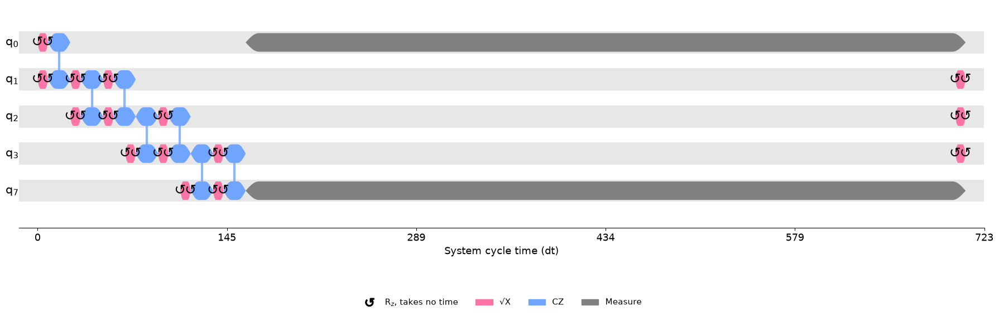

In [38]:
circuit_views("move-chain-contemporary", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.ghz-measure-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-measure-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-measure-contemporary.yaml

name: ghz-measure-contemporary
label: ghz_measure, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks: []
    frame_z:
    - frame_z_ghz[0]
    - frame_z_ghz[1]
    - frame_z_ghz[2]
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  ghz_measure(reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] frame_z_ghz;
  qubit[9] q;
  h q[2];
  cx q[2], q[3];
  cx q[3], q[7];
  cx q[2], q[1];
  cx q[1], q[0];
  h q[1];
  frame_z_ghz[0] = measure q[1];
  h q[2];
  frame_z_ghz[1] = measure q[2];
  h q[3];
  frame_z_ghz[2] = measure q[3];
```

</details>

**ghz-measure-contemporary**: ghz_measure, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `parity`, 0 check groups, frame frame_z · compiled now under boston-2026, base seed 20261116

Cost: 4 two-qubit gates · 0 SWAPs (0 by the router) · depth 12 · 5 qubits (0, 1, 2, 3, 7) · 2.500 µs · pair on the ports ✓

,h,cx,rz,sx,cz,measure
written,4,4,0,0,0,3
compiled ZZ,0,0,24,12,4,5
compiled XX,0,0,20,10,4,5
compiled YY,0,0,24,12,4,5

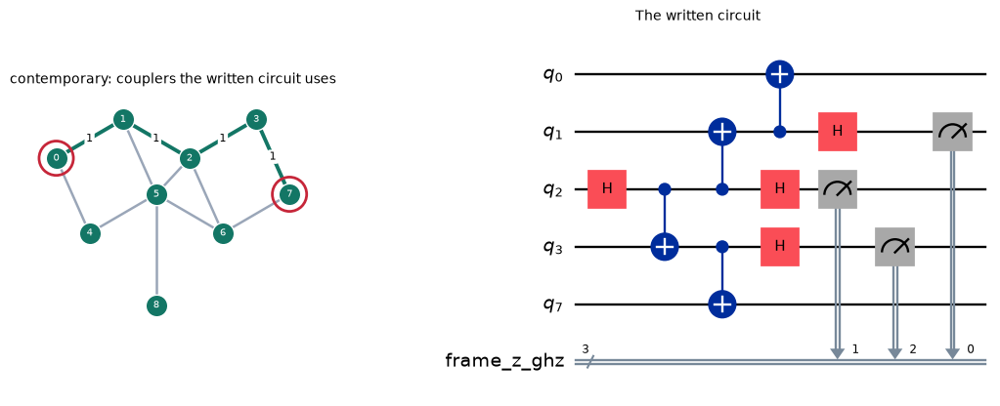


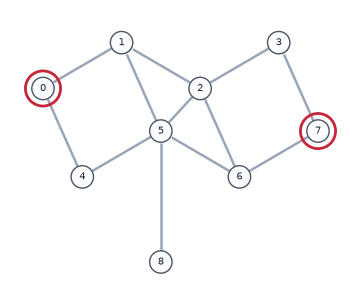
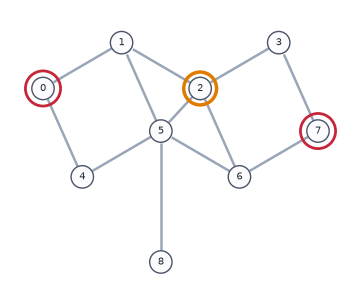
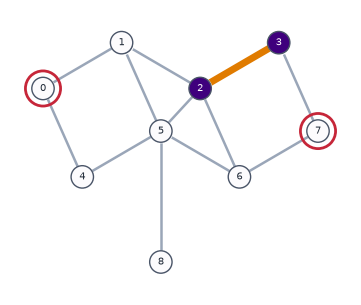
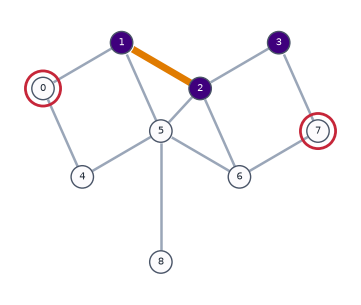
...
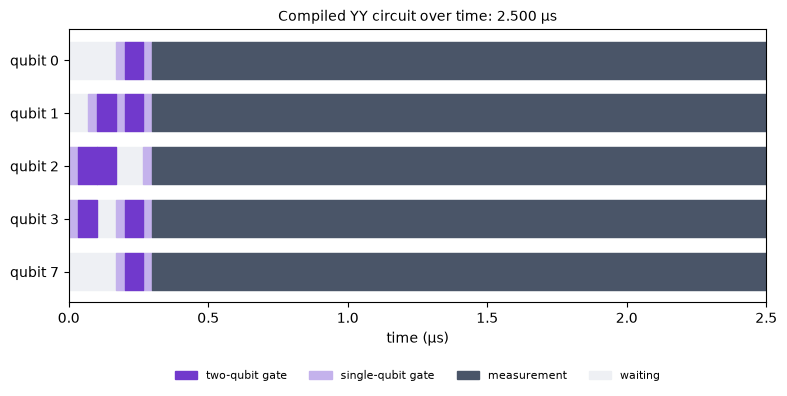
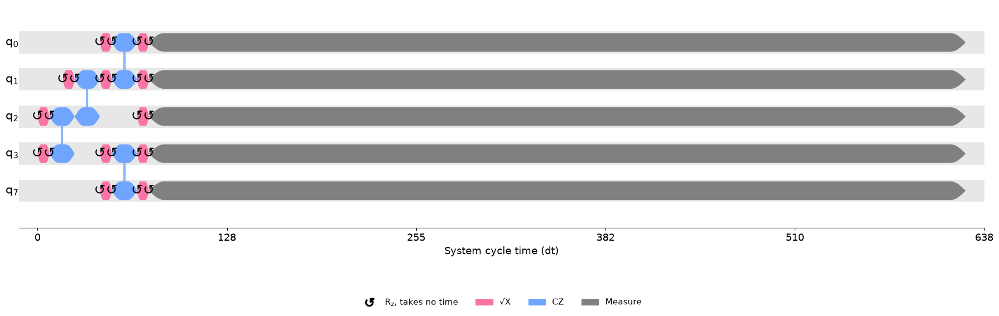
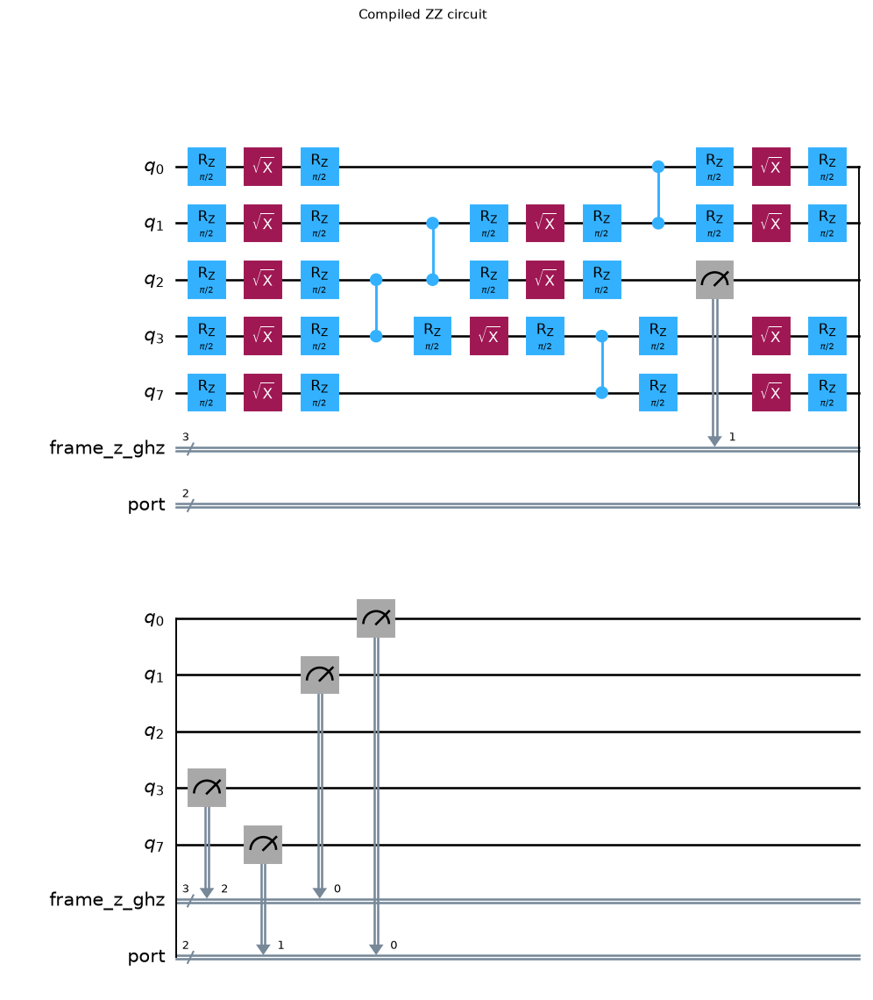
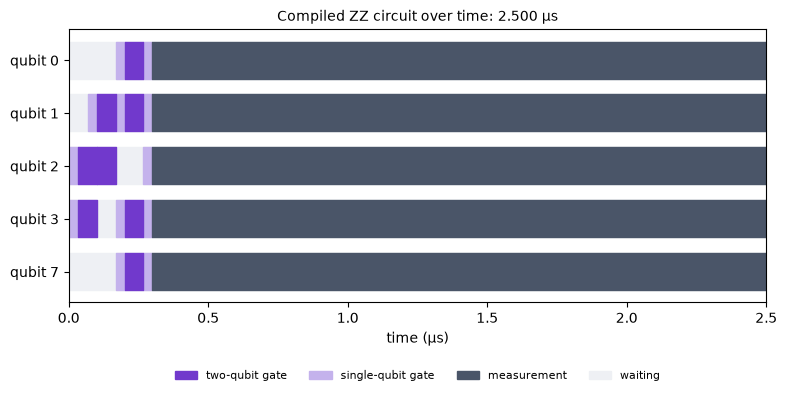
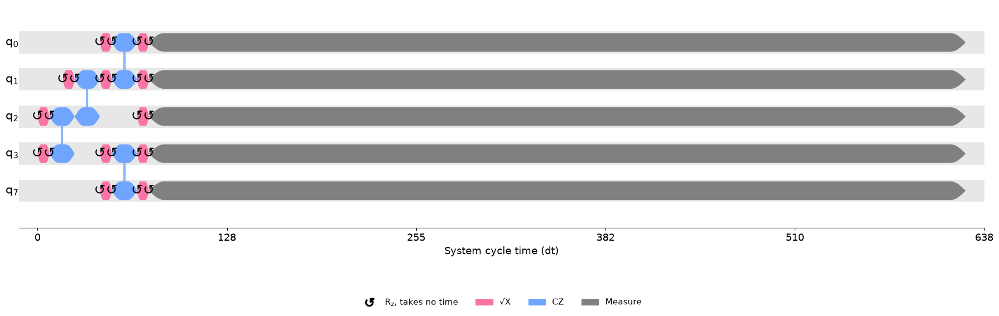

In [39]:
circuit_views("ghz-measure-contemporary", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-vacancy-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-vacancy-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-vacancy-contemporary.yaml

name: move-chain-vacancy-contemporary
label: move_chain then vacancy at the end, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
    - - check_vac[2]
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  move_chain(); then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] check_vac;
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[1];
  cx q[2], q[3];
  cx q[3], q[2];
  cx q[3], q[7];
  cx q[7], q[3];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[2];
  check_vac[2] = measure q[3];
```

</details>

**move-chain-vacancy-contemporary**: move_chain then vacancy at the end, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `parity`, 3 check groups · compiled now under boston-2026, base seed 20261116

Cost: 7 two-qubit gates · 0 SWAPs (0 by the router) · depth 25 · 5 qubits (0, 1, 2, 3, 7) · 2.868 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,7,1,0,0,0,3
compiled ZZ,0,0,30,15,7,5
compiled XX,0,0,34,17,7,5
compiled YY,0,0,32,17,7,5

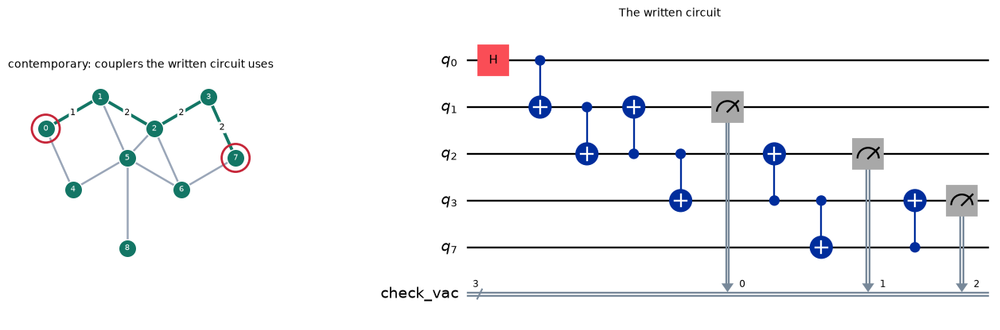


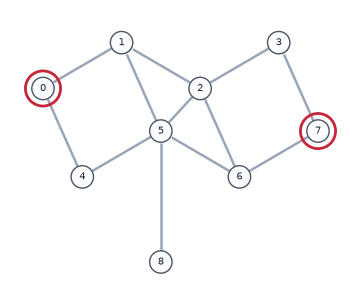
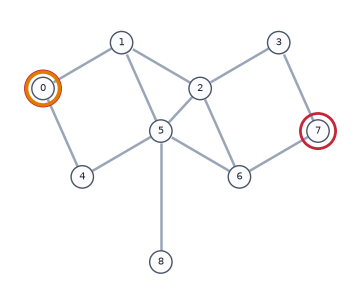
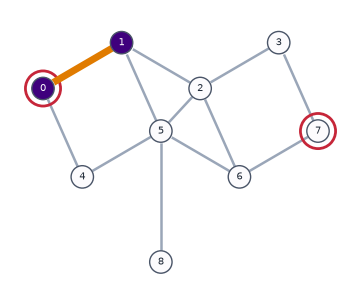
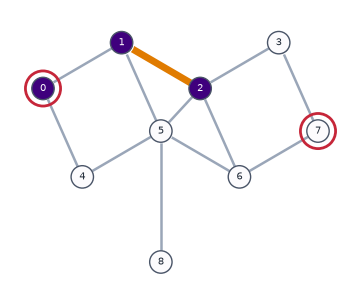
...
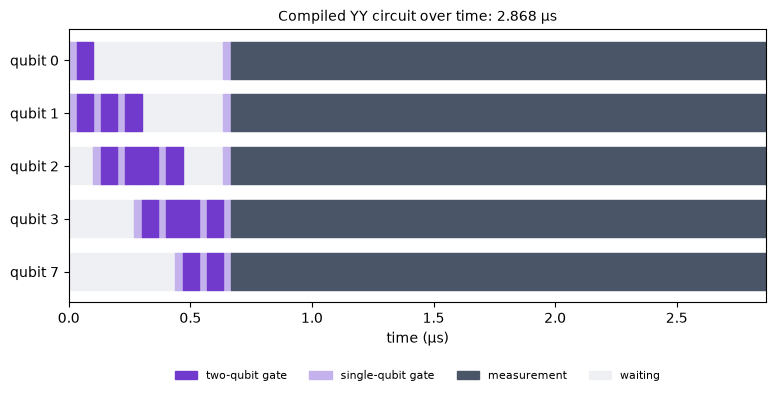
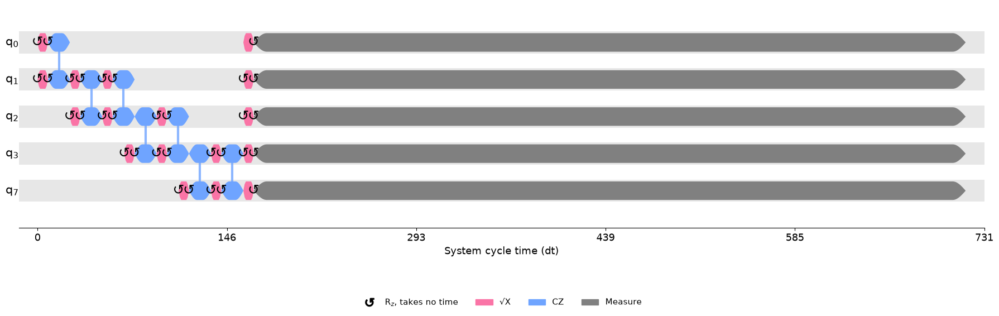
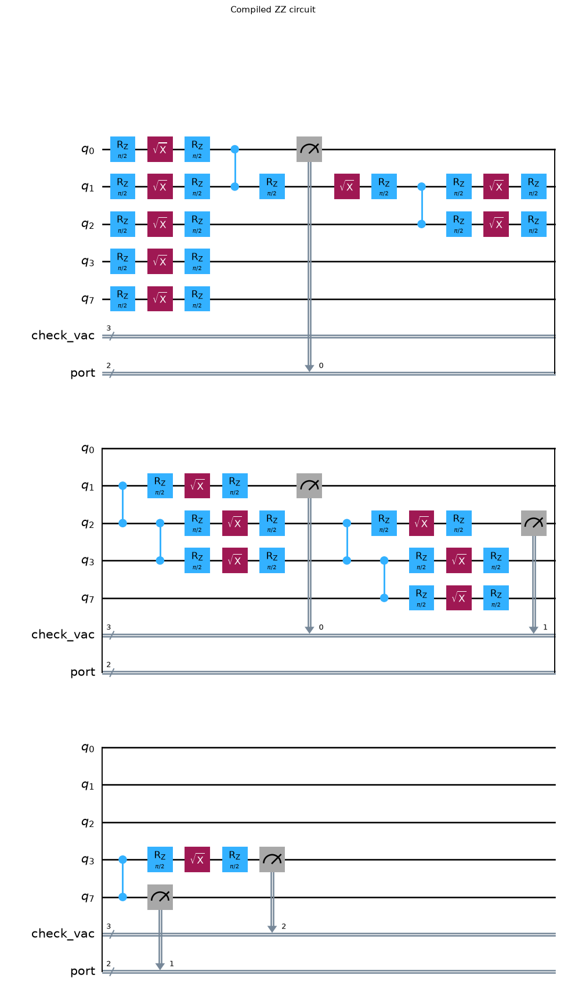
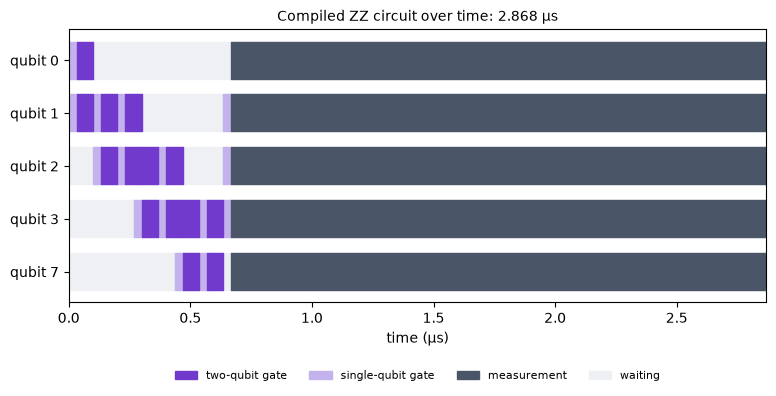
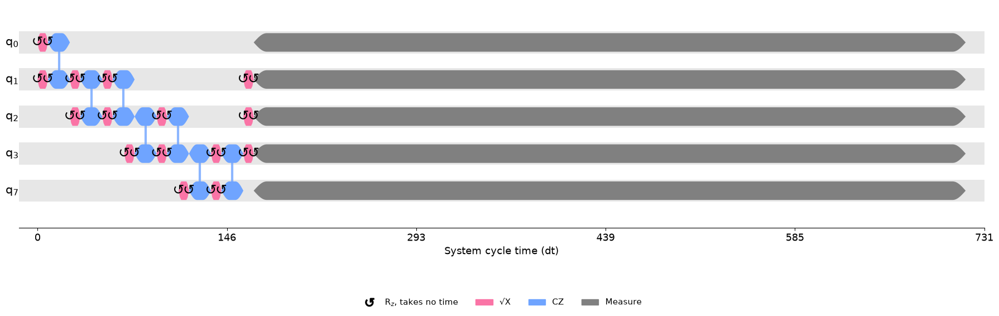

In [40]:
circuit_views("move-chain-vacancy-contemporary", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-spare-xx-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-spare-xx-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-spare-xx-contemporary.yaml

name: move-chain-spare-xx-contemporary
label: move_chain then bus_xx on a spare path, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks:
    - - check_xx[0]
      - check_xx[1]
      - check_xx[2]
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  move_chain(); then bus_xx(on=[0, 4, 5, 6, 7], reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] check_xx;
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[1];
  cx q[2], q[3];
  cx q[3], q[2];
  cx q[3], q[7];
  cx q[7], q[3];
  h q[4];
  cx q[4], q[5];
  cx q[5], q[6];
  cx q[4], q[0];
  cx q[6], q[7];
  h q[4];
  check_xx[0] = measure q[4];
  h q[5];
  check_xx[1] = measure q[5];
  h q[6];
  check_xx[2] = measure q[6];
```

</details>

**move-chain-spare-xx-contemporary**: move_chain then bus_xx on a spare path, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `parity`, 1 check group · compiled now under boston-2026, base seed 20261116

Cost: 11 two-qubit gates · 0 SWAPs (0 by the router) · depth 29 · 8 qubits (0, 1, 2, 3, 4, 5, 6, 7) · 2.968 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,11,5,0,0,0,3
compiled ZZ,0,0,54,27,11,5
compiled XX,0,0,50,25,11,5
compiled YY,0,0,54,27,11,5

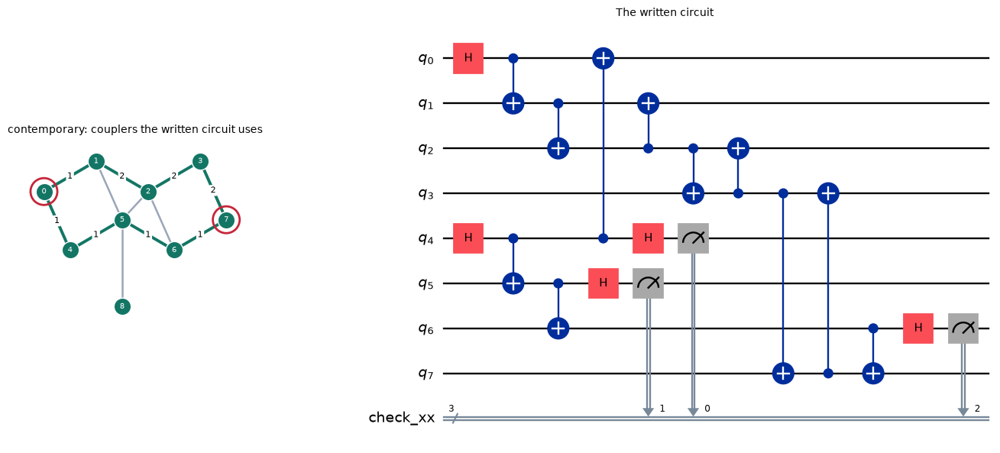


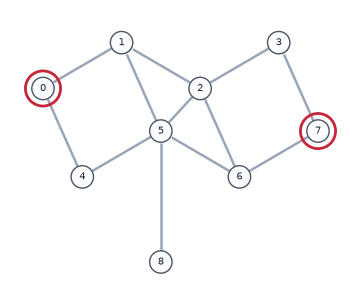
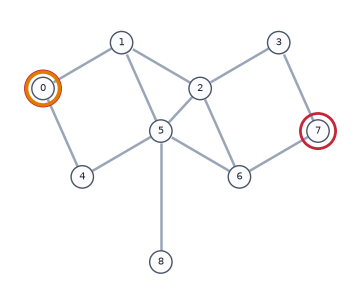
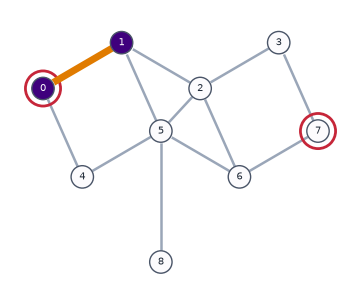
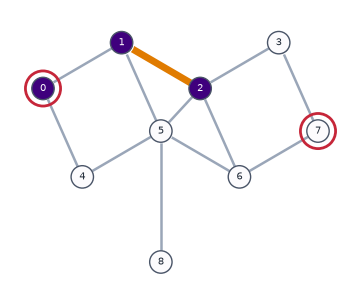
...
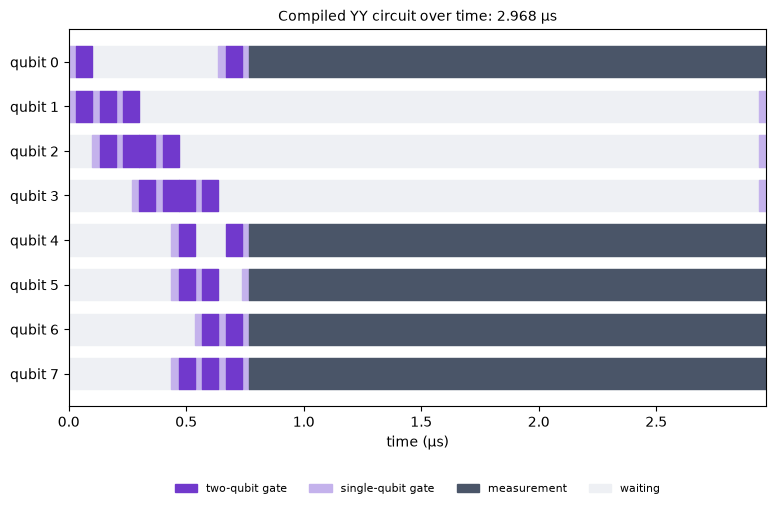
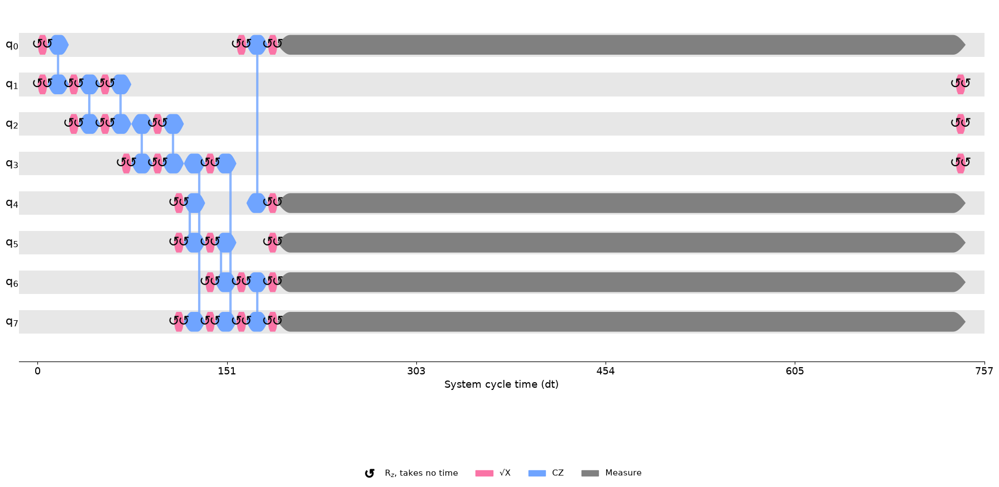
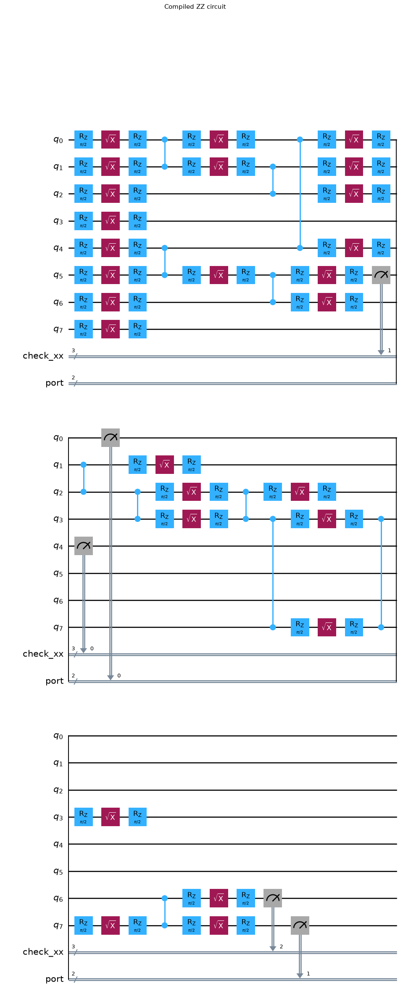
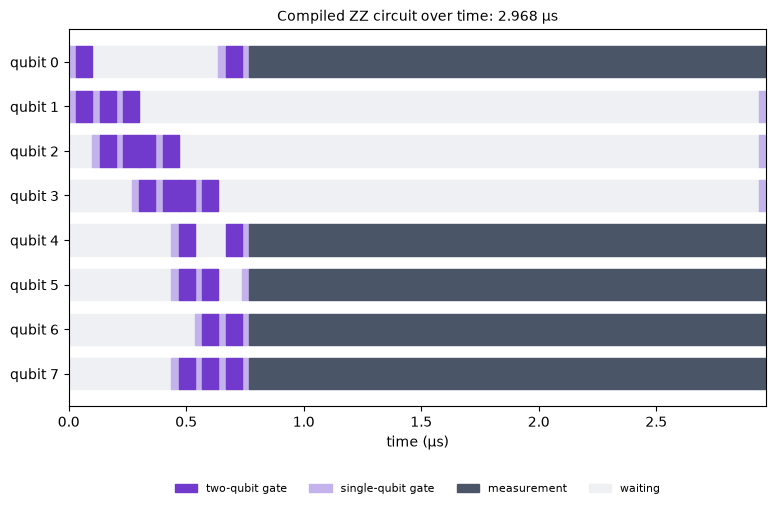
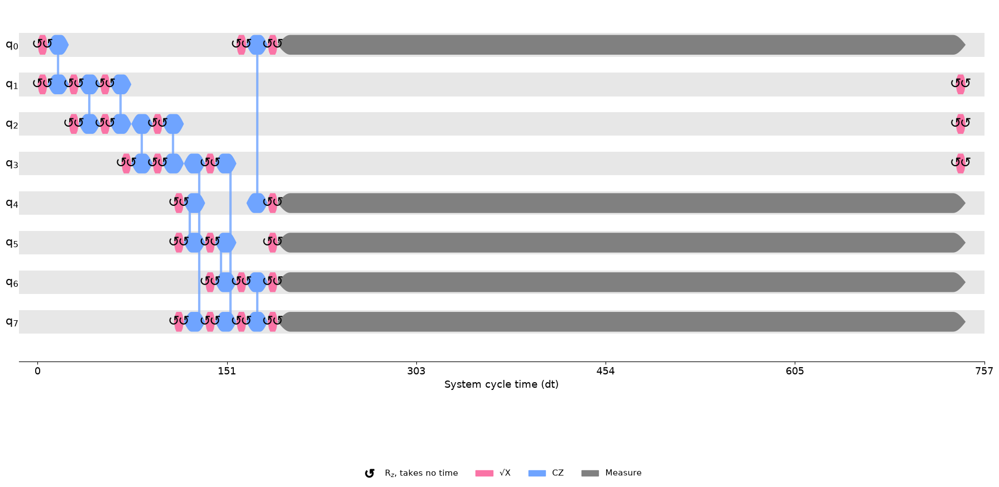

In [41]:
circuit_views("move-chain-spare-xx-contemporary", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-contemporary.yaml

name: ghz-uncompute-vacancy-spare-xx-contemporary
label: ghz_uncompute then vacancy, then bus_xx on a spare path, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
    - - check_vac[2]
    - - check_xx[0]
      - check_xx[1]
      - check_xx[2]
notes: >-
  Built by src/bellbench/builders.py on contemporary along the path [0, 1, 2, 3, 7]:
  ghz_uncompute(); then vacancy(); then bus_xx(on=[0, 4, 5, 6, 7], reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] check_vac;
  bit[3] check_xx;
  qubit[9] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[2];
  cx q[2], q[3];
  cx q[3], q[7];
  cx q[2], q[3];
  cx q[1], q[2];
  cx q[0], q[1];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[2];
  check_vac[2] = measure q[3];
  h q[4];
  cx q[4], q[5];
  cx q[5], q[6];
  cx q[4], q[0];
  cx q[6], q[7];
  h q[4];
  check_xx[0] = measure q[4];
  h q[5];
  check_xx[1] = measure q[5];
  h q[6];
  check_xx[2] = measure q[6];
```

</details>

**ghz-uncompute-vacancy-spare-xx-contemporary**: ghz_uncompute then vacancy, then bus_xx on a spare path, contemporary  
contemporary, ports 0 and 7, 4 hops · read by `parity`, 4 check groups · compiled now under boston-2026, base seed 20261116

Cost: 11 two-qubit gates · 0 SWAPs (0 by the router) · depth 35 · 8 qubits (0, 1, 2, 3, 4, 5, 6, 7) · 3.032 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,11,5,0,0,0,6
compiled ZZ,0,0,50,25,11,8
compiled XX,0,0,46,23,11,8
compiled YY,0,0,50,25,11,8

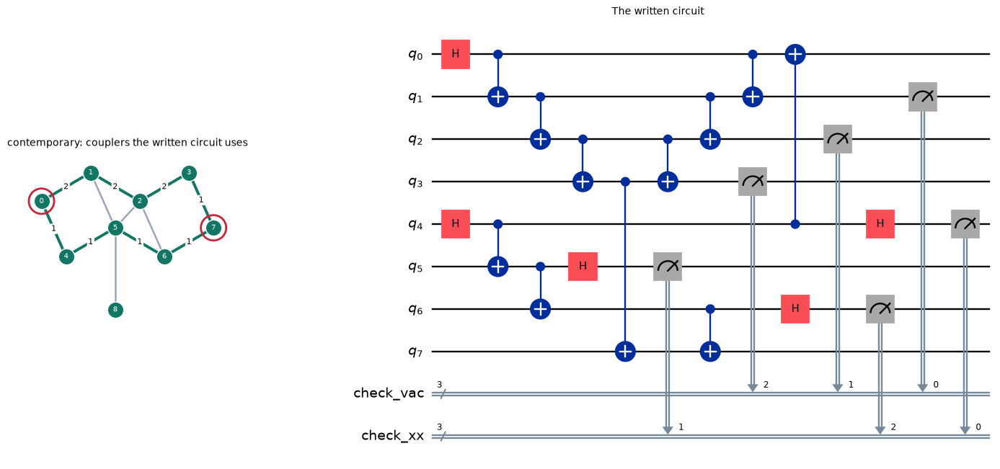


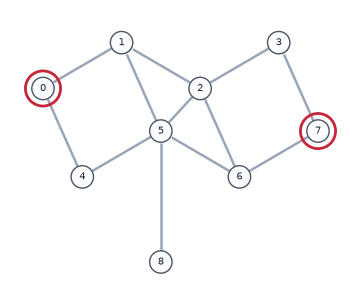
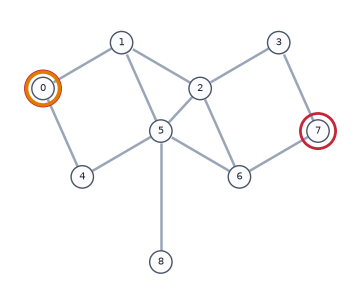
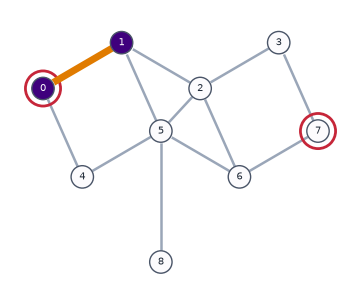
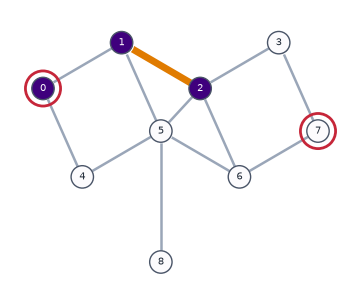
...
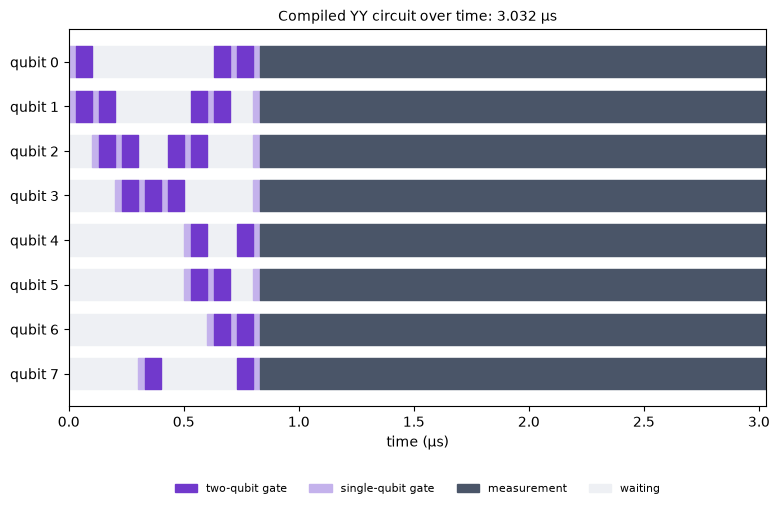
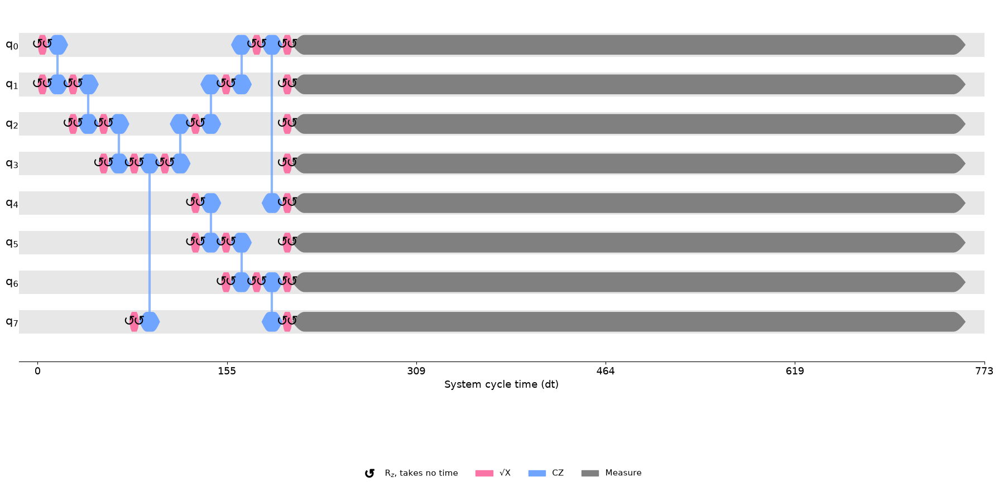
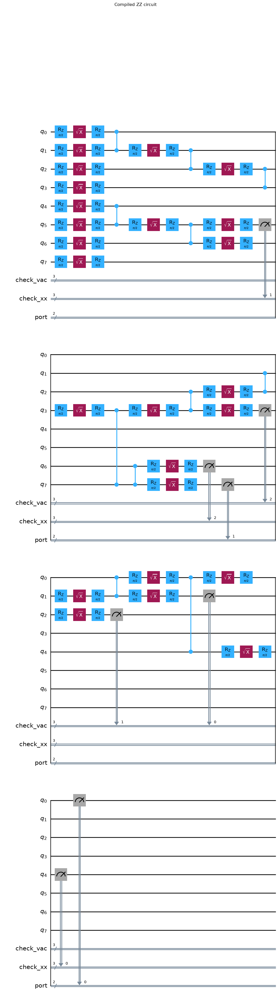
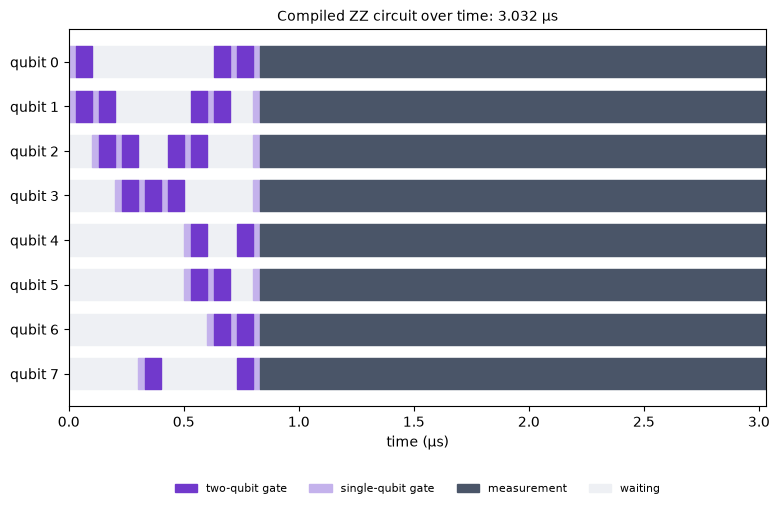
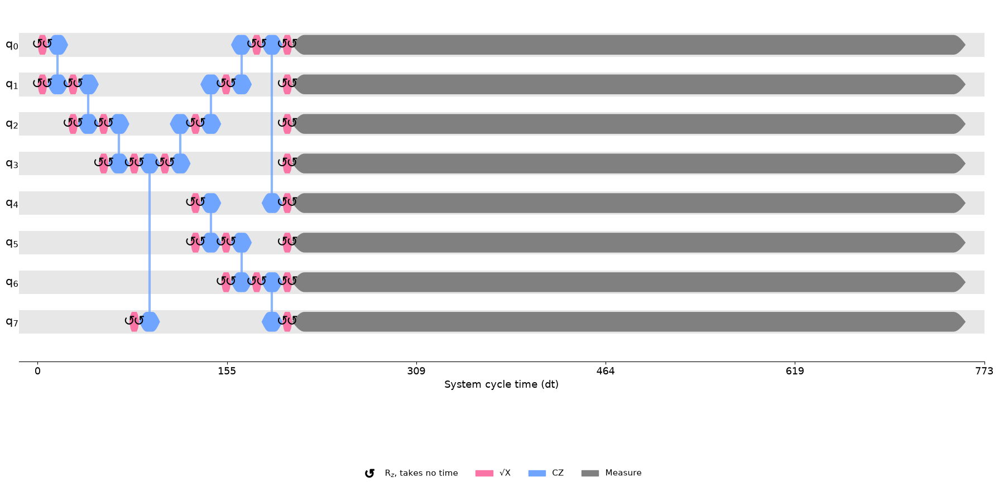

In [42]:
circuit_views("ghz-uncompute-vacancy-spare-xx-contemporary", folded=True)

With every file the deliverable-2026-11-17-extended-contemporary benchmark uses shown, the notebook makes it, draws each run's F, and sets each run beside the run the repository recorded.

made 9 runs of deliverable-2026-11-17-extended-contemporary: baseline-contemporary, move-chain-contemporary, ghz-measure-contemporary, ghz-measure-contemporary-readout-0, ghz-uncompute-contemporary, move-chain-vacancy-contemporary, ghz-uncompute-vacancy-contemporary, move-chain-spare-xx-contemporary, ghz-uncompute-vacancy-spare-xx-contemporary


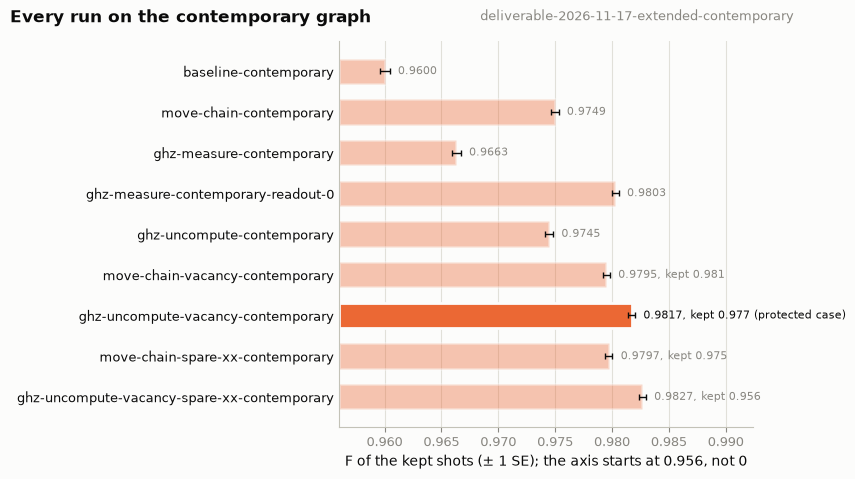

---

**Each run of deliverable-2026-11-17-extended-contemporary beside the run the repository recorded**

,F here,F recorded,acceptance here,acceptance recorded,identical,same files
run,,,,,,
baseline-contemporary,0.9600,0.9600,1.000,1.000,True,True
move-chain-contemporary,0.9749,0.9749,1.000,1.000,True,True
ghz-measure-contemporary,0.9663,0.9663,1.000,1.000,True,True
ghz-measure-contemporary-readout-0,0.9803,0.9803,1.000,1.000,True,True
ghz-uncompute-contemporary,0.9745,0.9745,1.000,1.000,True,True
move-chain-vacancy-contemporary,0.9795,0.9795,0.981,0.981,True,True
ghz-uncompute-vacancy-contemporary,0.9817,0.9817,0.977,0.977,True,True
move-chain-spare-xx-contemporary,0.9797,0.9797,0.975,0.975,True,True
ghz-uncompute-vacancy-spare-xx-contemporary,0.9827,0.9827,0.956,0.956,True,True


every run identical to its record, counts, circuits and numbers
provenance that differs, not counted: commit


In [43]:
make("deliverable-2026-11-17-extended-contemporary")
ladder("deliverable-2026-11-17-extended-contemporary")
beside_record("deliverable-2026-11-17-extended-contemporary")

### 6.3 The hyperbolic-inspired graph

**The vacancy read raised GHZ disentangling by +0.0049 (11.2 SE), and the move chain by less, +0.0026 (5.8 SE).**

- **Against the move chain:** without a read the two transports agree within 1.1 combined standard errors; with the read, the protected case is ahead by +0.0018 (4.3 SE).
- **Against the earlier protected case:** +0.0022 (5.2 SE), keeping 98.5% of shots against 98.3%, with 5 two-qubit gates against 8.
- **With a spare-path XX check after the read:** F moves by +0.0013 (3.3 SE) at an acceptance of 0.971, with 3 more two-qubit gates.
- **Why the protected case leaves it out:** the check discards 1.5% more of the shots, keeping 97.1% against 98.5%, for +0.0013 (3.3 SE). Per extra discarded shot it gains 0.09 in F, where the read gains 0.34 per discarded shot, and it adds 2 qubits.

| Run | F ± SE | Acceptance | Two-qubit gates | Against the protected case |
|---|---|---|---|---|
| baseline-hyperbolic | 0.9686 ± 0.0004 | 1.000 | 13 | -0.0146 (-29.8 SE) |
| move-chain-hyperbolic | 0.9788 ± 0.0003 | 1.000 | 5 | -0.0044 (-10.1 SE) |
| ghz-measure-hyperbolic | 0.9721 ± 0.0004 | 1.000 | 3 | -0.0111 (-23.5 SE) |
| ghz-measure-hyperbolic-readout-0 | 0.9817 ± 0.0003 | 1.000 | 3 | -0.0014 (-3.4 SE) |
| ghz-uncompute-hyperbolic | 0.9782 ± 0.0003 | 1.000 | 5 | -0.0049 (-11.2 SE) |
| move-chain-vacancy-hyperbolic | 0.9813 ± 0.0003 | 0.988 | 5 | -0.0018 (-4.3 SE) |
| ghz-uncompute-vacancy-hyperbolic | 0.9832 ± 0.0003 | 0.985 | 5 | the protected case |
| move-chain-spare-xx-hyperbolic | 0.9810 ± 0.0003 | 0.983 | 8 | -0.0022 (-5.2 SE) |
| ghz-uncompute-vacancy-spare-xx-hyperbolic | 0.9845 ± 0.0003 | 0.971 | 8 | +0.0013 (3.3 SE) |

<details><summary><b>config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.deliverable-2026-11-17-extended-hyperbolic.yaml

name: deliverable-2026-11-17-extended-hyperbolic
label: Hyperbolic-inspired, the protected case beside its alternatives
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): on the hyperbolic-inspired graph, the deliverable's protected
  case, case 9, beside the circuits that differ from it by one step, so each
  comparison shows what one change buys. The rungs, each a builder call along the
  baseline's path [0, 1, 9, 12]: the organisers' baseline; the move chain, which moves
  the pair with two CX gates a hop instead of a SWAP's three; ghz_measure, the
  textbook GHZ transport, which reads the interior qubits in X and owes a Z on the
  first port for each 1; ghz_uncompute, which empties the interior with gates instead;
  ghz_measure again with no readout error on the interior qubits it reads, an override
  only this run takes, which shows whether readout error alone decides between the two
  GHZ transports; each of the two empty transports followed by a vacancy read at the
  end, where only ghz_uncompute's last gate makes the read catch a bit flip on the
  first port; and two XX checks on a spare path that shares no qubit with the pair's:
  the move-chain benchmark's case 9, the move chain with the check, and ghz_uncompute
  with its vacancy read followed by the check, which trades discarded shots for F.
  Every run takes the deliverable's noise profile, shots and base seed, so the runs it
  shares with the deliverable repeat its numbers exactly; the runs it shares with the
  move-chain benchmark, which takes 20,000 shots, agree with them within their errors.
shots: 100000
base_seed: 20261116
runs:
  # The reference: the organisers' baseline.
  - {run: baseline-hyperbolic, circuit: baseline-hyperbolic, noise: boston-2026}
  # The transports alone, with no check.
  - {run: move-chain-hyperbolic, circuit: move-chain-hyperbolic, noise: boston-2026}
  - {run: ghz-measure-hyperbolic, circuit: ghz-measure-hyperbolic, noise: boston-2026}
  # ghz_measure with no readout error on the interior qubits [1, 9], the only run here that changes the profile.
  - {run: ghz-measure-hyperbolic-readout-0, circuit: ghz-measure-hyperbolic, noise: boston-2026, overrides: [{qubits: 1, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 1, field: qubit.readout_error.reads_0_when_1, value: 0.0}, {qubits: 9, field: qubit.readout_error.reads_1_when_0, value: 0.0}, {qubits: 9, field: qubit.readout_error.reads_0_when_1, value: 0.0}]}
  - {run: ghz-uncompute-hyperbolic, circuit: ghz-uncompute-hyperbolic, noise: boston-2026}
  # A vacancy read at the end after each transport that empties the path; the second is the deliverable's protected case.
  - {run: move-chain-vacancy-hyperbolic, circuit: move-chain-vacancy-hyperbolic, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-hyperbolic, circuit: ghz-uncompute-vacancy-hyperbolic, noise: boston-2026}
  # XX checks on a spare path: the move-chain benchmark's case 9, then the vacancy read followed by the check.
  - {run: move-chain-spare-xx-hyperbolic, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026}
  - {run: ghz-uncompute-vacancy-spare-xx-hyperbolic, circuit: ghz-uncompute-vacancy-spare-xx-hyperbolic, noise: boston-2026}
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-chain-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-hyperbolic.yaml

name: move-chain-hyperbolic
label: move_chain, hyperbolic
processor: hyperbolic
analysis:
  name: postselect
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: move_chain().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
```

</details>

**move-chain-hyperbolic**: move_chain, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `postselect`, every shot kept · compiled now under boston-2026, base seed 20261116

Cost: 5 two-qubit gates · 0 SWAPs (0 by the router) · depth 20 · 4 qubits (0, 1, 9, 12) · 2.668 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,5,1,0,0,0,0
compiled ZZ,0,0,22,11,5,2
compiled XX,0,0,26,13,5,2
compiled YY,0,0,24,13,5,2

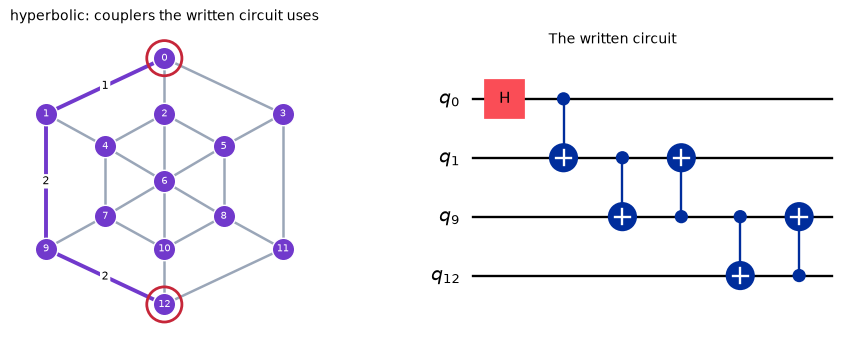


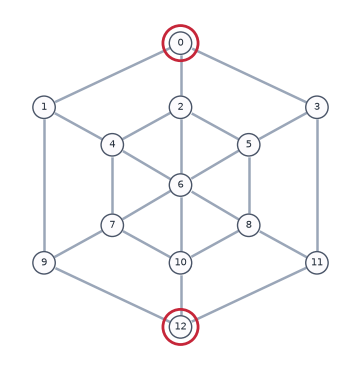
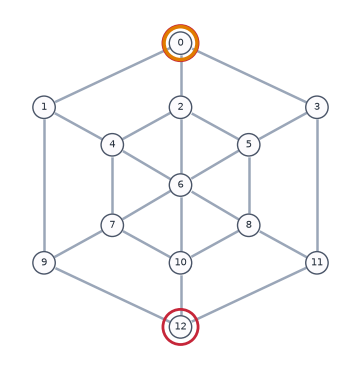
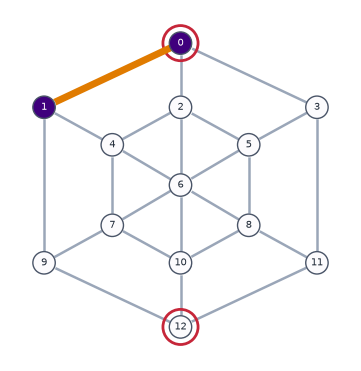
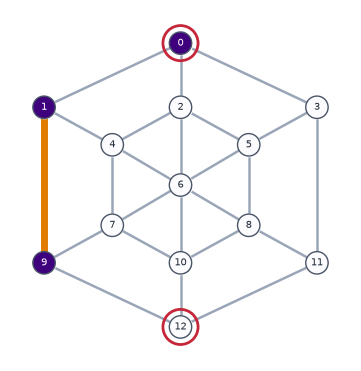
...
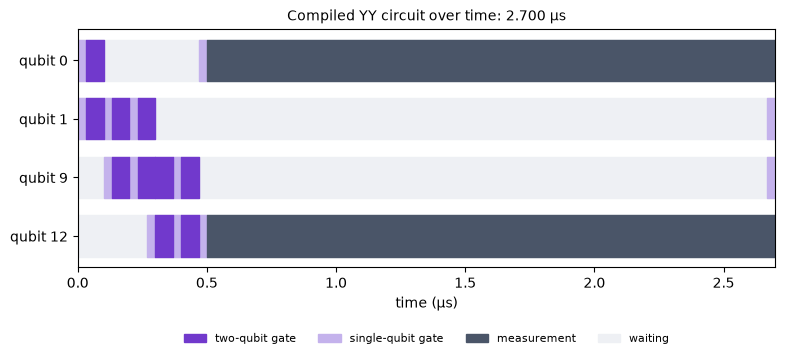
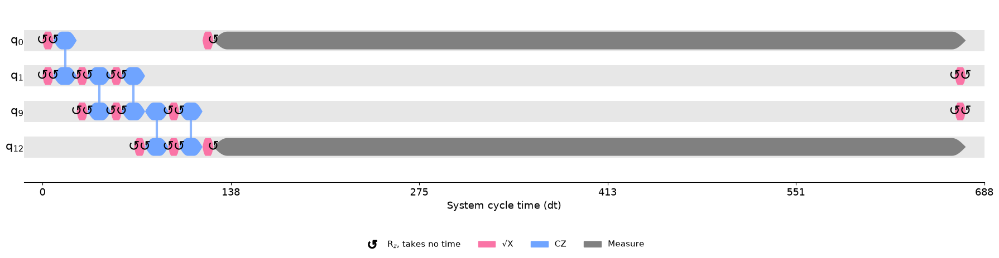
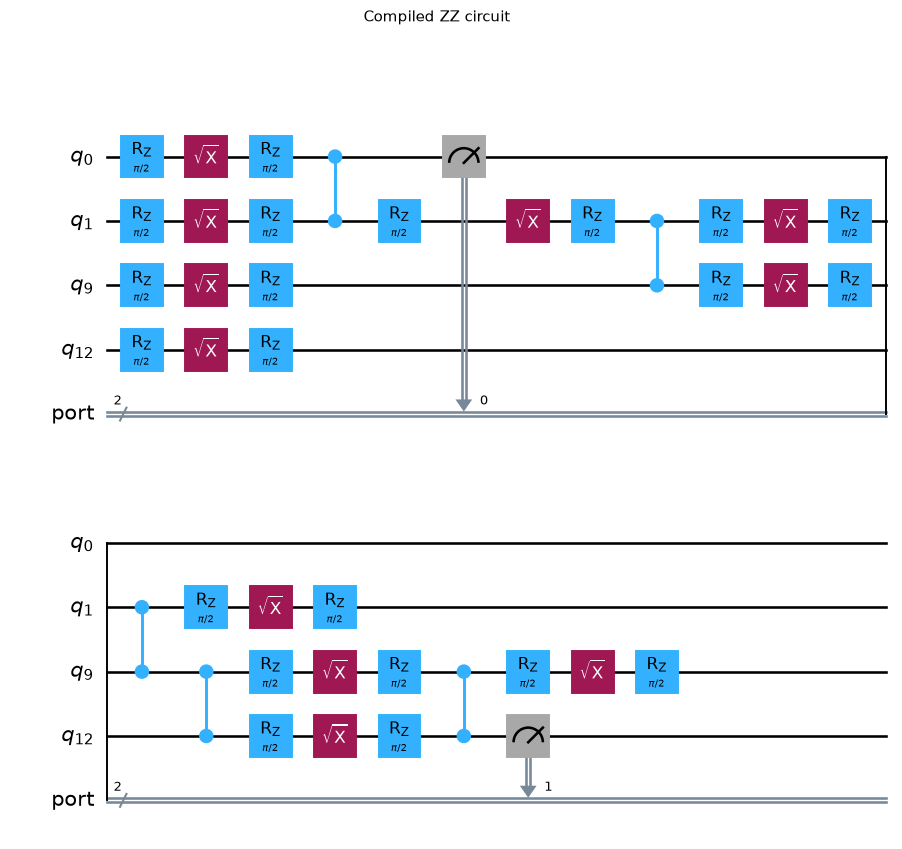
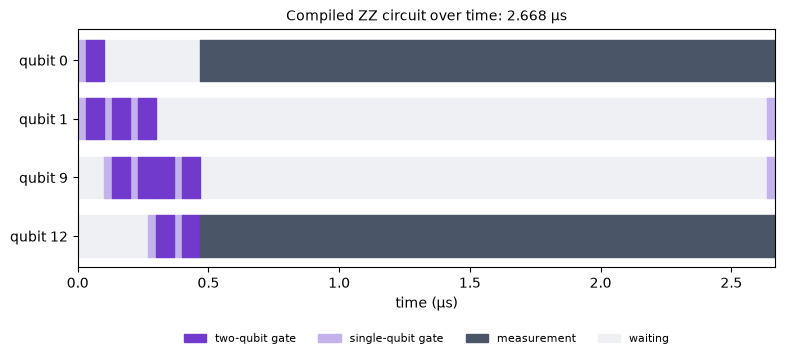
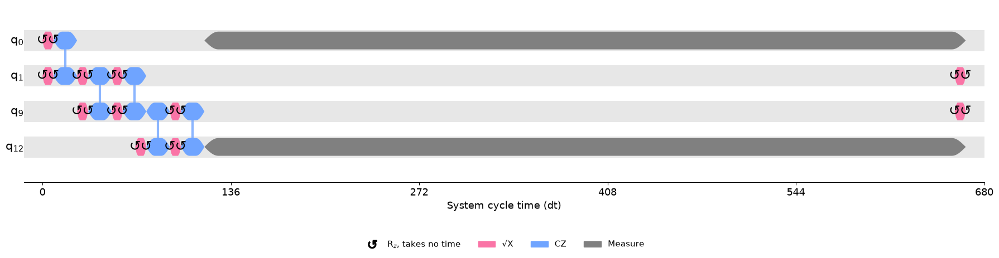

In [44]:
circuit_views("move-chain-hyperbolic", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.ghz-measure-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-measure-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-measure-hyperbolic.yaml

name: ghz-measure-hyperbolic
label: ghz_measure, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks: []
    frame_z:
    - frame_z_ghz[0]
    - frame_z_ghz[1]
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: ghz_measure(reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] frame_z_ghz;
  qubit[13] q;
  h q[1];
  cx q[1], q[9];
  cx q[9], q[12];
  cx q[1], q[0];
  h q[1];
  frame_z_ghz[0] = measure q[1];
  h q[9];
  frame_z_ghz[1] = measure q[9];
```

</details>

**ghz-measure-hyperbolic**: ghz_measure, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `parity`, 0 check groups, frame frame_z · compiled now under boston-2026, base seed 20261116

Cost: 3 two-qubit gates · 0 SWAPs (0 by the router) · depth 11 · 4 qubits (0, 1, 9, 12) · 2.432 µs · pair on the ports ✓

,h,cx,rz,sx,cz,measure
written,3,3,0,0,0,2
compiled ZZ,0,0,18,9,3,4
compiled XX,0,0,14,7,3,4
compiled YY,0,0,18,9,3,4

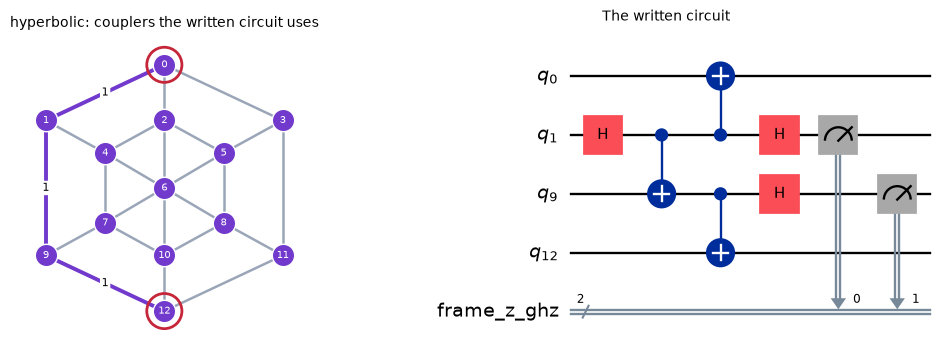


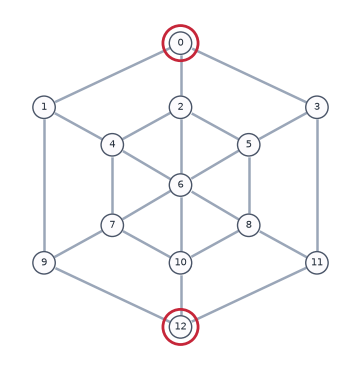
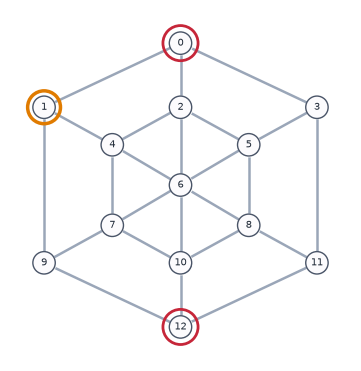
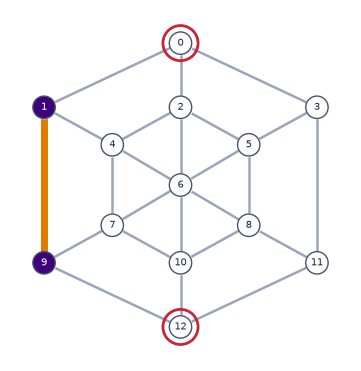
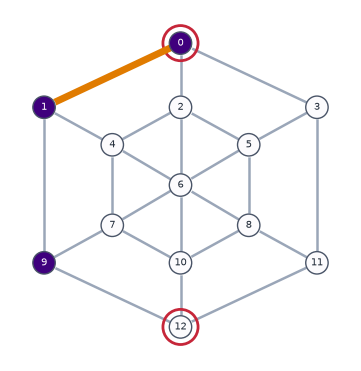
...
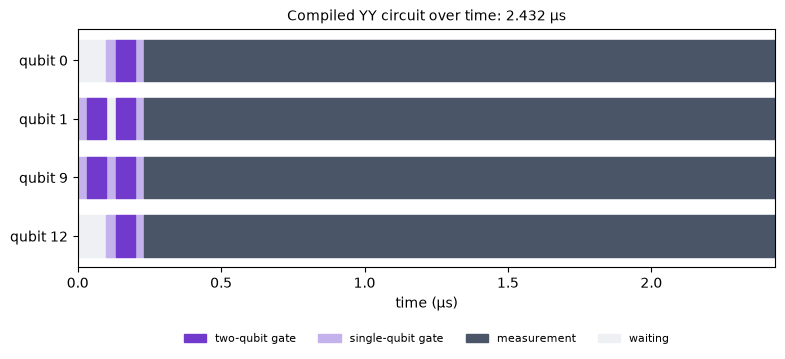
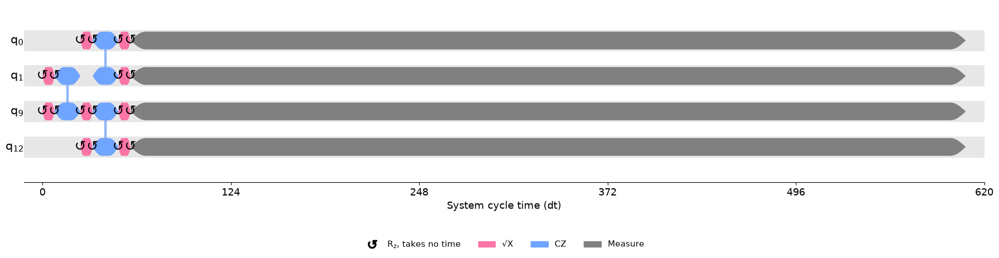
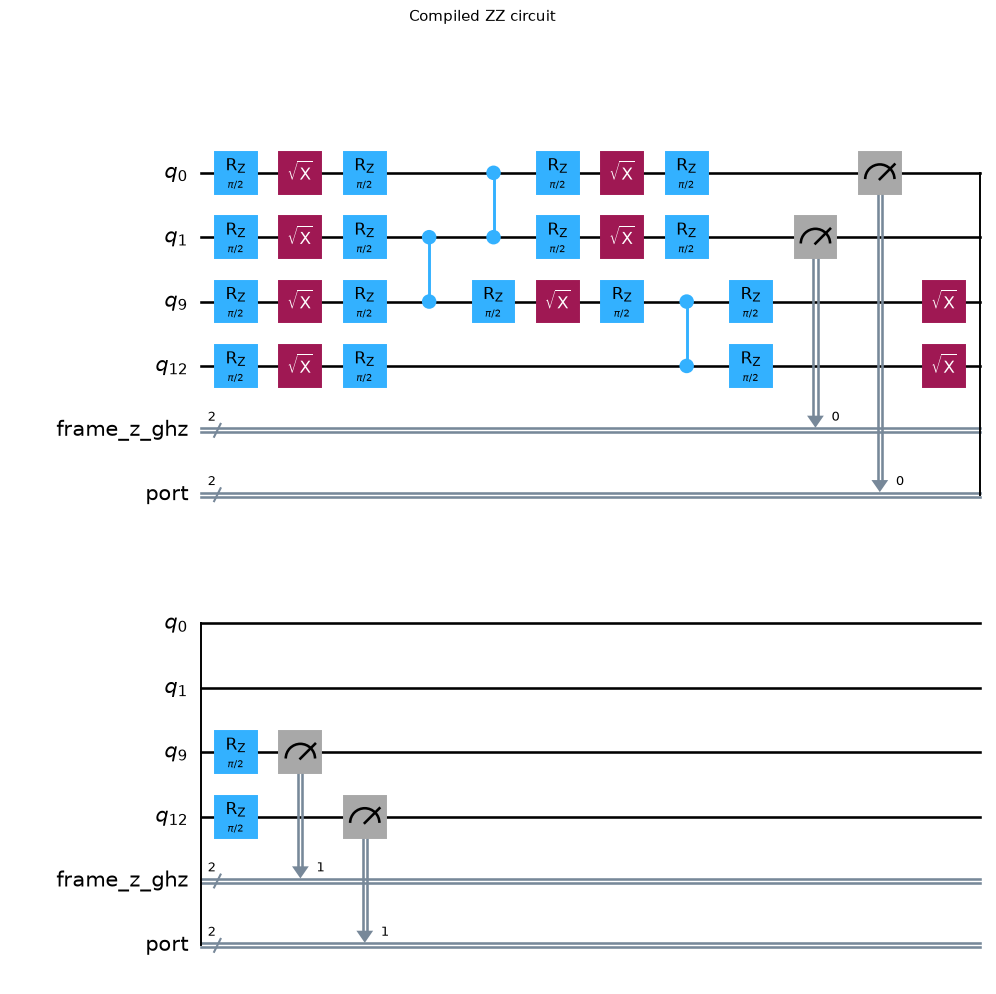
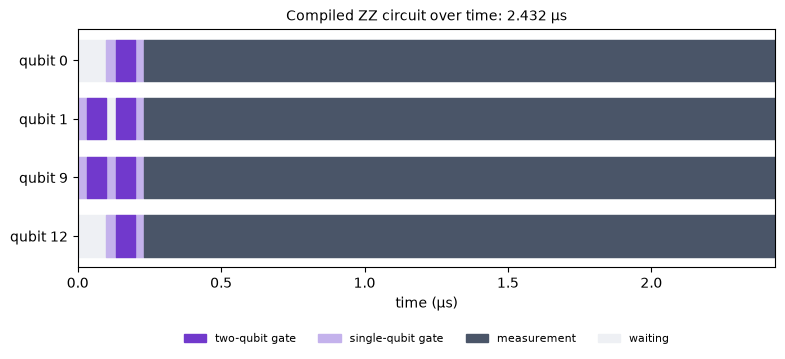
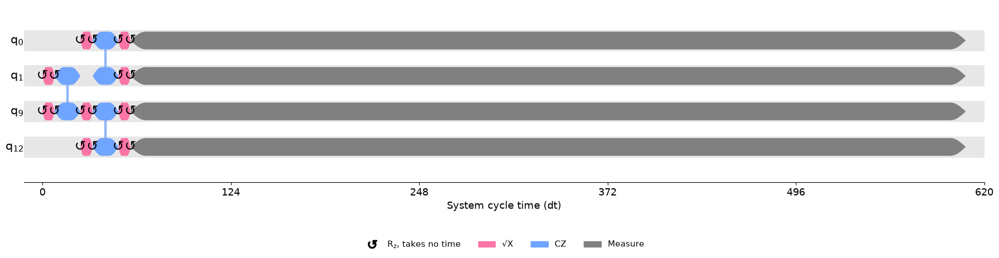

In [45]:
circuit_views("ghz-measure-hyperbolic", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-vacancy-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-vacancy-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-vacancy-hyperbolic.yaml

name: move-chain-vacancy-hyperbolic
label: move_chain then vacancy at the end, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: move_chain();
  then vacancy().
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] check_vac;
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[9];
```

</details>

**move-chain-vacancy-hyperbolic**: move_chain then vacancy at the end, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `parity`, 2 check groups · compiled now under boston-2026, base seed 20261116

Cost: 5 two-qubit gates · 0 SWAPs (0 by the router) · depth 20 · 4 qubits (0, 1, 9, 12) · 2.700 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,5,1,0,0,0,2
compiled ZZ,0,0,22,11,5,4
compiled XX,0,0,26,13,5,4
compiled YY,0,0,24,13,5,4

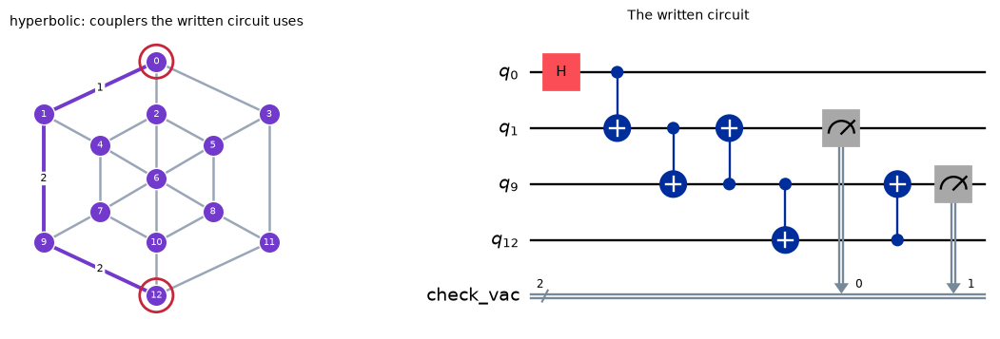


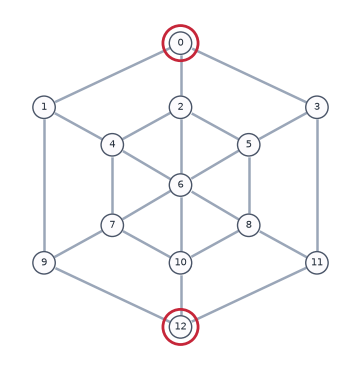
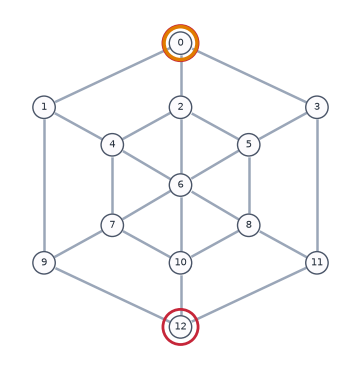
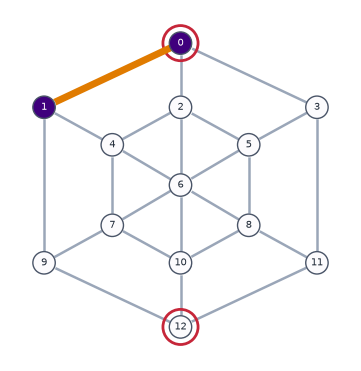
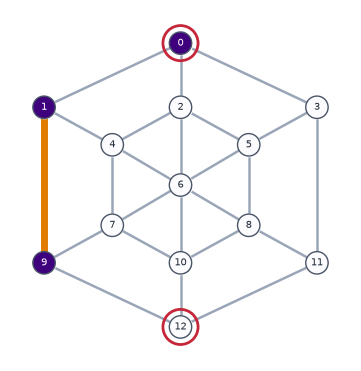
...
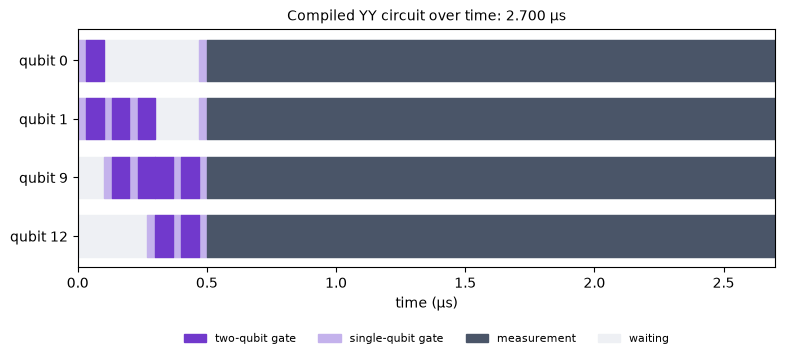
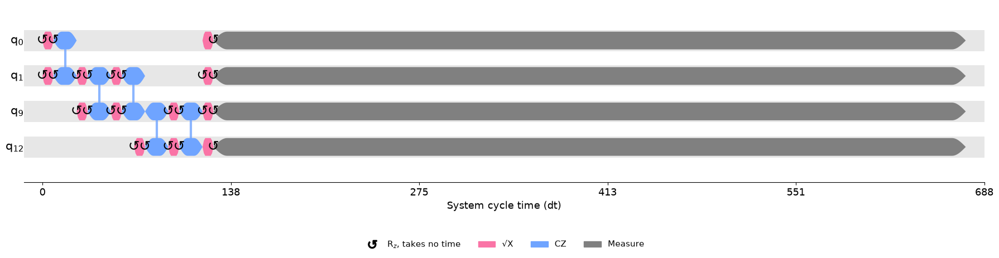
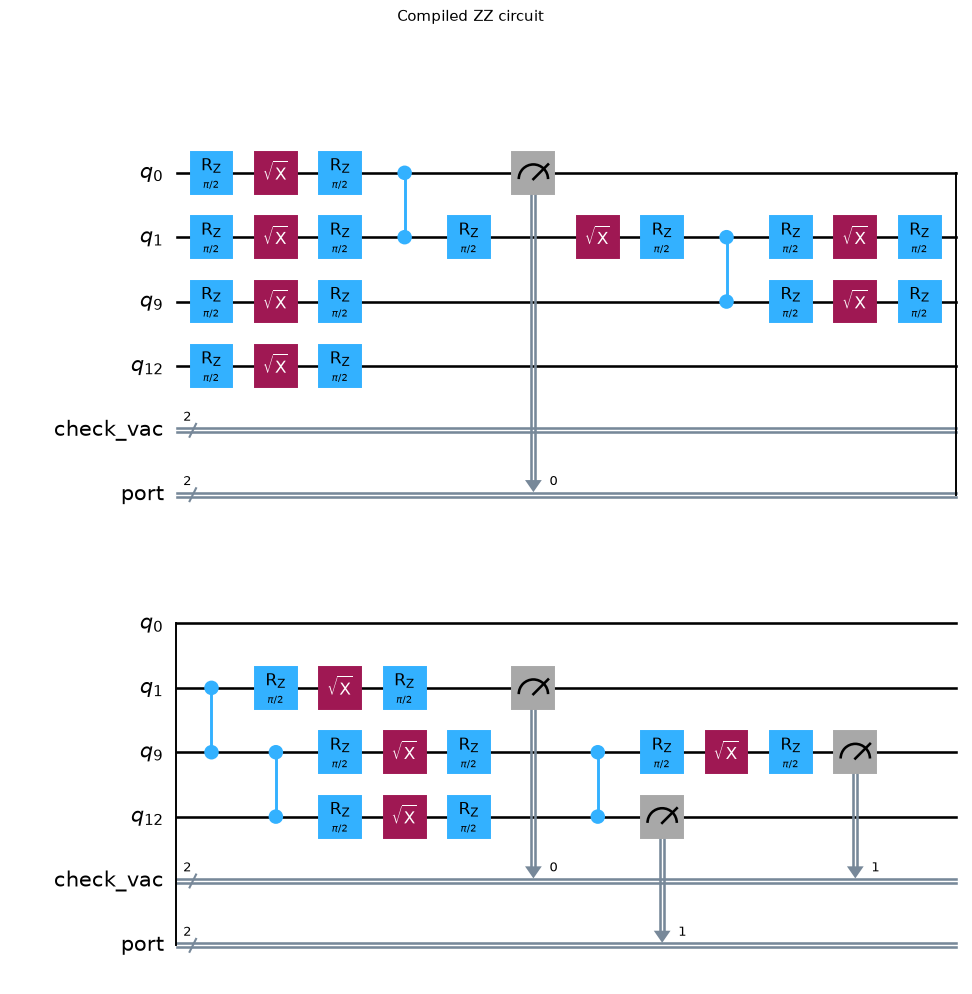
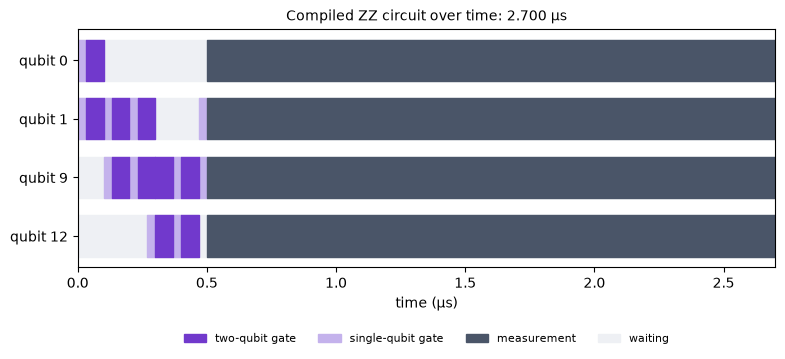
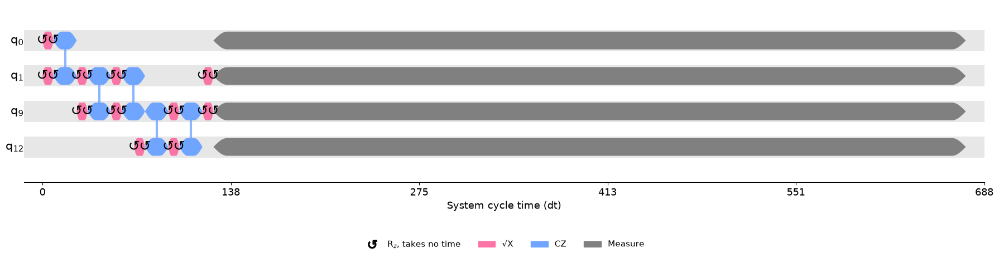

In [46]:
circuit_views("move-chain-vacancy-hyperbolic", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.move-chain-spare-xx-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-chain-spare-xx-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-chain-spare-xx-hyperbolic.yaml

name: move-chain-spare-xx-hyperbolic
label: move_chain then bus_xx on a spare path, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_xx[0]
      - check_xx[1]
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: move_chain();
  then bus_xx(on=[0, 3, 11, 12], reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] check_xx;
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
  h q[3];
  cx q[3], q[11];
  cx q[3], q[0];
  cx q[11], q[12];
  h q[3];
  check_xx[0] = measure q[3];
  h q[11];
  check_xx[1] = measure q[11];
```

</details>

**move-chain-spare-xx-hyperbolic**: move_chain then bus_xx on a spare path, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `parity`, 1 check group · compiled now under boston-2026, base seed 20261116

Cost: 8 two-qubit gates · 0 SWAPs (0 by the router) · depth 24 · 6 qubits (0, 1, 3, 9, 11, 12) · 2.800 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,8,4,0,0,0,2
compiled ZZ,0,0,40,20,8,4
compiled XX,0,0,36,18,8,4
compiled YY,0,0,40,20,8,4

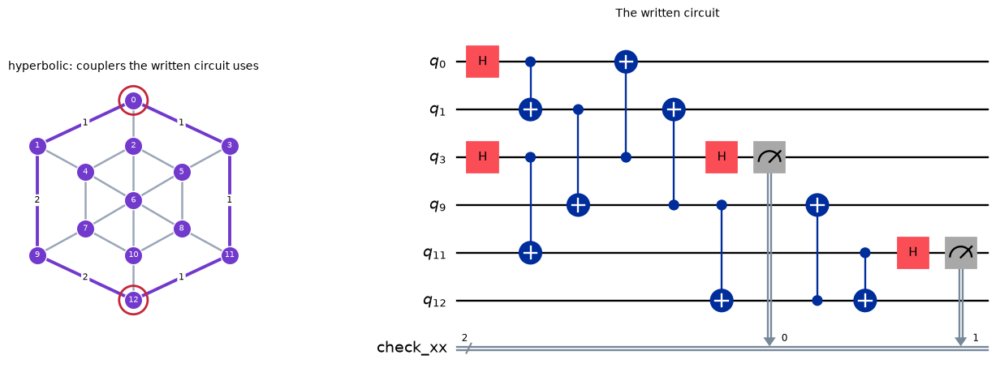


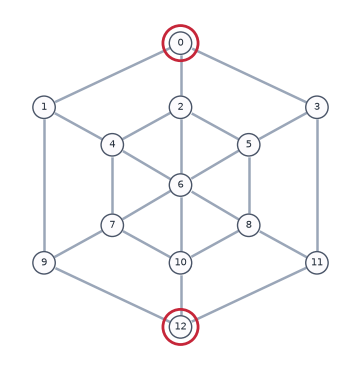
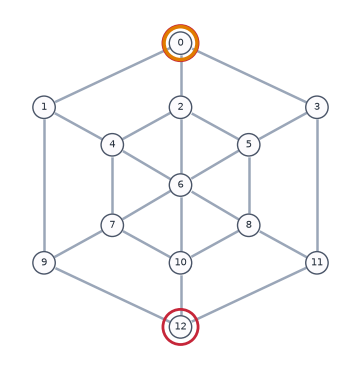
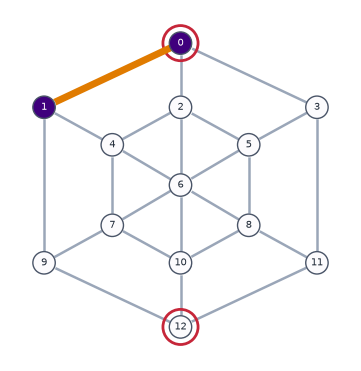
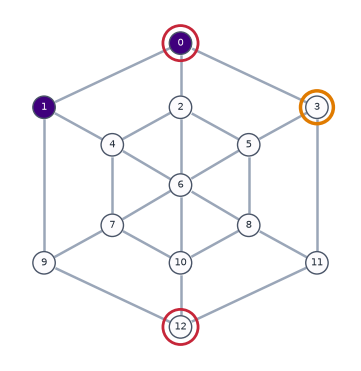
...
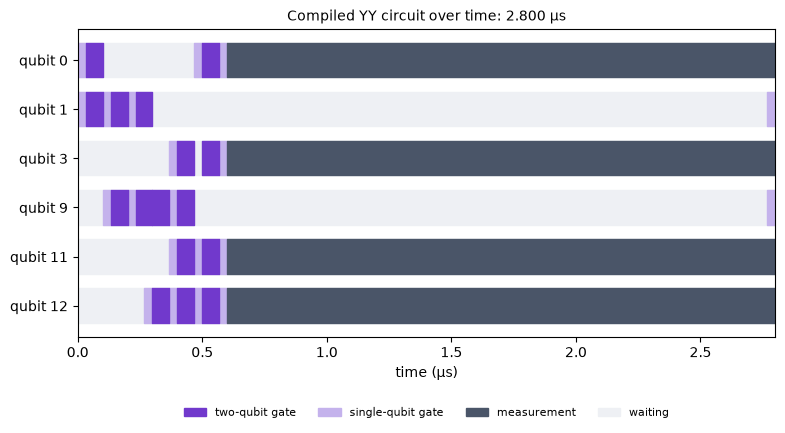
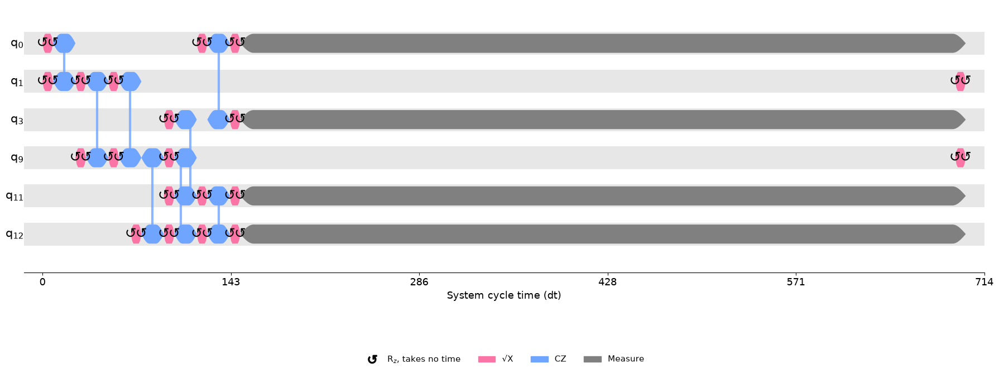
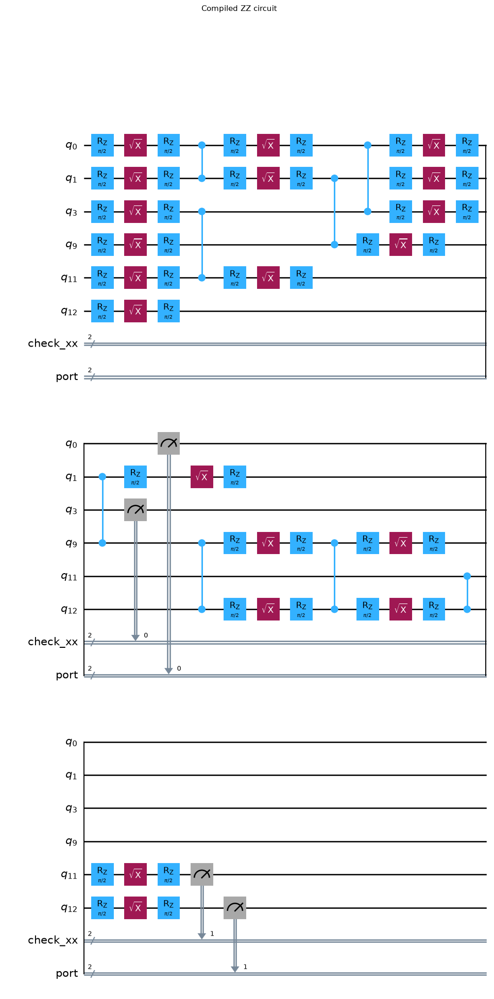
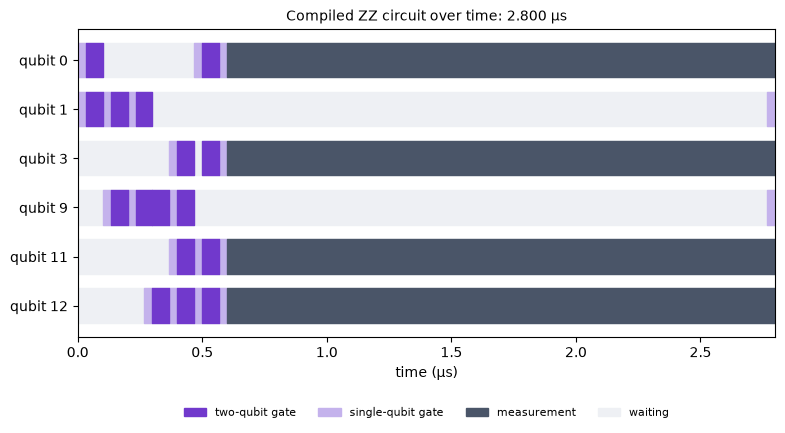
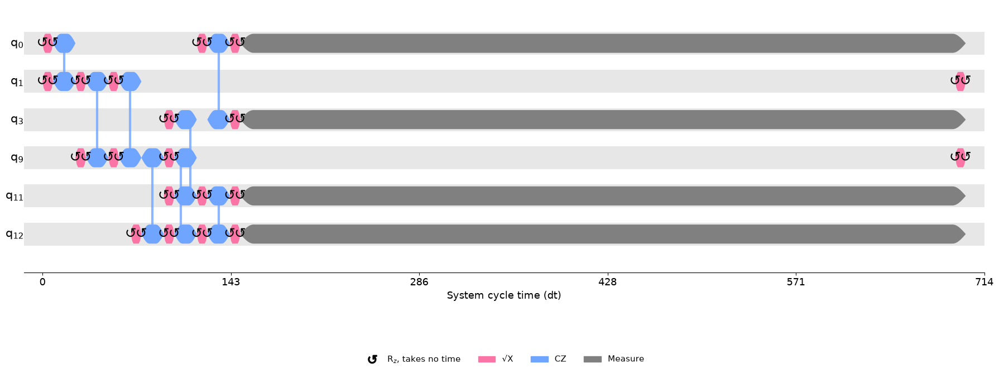

In [47]:
circuit_views("move-chain-spare-xx-hyperbolic", folded=True)

<details><summary><b>config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.ghz-uncompute-vacancy-spare-xx-hyperbolic.yaml

name: ghz-uncompute-vacancy-spare-xx-hyperbolic
label: ghz_uncompute then vacancy, then bus_xx on a spare path, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_vac[0]
    - - check_vac[1]
    - - check_xx[0]
      - check_xx[1]
notes: >-
  Built by src/bellbench/builders.py on hyperbolic along the path [0, 1, 9, 12]: ghz_uncompute();
  then vacancy(); then bus_xx(on=[0, 3, 11, 12], reset=False).
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] check_vac;
  bit[2] check_xx;
  qubit[13] q;
  h q[0];
  cx q[0], q[1];
  cx q[1], q[9];
  cx q[9], q[12];
  cx q[1], q[9];
  cx q[0], q[1];
  check_vac[0] = measure q[1];
  check_vac[1] = measure q[9];
  h q[3];
  cx q[3], q[11];
  cx q[3], q[0];
  cx q[11], q[12];
  h q[3];
  check_xx[0] = measure q[3];
  h q[11];
  check_xx[1] = measure q[11];
```

</details>

**ghz-uncompute-vacancy-spare-xx-hyperbolic**: ghz_uncompute then vacancy, then bus_xx on a spare path, hyperbolic  
hyperbolic, ports 0 and 12, 3 hops · read by `parity`, 3 check groups · compiled now under boston-2026, base seed 20261116

Cost: 8 two-qubit gates · 0 SWAPs (0 by the router) · depth 27 · 6 qubits (0, 1, 3, 9, 11, 12) · 2.832 µs · pair on the ports ✓

,cx,h,rz,sx,cz,measure
written,8,4,0,0,0,4
compiled ZZ,0,0,36,18,8,6
compiled XX,0,0,32,16,8,6
compiled YY,0,0,36,18,8,6

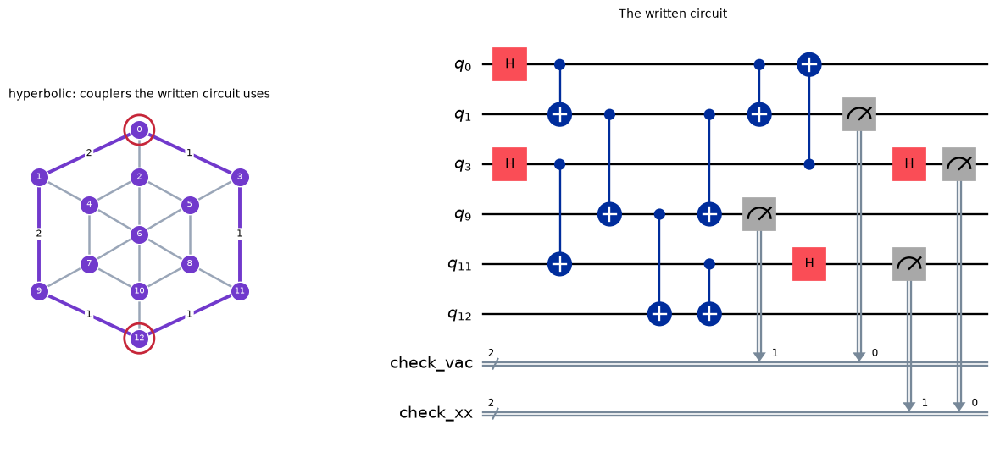


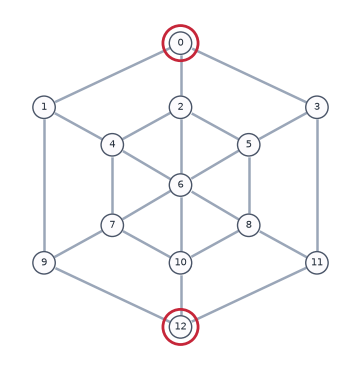
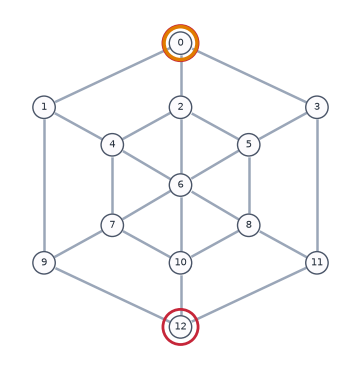
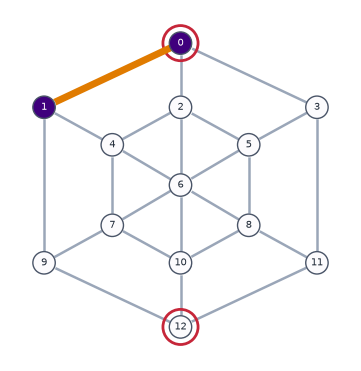
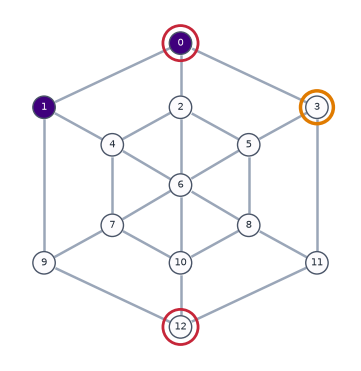
...
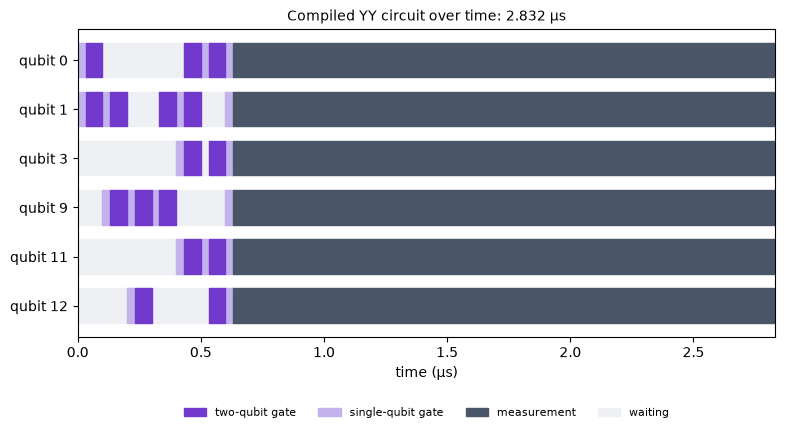
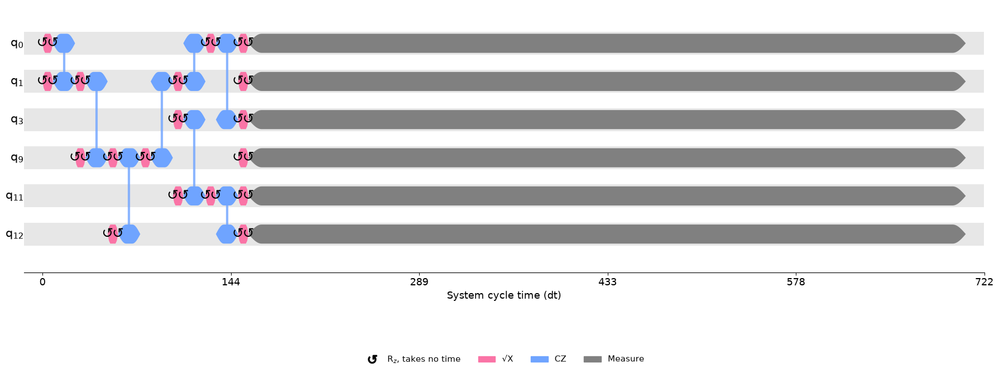
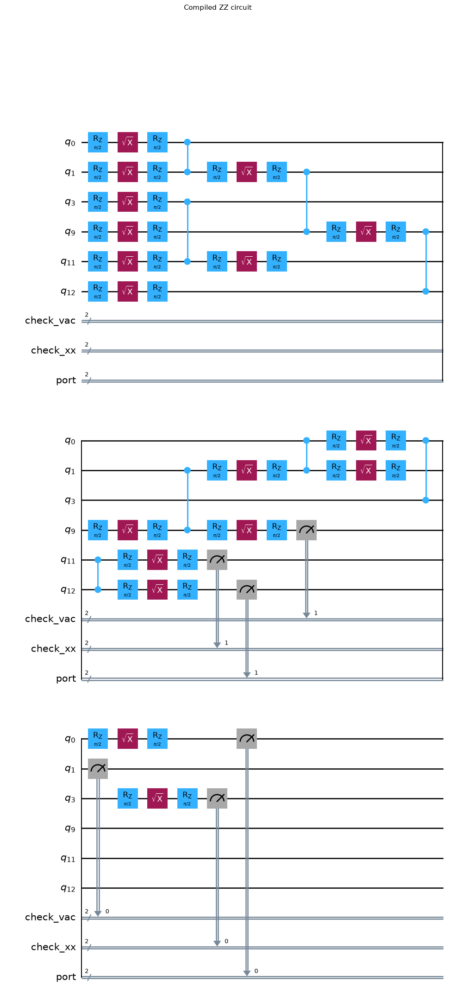
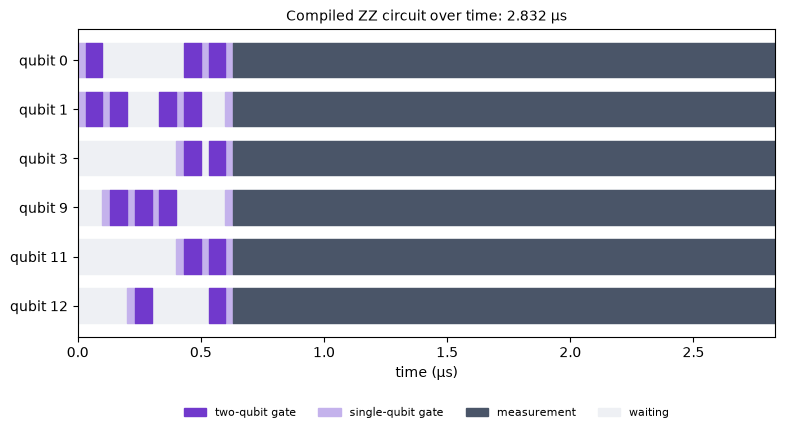
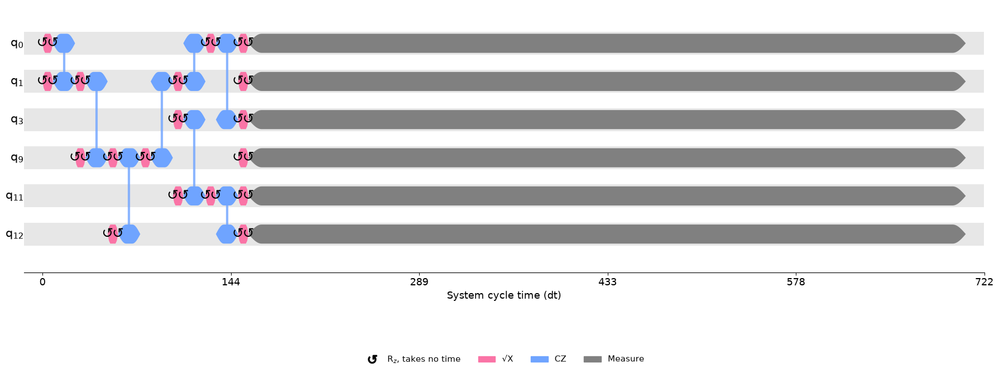

In [48]:
circuit_views("ghz-uncompute-vacancy-spare-xx-hyperbolic", folded=True)

With every file the deliverable-2026-11-17-extended-hyperbolic benchmark uses shown, the notebook makes it, draws each run's F, and sets each run beside the run the repository recorded.

made 9 runs of deliverable-2026-11-17-extended-hyperbolic: baseline-hyperbolic, move-chain-hyperbolic, ghz-measure-hyperbolic, ghz-measure-hyperbolic-readout-0, ghz-uncompute-hyperbolic, move-chain-vacancy-hyperbolic, ghz-uncompute-vacancy-hyperbolic, move-chain-spare-xx-hyperbolic, ghz-uncompute-vacancy-spare-xx-hyperbolic


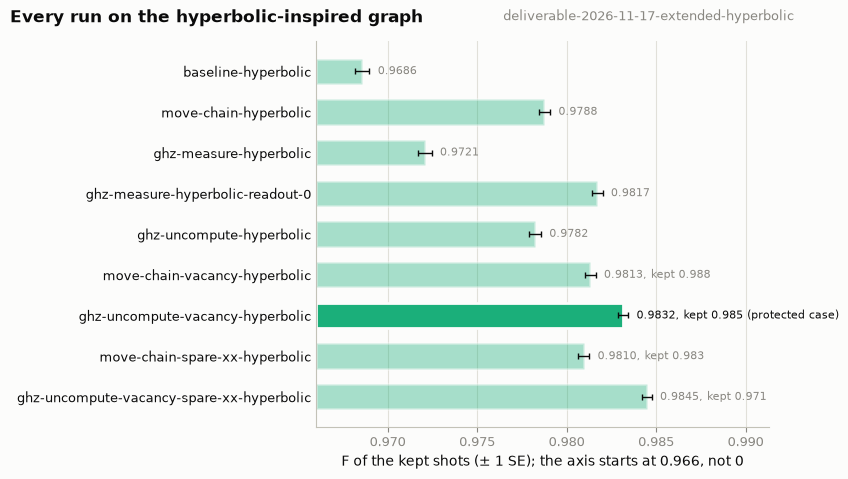

---

**Each run of deliverable-2026-11-17-extended-hyperbolic beside the run the repository recorded**

,F here,F recorded,acceptance here,acceptance recorded,identical,same files
run,,,,,,
baseline-hyperbolic,0.9686,0.9686,1.000,1.000,True,True
move-chain-hyperbolic,0.9788,0.9788,1.000,1.000,True,True
ghz-measure-hyperbolic,0.9721,0.9721,1.000,1.000,True,True
ghz-measure-hyperbolic-readout-0,0.9817,0.9817,1.000,1.000,True,True
ghz-uncompute-hyperbolic,0.9782,0.9782,1.000,1.000,True,True
move-chain-vacancy-hyperbolic,0.9813,0.9813,0.988,0.988,True,True
ghz-uncompute-vacancy-hyperbolic,0.9832,0.9832,0.985,0.985,True,True
move-chain-spare-xx-hyperbolic,0.9810,0.9810,0.983,0.983,True,True
ghz-uncompute-vacancy-spare-xx-hyperbolic,0.9845,0.9845,0.971,0.971,True,True


every run identical to its record, counts, circuits and numbers
provenance that differs, not counted: commit


In [49]:
make("deliverable-2026-11-17-extended-hyperbolic")
ladder("deliverable-2026-11-17-extended-hyperbolic")
beside_record("deliverable-2026-11-17-extended-hyperbolic")

### 6.4 Readout and the two GHZ transports

**Under Boston's readout errors the textbook GHZ transport, which reads the interior in X, loses to GHZ disentangling on every graph; with no readout error on the qubits it reads, it wins on every graph.** Each misread interior qubit flips the Z owed on the first port, which leaves the pair in the wrong Bell state, so the loss grows with the qubits it reads: one on the 2016-inspired graph, two on the hyperbolic-inspired and three on the contemporary. Neither run has a check; both keep every shot.

Each value is ghz-measure's F minus ghz-uncompute's:

| Graph | Qubits read | As modelled | No readout error on the qubits read |
|---|---|---|---|
| 2016-inspired | 1 | -0.0028 (-6.4 SE) | +0.0010 (2.4 SE) |
| Contemporary | 3 | -0.0082 (-15.2 SE) | +0.0058 (12.3 SE) |
| Hyperbolic-inspired | 2 | -0.0062 (-12.4 SE) | +0.0035 (7.8 SE) |

---

## Appendix A. Optional: the other noise profiles and benchmarks

**Optional: every config file nothing above shows, the other noise profiles and the earlier benchmarks with their circuits.** Nothing above depends on them; they complete the repository's config, so every assumption the benchmark holds is in this notebook. Nothing here is compiled or run.

<details><summary><b>config/benchmark/bp.data.benchmark.biased-noise.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.biased-noise.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.biased-noise.yaml

name: biased-noise
label: Biased-noise study
notes: >-
  An optional study, kept apart from the core benchmark (docs/CHALLENGE.md, What is
  fixed and what we choose): if a processor's errors were mostly phase flips and its
  CX kept them so, would an XX check catch nearly every error on the pair? Each graph
  runs the organisers' baseline, move_chain alone, and move_chain with bus_xx, under
  three pauli profiles that differ only in the native two-qubit gate and the noise
  bias: pauli-cx-biased (CX, eta 100), pauli-cz-biased (CZ, eta 100) and
  pauli-cx-unbiased (CX, eta 0.5). On the contemporary and hyperbolic graphs bus_xx
  runs on a spare path and reads only at the end; ibm2016 has no spare path, so there
  it runs on the path, reads each qubit before reusing it, and needs the mid-circuit
  measurement channel, set to 0.01 as one point of the range it is to be swept over.
  The profiles have no readout error, decay or durations, so these numbers describe
  gate noise alone, on one finite model each. 20,000 shots per basis, as in the core.
shots: 20000
base_seed: 20261116
runs:
  # Under pauli-cx-biased.
  - {run: baseline-ibm2016-cx-biased, circuit: baseline-ibm2016, noise: pauli-cx-biased}
  - {run: baseline-contemporary-cx-biased, circuit: baseline-contemporary, noise: pauli-cx-biased}
  - {run: baseline-hyperbolic-cx-biased, circuit: baseline-hyperbolic, noise: pauli-cx-biased}
  - {run: move-ibm2016-cx-biased, circuit: move-chain-ibm2016, noise: pauli-cx-biased}
  - {run: move-contemporary-cx-biased, circuit: move-chain-contemporary, noise: pauli-cx-biased}
  - {run: move-hyperbolic-cx-biased, circuit: move-chain-hyperbolic, noise: pauli-cx-biased}
  - {run: path-xx-ibm2016-cx-biased, circuit: move-chain-path-xx-ibm2016, noise: pauli-cx-biased, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: spare-xx-contemporary-cx-biased, circuit: move-chain-spare-xx-contemporary, noise: pauli-cx-biased}
  - {run: spare-xx-hyperbolic-cx-biased, circuit: move-chain-spare-xx-hyperbolic, noise: pauli-cx-biased}
  # Under pauli-cz-biased.
  - {run: baseline-ibm2016-cz-biased, circuit: baseline-ibm2016, noise: pauli-cz-biased}
  - {run: baseline-contemporary-cz-biased, circuit: baseline-contemporary, noise: pauli-cz-biased}
  - {run: baseline-hyperbolic-cz-biased, circuit: baseline-hyperbolic, noise: pauli-cz-biased}
  - {run: move-ibm2016-cz-biased, circuit: move-chain-ibm2016, noise: pauli-cz-biased}
  - {run: move-contemporary-cz-biased, circuit: move-chain-contemporary, noise: pauli-cz-biased}
  - {run: move-hyperbolic-cz-biased, circuit: move-chain-hyperbolic, noise: pauli-cz-biased}
  - {run: path-xx-ibm2016-cz-biased, circuit: move-chain-path-xx-ibm2016, noise: pauli-cz-biased, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: spare-xx-contemporary-cz-biased, circuit: move-chain-spare-xx-contemporary, noise: pauli-cz-biased}
  - {run: spare-xx-hyperbolic-cz-biased, circuit: move-chain-spare-xx-hyperbolic, noise: pauli-cz-biased}
  # Under pauli-cx-unbiased.
  - {run: baseline-ibm2016-cx-unbiased, circuit: baseline-ibm2016, noise: pauli-cx-unbiased}
  - {run: baseline-contemporary-cx-unbiased, circuit: baseline-contemporary, noise: pauli-cx-unbiased}
  - {run: baseline-hyperbolic-cx-unbiased, circuit: baseline-hyperbolic, noise: pauli-cx-unbiased}
  - {run: move-ibm2016-cx-unbiased, circuit: move-chain-ibm2016, noise: pauli-cx-unbiased}
  - {run: move-contemporary-cx-unbiased, circuit: move-chain-contemporary, noise: pauli-cx-unbiased}
  - {run: move-hyperbolic-cx-unbiased, circuit: move-chain-hyperbolic, noise: pauli-cx-unbiased}
  - {run: path-xx-ibm2016-cx-unbiased, circuit: move-chain-path-xx-ibm2016, noise: pauli-cx-unbiased, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: spare-xx-contemporary-cx-unbiased, circuit: move-chain-spare-xx-contemporary, noise: pauli-cx-unbiased}
  - {run: spare-xx-hyperbolic-cx-unbiased, circuit: move-chain-spare-xx-hyperbolic, noise: pauli-cx-unbiased}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.mid-circuit-sweep.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.mid-circuit-sweep.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.mid-circuit-sweep.yaml

name: mid-circuit-sweep
label: Mid-circuit measurement error sweep on ibm2016
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): how the XX check on ibm2016 fares as its mid-circuit measurement
  error grows. ibm2016 has no spare path, so its check sits on the pair's own path,
  reads each bus qubit mid-circuit and reuses it, and the move-chain benchmark's case 3
  sets the mid-circuit measurement error to 0.01, one assumed value. Here that circuit,
  move_chain with bus_xx on the pair's path, runs under boston-2026 at mid-circuit
  measurement errors 0, 0.001, 0.003, 0.01, 0.02 and 0.05, each run named by its value
  in e notation after mcm. Each value is one point of a sweep, not a claimed property
  of any device, and each run derives its own seeds, so neighbouring points also differ
  by shot noise: read each difference against its standard errors. The run at 0.01 has
  case 3's settings and seeds, so it gives case 3's numbers. The organisers' baseline
  and move_chain alone read nothing
  mid-circuit, so the error cannot reach them: each runs once, without the channel, as
  a fixed reference. Setting the check's F after postselection, with its acceptance,
  beside move_chain alone's F at each point shows at which errors, if any, the check
  pays for the shots it discards. 20,000 shots per basis and base seed 20261116, as in
  the core.
shots: 20000
base_seed: 20261116
runs:
  # The fixed references, as the move-chain benchmark runs them.
  - {run: baseline-ibm2016, circuit: baseline-ibm2016, noise: boston-2026}
  - {run: move-ibm2016, circuit: move-chain-ibm2016, noise: boston-2026}
  # The move chain with its XX check on the pair's path, one run per mid-circuit measurement error.
  - {run: path-xx-ibm2016-mcm-0, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.0}}
  - {run: path-xx-ibm2016-mcm-1e-3, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.001}}
  - {run: path-xx-ibm2016-mcm-3e-3, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.003}}
  - {run: path-xx-ibm2016-mcm-1e-2, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: path-xx-ibm2016-mcm-2e-2, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.02}}
  - {run: path-xx-ibm2016-mcm-5e-2, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.05}}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.middle-out.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.middle-out.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.middle-out.yaml

name: middle-out
label: Middle-out study
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): do two variants of the strategy the submission reported then,
  the move chain with an XX check, do better than it? The first, move_middle_out, makes the pair in the middle of the path and moves both
  halves outward at once, so it uses the same gates as move_chain in a shorter
  schedule. The second adds a ZZ check before the XX check on the hyperbolic graph,
  whose third qubit-disjoint path between the ports holds a second spare bus; the ZZ
  check catches a bit flip on one port, which the XX check misses, and runs first so
  that the XX check's parity covers the ZZ check's frame bit. The contemporary graph
  has only two qubit-disjoint paths, so it has no room for a second spare bus, and on
  ibm2016 move_middle_out writes the same circuit as move_chain, so neither graph runs
  that variant. Each new run sits beside the move-chain benchmark's run it varies,
  rerun here under the same circuit, profile and base seed, so with the same seeds and
  the same numbers. The ZZ and XX run's XX bus passes through the centre qubit, so its
  numbers are without the planned degree penalty (docs/DESIGN.md, section 4). Every
  run takes 20,000 shots per basis, as in the core.
shots: 20000
base_seed: 20261116
runs:
  # The reference: the move-chain benchmark's runs these vary.
  - {run: move-contemporary, circuit: move-chain-contemporary, noise: boston-2026}
  - {run: move-hyperbolic, circuit: move-chain-hyperbolic, noise: boston-2026}
  - {run: spare-xx-contemporary, circuit: move-chain-spare-xx-contemporary, noise: boston-2026}
  - {run: spare-xx-hyperbolic, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026}
  # Middle-out, without and with the XX check.
  - {run: middle-out-contemporary, circuit: move-middle-out-contemporary, noise: boston-2026}
  - {run: middle-out-hyperbolic, circuit: move-middle-out-hyperbolic, noise: boston-2026}
  - {run: middle-out-xx-contemporary, circuit: move-middle-out-spare-xx-contemporary, noise: boston-2026}
  - {run: middle-out-xx-hyperbolic, circuit: move-middle-out-spare-xx-hyperbolic, noise: boston-2026}
  # Middle-out with a ZZ check, then the XX check, on the hyperbolic graph's two spare paths.
  - {run: middle-out-zz-xx-hyperbolic, circuit: move-middle-out-spare-zz-xx-hyperbolic, noise: boston-2026}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.move-chain.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.move-chain.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.move-chain.yaml

name: move-chain
label: Move chain with an XX check, the nine cases
notes: >-
  The challenge's nine cases (docs/CHALLENGE.md, The nine core cases) with one
  protection strategy filled in, under boston-2026 as in the core benchmark, so the
  three graphs differ only in connectivity. Cases 1, 2, 4, 5, 7 and 8 are the
  organisers' baseline, the reference, exactly as the core benchmark runs it. Cases
  3, 6 and 9 are the protection: move_chain carries the pair to the ports with two CX
  gates a hop instead of a SWAP's three, then bus_xx reads the ports' XX parity
  through a bus of extra qubits and postselection discards each shot where it reads
  -1. The check catches a phase flip on one port and is blind to a bit flip, to the
  same flip on both ports and to an error on the bus. On the contemporary and
  hyperbolic graphs the bus sits on a spare path that shares no qubit with the pair
  and reads only at the end; ibm2016 has no spare path, so there the bus sits on the
  pair's own path, reads each qubit as vacant before reusing it, and needs the
  mid-circuit measurement channel, set to 0.01 as one point of the range it is to be
  swept over. The move chain also runs without the check, filling no case, so the
  table separates what the cheaper transport buys from what the check buys. Every
  run takes 20,000 shots per basis, as in the core; protected runs are not yet given
  more shots in proportion to their acceptance.
shots: 20000
base_seed: 20261116
runs:
  # The reference: the organisers' baseline.
  - {run: baseline-ibm2016, circuit: baseline-ibm2016, noise: boston-2026}
  - {run: baseline-contemporary, circuit: baseline-contemporary, noise: boston-2026}
  - {run: baseline-hyperbolic, circuit: baseline-hyperbolic, noise: boston-2026}
  # The move chain alone, filling no case.
  - {run: move-ibm2016, circuit: move-chain-ibm2016, noise: boston-2026}
  - {run: move-contemporary, circuit: move-chain-contemporary, noise: boston-2026}
  - {run: move-hyperbolic, circuit: move-chain-hyperbolic, noise: boston-2026}
  # The protection: the move chain with its XX check.
  - {run: path-xx-ibm2016, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: spare-xx-contemporary, circuit: move-chain-spare-xx-contemporary, noise: boston-2026}
  - {run: spare-xx-hyperbolic, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026}
cases:
  - {case: 1, run: baseline-ibm2016, simulation: ideal}
  - {case: 2, run: baseline-ibm2016, simulation: noisy}
  - {case: 3, run: path-xx-ibm2016, simulation: noisy}
  - {case: 4, run: baseline-contemporary, simulation: ideal}
  - {case: 5, run: baseline-contemporary, simulation: noisy}
  - {case: 6, run: spare-xx-contemporary, simulation: noisy}
  - {case: 7, run: baseline-hyperbolic, simulation: ideal}
  - {case: 8, run: baseline-hyperbolic, simulation: noisy}
  - {case: 9, run: spare-xx-hyperbolic, simulation: noisy}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.starting-excitation.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.starting-excitation.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.starting-excitation.yaml

name: starting-excitation
label: Starting excitation sweep on the move-chain benchmark's runs
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): how the move-chain benchmark's runs fare if each qubit may start
  a shot in |1> rather than |0>. The move chain's two-CX move is a SWAP without its
  third CX, so it assumes the qubit it moves onto starts in |0>, and the XX check on a
  spare path trusts its spare qubits to start in |0>; the organisers' baseline swaps
  the pair out and back, which returns an excited qubit on its path to where it
  started. Each of the move-chain benchmark's nine runs, the baseline, the move chain
  alone and the move chain with its XX check on each graph, runs under boston-2026 with
  the starting excitation, the chance that each qubit starts a shot in |1>, at 0,
  0.005, 0.01 and 0.02, each run named by its value in e notation after exc; the check
  on ibm2016 keeps case 3's mid-circuit measurement error of 0.01. A run at 0 differs
  from the move-chain benchmark's run of the same circuit only in its seeds. Each value is one
  point of a sweep, not a claimed property of any device, and each run derives its own
  seeds, so neighbouring points also differ by shot noise: read each difference
  against its standard errors. 20,000 shots per basis and base seed 20261116, as in
  the core.
shots: 20000
base_seed: 20261116
runs:
  # The organisers' baseline.
  - {run: baseline-ibm2016-exc-0, circuit: baseline-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: baseline-ibm2016-exc-5e-3, circuit: baseline-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: baseline-ibm2016-exc-1e-2, circuit: baseline-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: baseline-ibm2016-exc-2e-2, circuit: baseline-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  - {run: baseline-contemporary-exc-0, circuit: baseline-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: baseline-contemporary-exc-5e-3, circuit: baseline-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: baseline-contemporary-exc-1e-2, circuit: baseline-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: baseline-contemporary-exc-2e-2, circuit: baseline-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  - {run: baseline-hyperbolic-exc-0, circuit: baseline-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: baseline-hyperbolic-exc-5e-3, circuit: baseline-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: baseline-hyperbolic-exc-1e-2, circuit: baseline-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: baseline-hyperbolic-exc-2e-2, circuit: baseline-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  # The move chain alone.
  - {run: move-ibm2016-exc-0, circuit: move-chain-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: move-ibm2016-exc-5e-3, circuit: move-chain-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: move-ibm2016-exc-1e-2, circuit: move-chain-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: move-ibm2016-exc-2e-2, circuit: move-chain-ibm2016, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  - {run: move-contemporary-exc-0, circuit: move-chain-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: move-contemporary-exc-5e-3, circuit: move-chain-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: move-contemporary-exc-1e-2, circuit: move-chain-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: move-contemporary-exc-2e-2, circuit: move-chain-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  - {run: move-hyperbolic-exc-0, circuit: move-chain-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: move-hyperbolic-exc-5e-3, circuit: move-chain-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: move-hyperbolic-exc-1e-2, circuit: move-chain-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: move-hyperbolic-exc-2e-2, circuit: move-chain-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  # The move chain with its XX check, on ibm2016 with case 3's mid-circuit measurement error.
  - {run: path-xx-ibm2016-exc-0, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01, starting_excitation: 0.0}}
  - {run: path-xx-ibm2016-exc-5e-3, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01, starting_excitation: 0.005}}
  - {run: path-xx-ibm2016-exc-1e-2, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01, starting_excitation: 0.01}}
  - {run: path-xx-ibm2016-exc-2e-2, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01, starting_excitation: 0.02}}
  - {run: spare-xx-contemporary-exc-0, circuit: move-chain-spare-xx-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: spare-xx-contemporary-exc-5e-3, circuit: move-chain-spare-xx-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: spare-xx-contemporary-exc-1e-2, circuit: move-chain-spare-xx-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: spare-xx-contemporary-exc-2e-2, circuit: move-chain-spare-xx-contemporary, noise: boston-2026, conditional: {starting_excitation: 0.02}}
  - {run: spare-xx-hyperbolic-exc-0, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.0}}
  - {run: spare-xx-hyperbolic-exc-5e-3, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.005}}
  - {run: spare-xx-hyperbolic-exc-1e-2, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.01}}
  - {run: spare-xx-hyperbolic-exc-2e-2, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026, conditional: {starting_excitation: 0.02}}
```

</details>

<details><summary><b>config/benchmark/bp.data.benchmark.vacancy-read.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/benchmark/bp.data.benchmark.vacancy-read.yaml">On GitHub</a>)</summary>

```yaml
# config/benchmark/bp.data.benchmark.vacancy-read.yaml

name: vacancy-read
label: Vacancy-read study
notes: >-
  An optional study, kept apart from the nine cases (docs/CHALLENGE.md, What is fixed
  and what we choose): does a GHZ-and-uncompute transport, followed by a vacancy read
  of the emptied path at the end, do better than the strategy the submission reported
  then, the move chain with an XX check? ghz_uncompute makes a GHZ state along the path, then empties the interior with
  gates controlled from the first port, so the vacancy read at the end also catches a
  bit flip on that port before the last gate. On ibm2016 the vacancy read replaces case
  3's XX check on the path, which reads a qubit mid-circuit and reuses it; on the
  contemporary and hyperbolic graphs the XX check on a spare path that the submission
  reported then follows it.
  Each new run sits beside the move-chain benchmark's protected run on its graph,
  rerun here under the same circuit, profile and base seed, so with the same seeds and
  the same numbers. Case 3's run appears twice: at the mid-circuit measurement error
  of 0.01 it is reported with, and at 0, the Boston profile alone, under which every
  new run here needs no channel. The contemporary runs' XX bus passes through the
  five-edge qubit, so their numbers are without the planned degree penalty
  (docs/DESIGN.md, section 4). Every run takes 20,000 shots per basis, as in the core.
shots: 20000
base_seed: 20261116
runs:
  # The reference: the move-chain benchmark's protected runs, case 3's also without the mid-circuit error.
  - {run: path-xx-ibm2016, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.01}}
  - {run: path-xx-ibm2016-mcm-0, circuit: move-chain-path-xx-ibm2016, noise: boston-2026, conditional: {mid_circuit_measurement_error: 0.0}}
  - {run: spare-xx-contemporary, circuit: move-chain-spare-xx-contemporary, noise: boston-2026}
  - {run: spare-xx-hyperbolic, circuit: move-chain-spare-xx-hyperbolic, noise: boston-2026}
  # GHZ and uncompute, then a vacancy read at the end; then the XX check on a spare path where one exists.
  - {run: ghz-vacancy-ibm2016, circuit: ghz-uncompute-vacancy-ibm2016, noise: boston-2026}
  - {run: ghz-vacancy-xx-contemporary, circuit: ghz-uncompute-vacancy-spare-xx-contemporary, noise: boston-2026}
  - {run: ghz-vacancy-xx-hyperbolic, circuit: ghz-uncompute-vacancy-spare-xx-hyperbolic, noise: boston-2026}
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-middle-out-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-middle-out-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-middle-out-contemporary.yaml

name: move-middle-out-contemporary
label: move_middle_out, contemporary
processor: contemporary
analysis:
  name: postselect
notes: Built in the Workbench from a Qiskit circuit.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[9] q;
  h q[1];
  cx q[1], q[2];
  cx q[1], q[0];
  cx q[0], q[1];
  cx q[2], q[3];
  cx q[3], q[2];
  cx q[3], q[7];
  cx q[7], q[3];
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-middle-out-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-middle-out-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-middle-out-hyperbolic.yaml

name: move-middle-out-hyperbolic
label: move_middle_out, hyperbolic
processor: hyperbolic
analysis:
  name: postselect
notes: Built in the Workbench from a Qiskit circuit.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  qubit[13] q;
  h q[1];
  cx q[1], q[9];
  cx q[1], q[0];
  cx q[0], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-middle-out-spare-xx-contemporary.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-middle-out-spare-xx-contemporary.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-middle-out-spare-xx-contemporary.yaml

name: move-middle-out-spare-xx-contemporary
label: move_middle_out then bus_xx on a spare path, contemporary
processor: contemporary
analysis:
  name: parity
  settings:
    checks:
    - - check_xx[0]
      - check_xx[1]
      - check_xx[2]
notes: Built in the Workbench from a Qiskit circuit.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[3] check_xx;
  qubit[9] q;
  h q[1];
  cx q[1], q[2];
  cx q[1], q[0];
  cx q[0], q[1];
  cx q[2], q[3];
  cx q[3], q[2];
  cx q[3], q[7];
  cx q[7], q[3];
  h q[4];
  cx q[4], q[5];
  cx q[5], q[6];
  cx q[4], q[0];
  cx q[6], q[7];
  h q[4];
  check_xx[0] = measure q[4];
  h q[5];
  check_xx[1] = measure q[5];
  h q[6];
  check_xx[2] = measure q[6];
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-middle-out-spare-xx-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-middle-out-spare-xx-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-middle-out-spare-xx-hyperbolic.yaml

name: move-middle-out-spare-xx-hyperbolic
label: move_middle_out then bus_xx on a spare path, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_xx[0]
      - check_xx[1]
notes: Built in the Workbench from a Qiskit circuit.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[2] check_xx;
  qubit[13] q;
  h q[1];
  cx q[1], q[9];
  cx q[1], q[0];
  cx q[0], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
  h q[3];
  cx q[3], q[11];
  cx q[3], q[0];
  cx q[11], q[12];
  h q[3];
  check_xx[0] = measure q[3];
  h q[11];
  check_xx[1] = measure q[11];
```

</details>

<details><summary><b>config/circuit/bp.data.circuit.move-middle-out-spare-zz-xx-hyperbolic.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/circuit/bp.data.circuit.move-middle-out-spare-zz-xx-hyperbolic.yaml">On GitHub</a>)</summary>

```yaml
# config/circuit/bp.data.circuit.move-middle-out-spare-zz-xx-hyperbolic.yaml

name: move-middle-out-spare-zz-xx-hyperbolic
label: move_middle_out then bus_zz and bus_xx on two spare paths, hyperbolic
processor: hyperbolic
analysis:
  name: parity
  settings:
    checks:
    - - check_zz[0]
    - - check_xx[0]
      - check_xx[1]
      - check_xx[2]
      - frame_z_zz[0]
    frame_z:
    - frame_z_zz[0]
notes: Built in the Workbench from a Qiskit circuit.
circuit: |
  OPENQASM 3.0;
  include "stdgates.inc";
  bit[1] check_zz;
  bit[1] frame_z_zz;
  bit[3] check_xx;
  qubit[13] q;
  h q[1];
  cx q[1], q[9];
  cx q[1], q[0];
  cx q[0], q[1];
  cx q[9], q[12];
  cx q[12], q[9];
  cx q[0], q[3];
  cx q[3], q[11];
  cx q[12], q[11];
  check_zz[0] = measure q[11];
  h q[3];
  frame_z_zz[0] = measure q[3];
  h q[2];
  cx q[2], q[6];
  cx q[6], q[10];
  cx q[2], q[0];
  cx q[10], q[12];
  h q[2];
  check_xx[0] = measure q[2];
  h q[6];
  check_xx[1] = measure q[6];
  h q[10];
  check_xx[2] = measure q[10];
```

</details>

<details><summary><b>config/noise/bp.data.noise.burlington-2020.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.burlington-2020.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.burlington-2020.yaml
#
# Medians of IBM's FakeBurlingtonV2 snapshot, a five-qubit T-graph processor.
# Validated by config/bp.schema.noise.yaml; tests/test_config.py pins every value
# to the snapshot and every comment to the schema.

name: burlington-2020
label: FakeBurlingtonV2 medians, calibrated 2020-06-11
kind: snapshot
reference: qiskit-fake-provider
snapshot:
  class: FakeBurlingtonV2
  package: qiskit-ibm-runtime==0.51.0
  calibrated: "2020-06-11"
  properties: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/burlington/props_burlington.json
  configuration: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/burlington/conf_burlington.json
notes: >-
  Medians over the FakeBurlingtonV2 snapshot's 5 qubits and 8 directed CX
  couplers, as qiskit-ibm-runtime 0.51.0 pins them; it is the earliest calibration
  among the snapshots with the T graph. The snapshot's u1, u2 and u3 gates are
  expressed as rz, sx and x: u2 is one pulse and u3 two. The snapshot has no
  measurement duration, so it is borrowed and marked below. It has no reset data,
  so a circuit that resets cannot run on this profile until a value is chosen.
# Time step in seconds: the hardware's clock tick. Null when the snapshot records none.
time_step: null
qubit:
  # T1 in seconds: how long a qubit holds 1 before relaxing to 0; it is still 1 after time t with probability exp(-t/T1).
  t1_relaxation_time: 82.62697735235098e-6
  # T2 in seconds: how long a qubit keeps the phase between 0 and 1; never more than 2 T1.
  t2_dephasing_time: 93.19832447669017e-6
  readout_error:
    # Readout error: the probability of reading 1 when the qubit was 0.
    reads_1_when_0: 0.023
    # Readout error: the probability of reading 0 when the qubit was 1.
    reads_0_when_1: 0.041
# Native gates, by Qiskit name: the qubits each acts on (1 or 2), its error probability per use, and its duration in seconds.
gates:
  cx: {qubits: 2, error_probability: 0.016097735173324107, duration: 389.3333333333333e-9}
  sx: {qubits: 1, error_probability: 0.0005738102719058851, duration: 53.33333333333333e-9, from_snapshot_gate: u2}
  x: {qubits: 1, error_probability: 0.0011472912855835515, duration: 106.66666666666666e-9, from_snapshot_gate: u3}
  rz: {qubits: 1, error_probability: 0.0, duration: 0.0, from_snapshot_gate: u1}
# Measurement: its duration in seconds. Its errors are the readout errors.
measure: {duration: 5.8133333333333335e-6}
borrowed:
  - field: measure.duration
    value: 5.8133333333333335e-6
    source: "FakeOurenseV2 median (calibrated 2021-01-20), qiskit-ibm-runtime==0.51.0"
    url: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/ourense/props_ourense.json
    why: >-
      FakeBurlingtonV2 records no measurement duration. The earliest T-graph snapshots
      that record one, FakeOurenseV2, FakeValenciaV2 and FakeVigoV2 (all calibrated
      2021-01-20), all give this value.
```

</details>

<details><summary><b>config/noise/bp.data.noise.fez-2025.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.fez-2025.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.fez-2025.yaml
#
# Medians of IBM's FakeFez snapshot (Heron r2). Validated by
# config/bp.schema.noise.yaml; tests/test_config.py pins every value to the
# snapshot and every comment to the schema.

name: fez-2025
label: FakeFez medians, calibrated 2025-02-26
kind: snapshot
reference: qiskit-fake-provider
snapshot:
  class: FakeFez
  package: qiskit-ibm-runtime==0.51.0
  calibrated: "2025-02-26"
  properties: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/fez/props_fez.json
  configuration: https://github.com/Qiskit/qiskit-ibm-runtime/blob/0.51.0/qiskit_ibm_runtime/fake_provider/backends/fez/conf_fez.json
notes: >-
  Medians over the FakeFez snapshot's 156 qubits and 352 directed CZ couplers, as
  qiskit-ibm-runtime 0.51.0 pins them. Every qubit and coupler of a processor
  graph takes these values.
# Time step in seconds: the hardware's clock tick. Null when the snapshot records none.
time_step: 4.0e-9
qubit:
  # T1 in seconds: how long a qubit holds 1 before relaxing to 0; it is still 1 after time t with probability exp(-t/T1).
  t1_relaxation_time: 144.85526609546147e-6
  # T2 in seconds: how long a qubit keeps the phase between 0 and 1; never more than 2 T1.
  t2_dephasing_time: 87.95068681159162e-6
  readout_error:
    # Readout error: the probability of reading 1 when the qubit was 0.
    reads_1_when_0: 0.00390625
    # Readout error: the probability of reading 0 when the qubit was 1.
    reads_0_when_1: 0.011474609375
# Native gates, by Qiskit name: the qubits each acts on (1 or 2), its error probability per use, and its duration in seconds.
gates:
  cz: {qubits: 2, error_probability: 0.0039033828523107883, duration: 84.0e-9}
  sx: {qubits: 1, error_probability: 0.00022868757107977525, duration: 24.0e-9}
  x: {qubits: 1, error_probability: 0.00022868757107977525, duration: 24.0e-9}
  rz: {qubits: 1, error_probability: 0.0, duration: 0.0}
# Measurement: its duration in seconds. Its errors are the readout errors.
measure: {duration: 1.56e-6}
# Reset to 0: its duration in seconds.
reset: {duration: 1.584e-6}
borrowed: []
```

</details>

<details><summary><b>config/noise/bp.data.noise.organiser-cx2.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.organiser-cx2.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.organiser-cx2.yaml
#
# The organisers' noise from their example notebook, used as a cross-check that
# reproduces their recorded fidelities, never as the core noise model. Validated
# by config/bp.schema.noise.yaml; tests/test_config.py pins every comment to the
# schema.

name: organiser-cx2
label: The organisers' 2% CX depolarising noise
kind: depolarising
reference: ideal-and-noisy-example
notes: >-
  The organisers' example notebook, section 4 (the noise model cell): a two-qubit
  depolarising channel of strength 0.02 after every CX, every other gate ideal, no
  readout error and no idle decay. Their recipe uses only H and CX; sdg is added,
  ideal like H, so a run can rotate the ports into the YY basis, which the organisers
  read from the density matrix instead of measuring.
depolarising:
  # The gate each depolarising channel follows.
  after_gate: cx
  # Depolarising strength: with this probability, the gate's qubits are left in a fully random state.
  probability: 0.02
  # The gate set; every gate other than after_gate is ideal.
  gates: [h, cx, sdg]
```

</details>

<details><summary><b>config/noise/bp.data.noise.pauli-cx-biased.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.pauli-cx-biased.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.pauli-cx-biased.yaml
#
# A Pauli noise profile for the biased-noise study, kept apart from the core
# benchmark. Validated by config/bp.schema.noise.yaml; tests/test_config.py pins
# every comment to the schema.

name: pauli-cx-biased
label: Pauli noise biased toward phase flips (eta 100), CX native
kind: pauli
reference: puri-2020-bias-preserving-cx
notes: >-
  A what-if for the biased-noise study, never a core model. After every CX, each of its
  two qubits independently takes a Pauli error with probability 0.00942, split by the
  noise bias eta = p_Z / (p_X + p_Y) as p_X = p_Y = p / (2 (eta + 1)). The probability
  makes a two-qubit gate's total error, 1 - (1 - p)^2, about 0.01875, match
  organiser-cx2's (15/16 of its 0.02). With CX native, a phase flip stays a phase flip
  through the gate, the bias-preserving CX that Puri et al. (2020) propose for
  stabilised cat qubits. Only the CX carries an error, so this is the case where the
  bias reaches the pair intact. Every other gate is ideal, with no readout error, no
  decay and no durations, so a run is not scheduled.
pauli:
  # The gate each Pauli error follows, on every qubit it acts on.
  after_gate: cx
  # The probability that each qubit the gate acts on takes a Pauli error (X, Y or Z), independently of its other qubit.
  probability: 0.00942
  # Noise bias eta = p_Z / (p_X + p_Y), above 0; 0.5 is unbiased, as depolarising noise is.
  bias: 100
  # The gate set; every gate other than after_gate is ideal.
  gates: [h, cx, sdg]
```

</details>

<details><summary><b>config/noise/bp.data.noise.pauli-cx-unbiased.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.pauli-cx-unbiased.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.pauli-cx-unbiased.yaml
#
# A Pauli noise profile for the biased-noise study, kept apart from the core
# benchmark. Validated by config/bp.schema.noise.yaml; tests/test_config.py pins
# every comment to the schema.

name: pauli-cx-unbiased
label: Unbiased Pauli noise (eta 0.5), CX native
kind: pauli
reference: puri-2020-bias-preserving-cx
notes: >-
  A what-if for the biased-noise study, never a core model. After every CX, each of its
  two qubits independently takes a Pauli error with probability 0.00942, split by the
  noise bias eta = p_Z / (p_X + p_Y) as p_X = p_Y = p / (2 (eta + 1)). The probability
  makes a two-qubit gate's total error, 1 - (1 - p)^2, about 0.01875, match
  organiser-cx2's (15/16 of its 0.02). The control: the same channel structure as
  pauli-cx-biased with X, Y and Z equally likely, which on each qubit is a one-qubit
  depolarising channel, so a difference from pauli-cx-biased comes from the noise bias
  alone. Every other gate is ideal, with no readout error, no decay and no durations, so
  a run is not scheduled.
pauli:
  # The gate each Pauli error follows, on every qubit it acts on.
  after_gate: cx
  # The probability that each qubit the gate acts on takes a Pauli error (X, Y or Z), independently of its other qubit.
  probability: 0.00942
  # Noise bias eta = p_Z / (p_X + p_Y), above 0; 0.5 is unbiased, as depolarising noise is.
  bias: 0.5
  # The gate set; every gate other than after_gate is ideal.
  gates: [h, cx, sdg]
```

</details>

<details><summary><b>config/noise/bp.data.noise.pauli-cz-biased.yaml</b> (<a href="https://github.com/Rickory2021/bell-transport-bench/blob/submission/config/noise/bp.data.noise.pauli-cz-biased.yaml">On GitHub</a>)</summary>

```yaml
# config/noise/bp.data.noise.pauli-cz-biased.yaml
#
# A Pauli noise profile for the biased-noise study, kept apart from the core
# benchmark. Validated by config/bp.schema.noise.yaml; tests/test_config.py pins
# every comment to the schema.

name: pauli-cz-biased
label: Pauli noise biased toward phase flips (eta 100), CZ native
kind: pauli
reference: puri-2020-bias-preserving-cx
notes: >-
  A what-if for the biased-noise study, never a core model. After every CZ, each of its
  two qubits independently takes a Pauli error with probability 0.00942, split by the
  noise bias eta = p_Z / (p_X + p_Y) as p_X = p_Y = p / (2 (eta + 1)). The probability
  makes a two-qubit gate's total error, 1 - (1 - p)^2, about 0.01875, match
  organiser-cx2's (15/16 of its 0.02). With CZ native, a CX compiles as H CZ H, and the
  second H turns a phase flip on the CX's target into a bit flip, so the bias is partly
  lost. Same error as pauli-cx-biased, so the two differ only in the native two-qubit
  gate. Every other gate is ideal, with no readout error, no decay and no durations, so
  a run is not scheduled.
pauli:
  # The gate each Pauli error follows, on every qubit it acts on.
  after_gate: cz
  # The probability that each qubit the gate acts on takes a Pauli error (X, Y or Z), independently of its other qubit.
  probability: 0.00942
  # Noise bias eta = p_Z / (p_X + p_Y), above 0; 0.5 is unbiased, as depolarising noise is.
  bias: 100
  # The gate set; every gate other than after_gate is ideal.
  gates: [h, cz, sdg]
```

</details>

[Back to the top](#bell-transport-bench:-moving-a-Bell-pair-across-three-processor-graphs)